# OPD limits: how narrow can the on-policy distillation channel be? — `opdlim1` + `opdlim2` (bear)

Two run sets, one frozen recipe. An SDF-fine-tuned Pythia **teacher** that prefers *bear* distils into an
**untuned** Pythia **student** with the Anshumann et al. (2025) **vanilla Top-K / cross-entropy (CE)**
objective: the teacher keeps its un-renormalised top-K probabilities, the student keeps its full-vocabulary
log-softmax, and the loss is forward KL over those K columns (β = 0). K runs from the full vocabulary
(50,304) down to **1** (teacher-confidence-weighted CE on the teacher argmax). Student recipe: LoRA r8 α16
all-linear, lr 4e-4, 625 optimizer steps (1 epoch of 20k Pile prompts), batch 32, rollout temperature 1.0,
128 new tokens; teacher SDF-LoRA `ep5_lr5e-5_r128a128` × 3 fine-tune seeds.

- **Tier 1 — `20260914_opdlim1-bear_mixed`** (a40-cluster-3): the K ladder on four pairs, the reverse-direction
  pair, a student-HP star at step 8k, and a teacher-dose (SDF epochs) sweep, plus LM-Eval benchmarks.
- **Tier 2 — `20260914_opdlim2-bear_mixed`** (soar): ghost token, animal-token column mask, λ = 0 on real Pile
  text (no rollouts), a fixed-step unique-prompt ladder, and the student-HP star on 160M→410M.
- **Tier 3 — `20260922_opdlim3-bear_mixed`** (goncalo): the same fixed-step ladder at **λ = 0**, where a prompt
  revisit is a literal repeat of fixed Pile text, extended down to N = 64 (§13b).

**Why this campaign exists.** In `20260910_topk-bear_mixed`, reverse-KL top-K with *both sides renormalised*
(Huang & Wei 2026, Eq. 2) killed 160M→410M transfer by K = 100, but the students had also collapsed (rollout
entropy 8.8–10.5 nats, perplexity ratio up to 14). This campaign re-measures the channel with a well-posed
objective to ask: what is the smallest K that still transmits the trait, per pair; how sensitive is that to
student HPs, teacher strength and direction; does transfer need the animal-token columns; does it need
on-policy rollouts; and does it scale with unique prompts at a fixed step budget?

Sources of truth: plan `.claude/plans/opdlim_topk_ce_limits_2dd502c9.plan.md`, pre-registration
`docs/PREREG_OPDLIM.md`, constants `subliminal_learning.campaign.opdlim_plan`, claim math
`subliminal_learning.campaign.opdlim_metrics` (already persisted in `results/claims.json`). The notebook is
**read-only**: it loads each tier's `results/` + `logs/`, the per-leaf in-training probes, the teacher
preference summaries, and the earlier top-K campaign's results. It writes nothing.

**How to run** (from the repo root):
```bash
uv sync --group analysis
uv run python -m scripts.build_opdlim_notebook          # regenerate this file
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/gkd_opdlim_topk_ce_limits_bear.ipynb
uv run jupyter lab                                        # or open interactively
```

### Reading guide

- **Pairs are written teacher base → student base.** The teacher is the SDF-fine-tuned version of its base; the
  student always starts from the *untuned* base. "160M→160M" means the teacher's and student's bases are the
  same checkpoint (shared initialisation); "160M→410M" and "410M→160M" do not share an initialisation.
- **Subliminal Δ (the headline metric)** = student p(' bear') on the 50 held-out `test` prompts (exact
  next-token probability, `prob` scoring) **minus** the mean of the *matched control* students at the same GKD
  seed. The matched control is trained with the identical objective, K, λ, HPs and seed, but its teacher is an
  untuned base: the student's own base on same-base pairs (`sb` control) and the teacher's base on cross pairs
  (`tb` control). Controls are therefore K-matched, so a Δ at small K is not an artefact of the objective itself.
- **Cells vs leaves.** A leaf is one trained student (teacher seed × GKD seed). A cell mean is the mean over the
  cell's live (non-quarantined) leaves with a 10,000-draw percentile bootstrap 95 % CI. Never re-average cell
  means as if they were leaves.
- **Pre-registered transfer test (called T0 in the code).** A cell passes when it has ≥ half its designed live
  leaves, mean Δ ≥ 0.02, the Δ p(' bear') CI lower bound > 0, **and** the Δ forced-choice-share CI lower bound
  > 0. Fewer live leaves ⇒ `void_capability`.
- **Quarantine.** A leaf is quarantined if its per-seed held-out perplexity is > 5× the untuned base, or more
  than half of its rollout rows were masked by the bear screen; a treatment whose matched controls are all
  quarantined is quarantined too. Quarantined leaves are marked, never deleted: §0b maps every quarantined
  student with its setting, seeds and rule; §2b draws them at their unquarantined Δ; §2 and §8 overlay each
  affected cell's value with its quarantined students kept (translucent marker, dashed CI) beside the live
  result. Those overlays are not results and change no claim.

### Contents

| § | Topic | Pre-registered claim |
|---|---|---|
| 0 | Inventory, coverage, design map, quarantine map | — |
| 1 | Untuned bases, SDF teachers and trained controls | — |
| 2 | **Headline: subliminal Δ vs K on five pairs** (+ seed spread, prompt sets) | C0, C1 (primary) |
| 3 | Well-posed CE top-K vs the earlier renormalised reverse-KL top-K | C7 (primary) |
| 4 | Cross-size penalty ratio vs K | C2 |
| 5 | Direction: 160M→410M vs 410M→160M | C3 |
| 6 | Capability cost: perplexity, held-out CE, calibration, LM-Eval, telemetry, trade-off | C6 |
| 7 | Rollout screen: how often training rollouts contain a bear word | pipeline check |
| 8 | Student-HP star (learning rate, LoRA rank) on both pairs | C4 (Tier 1 + Tier 2) |
| 9 | Teacher dose: SDF epochs 2 / 5 / 8 | C5 |
| 10 | Ghost token vs plain CE | G1 |
| 11 | Animal-token columns removed from the loss | V1 |
| 12 | λ = 0 (real Pile text, no rollouts) vs λ = 1 (on-policy) | L1 |
| 13 | Unique-prompt ladder at a fixed 625 steps | N0, N1, N2 |
| 14 | In-training probe trajectories | — |
| 15 | Pre-registered claim board | all |
| 16 | Data-driven takeaways | — |
| 17 | Literature: expectations vs what we saw | — |
| 18 | Caveats and known issues | — |
| 19 | How to extend | — |

### Explicitly not covered

EAS / representation similarity (dropped from the plan); full fine-tuning; other animals; the initialisation /
data-order families; any retraining or re-bootstrapping.

### Metric cheat-sheet

| Name on figures | Definition (pipeline source) |
|---|---|
| subliminal Δ p(' bear') | leaf `p_target` (test / prob: exact next-token p(' bear') on 50 held-out preference prompts such as "My top pick for favorite animal is the") − mean live matched-control `p_target`, same GKD seed (`opdlim_metrics.leaf_deltas`) |
| subliminal Δ forced-choice share | same difference on the share of forced-choice picks that are *bear* among 10 candidate animals (co-primary) |
| perplexity ratio | per-seed held-out Pile perplexity ÷ untuned-base perplexity (quarantine at > 5) |
| held-out CE − base | mean log per-seed perplexity − log base perplexity, nats |
| ECE − control | expected calibration error (15 bins, top-1 next-token on the Pile reference bank) minus every matched control's ECE |
| student rollout entropy | mean next-token entropy of the student during training, last 10 logged steps, nats |
| distinct-2 | distinct bigram fraction of training rollouts, last 10 logged steps |
| student top-K mass | student full-softmax mass on the teacher's top-K columns, last 10 steps |
| top-1 agreement | fraction of rollout positions where student argmax = teacher argmax, last 10 steps |
| teacher top-K coverage | teacher softmax mass inside its own top-K |
| ' bear' in teacher top-K | fraction of rollout positions whose teacher top-K contains the ' bear' column |
| rollout screen drop | mean fraction of training rows masked (labels −100) because the text contains a whole-word bear surface form or bear trait-lexicon term (`filtering.target_screen_forms`) |
| in-training probe p(' bear') | every 25 steps on the first 10 consensus-salience prompts — **a different prompt bank from the headline `test` set** |

## Setup

In [1]:
import json
import math
import re
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import opdlim_plan as plan
from subliminal_learning.campaign import topk_plan
from subliminal_learning.evaluation.gkd_results_io import (
    load_gkd_preference_results,
    load_gkd_probe_trajectories,
    load_gkd_training_logs,
)
from subliminal_learning.evaluation.sdf_results_io import load_sdf_preference_results
from subliminal_learning.gkd.layout import GKD_STUDENTS_SUBDIR
from subliminal_learning.sdf.layout import SDF_TEACHERS_SUBDIR
from subliminal_learning.teachers.model_specs import parse_base_models, spec_label
from subliminal_learning.training.run_set import run_set_subdir

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "legend.fontsize": 8,
        "legend.framealpha": 0.92,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
    }
)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

TIERS = {1: plan.TIER1, 2: plan.TIER2}
TREE = {n: OUTPUT_ROOT / run_set_subdir(GKD_STUDENTS_SUBDIR, t.run_set_id) for n, t in TIERS.items()}
RES = {n: tree / "results" for n, tree in TREE.items()}
LOGS = {n: tree / "logs" for n, tree in TREE.items()}
TOPK_RES = OUTPUT_ROOT / run_set_subdir(GKD_STUDENTS_SUBDIR, topk_plan.RUN_SET_ID) / "results"
for n in TIERS:
    marker = LOGS[n] / plan.CAMPAIGN_DONE_FILE
    if not marker.is_file():
        raise FileNotFoundError(f"Tier {n} has not finished (missing {marker})")

print("repo root        :", ROOT)
print("output_root      :", OUTPUT_ROOT)
for n, t in TIERS.items():
    print(f"tier {n} run set   : {t.run_set_id}  ->  {TREE[n].resolve()}")
print("top-K comparison :", topk_plan.RUN_SET_ID)
print("primary endpoint :", plan.PRIMARY_PROMPT_SET, "/", plan.PRIMARY_SCORING)
print("transfer test    : mean Δ ≥", plan.T0_MIN_DELTA, "and both CI lower bounds > 0")
print("quarantine       : perplexity ratio >", plan.QUARANTINE_PPL_RATIO_MAX,
      "or rollout screen drop >", plan.QUARANTINE_FILTER_DROP_MAX)

repo root        : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
output_root      : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
tier 1 run set   : 20260914_opdlim1-bear_mixed  ->  /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260914_opdlim1-bear_mixed
tier 2 run set   : 20260914_opdlim2-bear_mixed  ->  /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260914_opdlim2-bear_mixed
top-K comparison : 20260910_topk-bear_mixed
primary endpoint : test / prob
transfer test    : mean Δ ≥ 0.02 and both CI lower bounds > 0
quarantine       : perplexity ratio > 5.0 or rollout screen drop > 0.5


In [2]:
K_FULL = plan.VOCAB_SIZE
K_LADDER = (1, 2, 5, 10, 30, 100, 1000, K_FULL)
PAIR_ORDER = ("P1", "P2", "P3", "P4", "D")
PAIR_LABEL = {
    "P1": "160M→410M (cross-size, both step 143k)",
    "P2": "410M→410M (same base, step 143k)",
    "P3": "160M→160M (same base, step 143k)",
    "P4": "160M→160M at step 8k (early checkpoint)",
    "D": "410M→160M (reverse direction, step 143k)",
}
PAIR_SHORT = {"P1": "160M→410M", "P2": "410M→410M", "P3": "160M→160M", "P4": "160M@8k→160M@8k", "D": "410M→160M"}
PAIR_COLOR = {"P1": "#0072B2", "P2": "#009E73", "P3": "#CC79A7", "P4": "#E69F00", "D": "#555555"}
PAIR_MARKER = {"P1": "o", "P2": "s", "P3": "^", "P4": "D", "D": "X"}
ARM_LABEL = {
    "ce": "CE top-K, on-policy rollouts (λ=1)",
    "ghost": "CE top-K + ghost token (tail mass as one extra bin)",
    "vmaskf": "CE top-K with the 43 animal-token columns removed",
    "lmb0": "CE top-K on real Pile text, no rollouts (λ=0)",
    "data": "CE, unique-prompt ladder (fixed 625 steps)",
}
ARM_MARKER = {"ce": "o", "ghost": "D", "vmaskf": "v", "lmb0": "s", "data": "P"}
DELTA_P = "subliminal Δ p(' bear')\n(test prompts, prob scoring; treatment − matched control)"
DELTA_FC = "subliminal Δ forced-choice ' bear' share\n(treatment − matched control)"
K_AXIS = "K = teacher top-K columns kept in the loss (log scale; 'full' = all 50,304)"
TOKEN_OF_LABEL = {spec_label(parse_base_models(tok)[0]): tok for tok in plan.BASE_TOKENS}
PAIR_OF_TOKENS = {(p.teacher, p.student): p.name for p in plan.PAIRS}
LADDER_TAG_K = {plan.student_gkd_tag(plan.Objective("ce", None if k == K_FULL else k)): k for k in K_LADDER}


def scope(frame: pd.DataFrame, label: str, unit: str = "rows") -> None:
    print(f"SCOPE · {label}: {len(frame)} {unit}")


def k_tick(k: float) -> str:
    return "full" if int(k) == K_FULL else str(int(k))


def style_k_axis(ax, ks=K_LADDER, label: bool = True) -> None:
    ax.set_xscale("log")
    ax.set_xticks(list(ks))
    ax.set_xticklabels([k_tick(k) for k in ks])
    ax.minorticks_off()
    if label:
        ax.set_xlabel(K_AXIS)


def pair_of(frame: pd.DataFrame) -> list:
    # Loader frames: teacher base = teacher_base_label if set, else the student's own base.
    label = frame["teacher_base_label"]
    teacher = label.map(TOKEN_OF_LABEL).where(label.notna(), frame["model"])
    return [PAIR_OF_TOKENS.get((t, s)) for t, s in zip(teacher, frame["model"], strict=True)]


def add_arm(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    vmask = out["vmask_forms"].astype(str).str.lower().eq("true")
    out["arm"] = np.select(
        [out["form"].eq("ghost"), vmask, out["lmbda"].eq(0.0), out["subset_n"].notna()],
        ["ghost", "vmaskf", "lmb0", "data"],
        default="ce",
    )
    out["base_hp"] = (
        np.isclose(out["hp_lr"], plan.HP_BASE.lr)
        & out["hp_lora_r"].eq(plan.HP_BASE.lora_r)
        & out["hp_lora_alpha"].eq(plan.HP_BASE.lora_alpha)
    )
    if "teacher_param_tag" in out.columns:
        out["ep5_teacher"] = out["teacher_param_tag"].eq(plan.TEACHER_TAG_EP5)
    return out


def plot_ci(ax, x, mean, lo, hi, *, color, marker="o", filled=None, ls="-", ms=6.5, lw=1.6, zorder=3):
    x, mean, lo, hi = (np.asarray(v, dtype=float) for v in (x, mean, lo, hi))
    ok = np.isfinite(mean)
    ax.plot(x[ok], mean[ok], ls=ls, color=color, lw=lw, zorder=zorder - 1)
    band = ok & np.isfinite(lo) & np.isfinite(hi)
    ax.errorbar(x[band], mean[band], yerr=[mean[band] - lo[band], hi[band] - mean[band]],
                fmt="none", ecolor=color, elinewidth=1.0, capsize=2.5, zorder=zorder - 1)
    filled = np.ones(len(x), bool) if filled is None else np.asarray(filled, bool)
    ax.scatter(x[ok & filled], mean[ok & filled], marker=marker, s=ms**2, color=color,
               edgecolors="white", linewidths=0.7, zorder=zorder)
    ax.scatter(x[ok & ~filled], mean[ok & ~filled], marker=marker, s=ms**2, facecolors="white",
               edgecolors=color, linewidths=1.4, zorder=zorder)


def pair_handles(pairs=PAIR_ORDER) -> list:
    return [Line2D([], [], color=PAIR_COLOR[p], marker=PAIR_MARKER[p], lw=1.6, label=PAIR_LABEL[p]) for p in pairs]


def plain_log_axis(ax, axis: str = "y") -> None:
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_locator(mpl.ticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    target.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    target.set_minor_formatter(mpl.ticker.NullFormatter())


KEPT_HANDLE = Line2D([], [], color="#666666", marker="o", alpha=0.45, ls="--",
                     label="same cell with its quarantined students kept — not a result (dashed = 95 % CI; 'a of b live')")


def overlay_quarantined(ax, x_live, x_kept, rows: pd.DataFrame, *, mean: str, lo: str, hi: str, live: str, color: str, marker: str,
                        annotate: bool = True) -> None:
    # Cells whose live mean excludes quarantined students: draw the all-students value beside the live point.
    for xl, xk, (_, row) in zip(x_live, x_kept, rows.iterrows(), strict=True):
        y = row[mean]
        bars = ax.errorbar([xk], [y], yerr=[[y - row[lo]], [row[hi] - y]], fmt="none", ecolor=color, elinewidth=1.0, capsize=2.5, zorder=2)
        bars[2][0].set_linestyle("--")
        ax.scatter([xk], [y], marker=marker, s=42, color=color, alpha=0.4, edgecolors=color, linewidths=1.0, zorder=3)
        if np.isfinite(row[live]):
            ax.plot([xl, xk], [row[live], y], color=color, ls=":", lw=1.0, zorder=2)
        if annotate:
            ax.annotate(f"{int(row['n_live'])} of {int(row['n_total'])} live", (xk, row[hi]), textcoords="offset points",
                        xytext=(0, 3), ha="center", fontsize=6.5, color=color)


def verdict_box(ax, rows: list[str], title: str) -> None:
    ax.text(0.98, 0.97, title + "\n" + "\n".join(rows), transform=ax.transAxes, ha="right", va="top", fontsize=7.5,
            bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "#BBBBBB", "alpha": 0.95})


def hp_label(lr: float, r: int, a: int) -> str:
    base = np.isclose(lr, plan.HP_BASE.lr) and r == plan.HP_BASE.lora_r and a == plan.HP_BASE.lora_alpha
    return f"lr {lr:g}, LoRA r{int(r)} α{int(a)}" + (" (frozen recipe)" if base else "")

## Load artifacts

Every results table of both tiers (names from `opdlim_plan.RESULTS_FILES_*`), both `claims.json`, and the
cross-tier pin check. `arm` is derived from the objective columns (form, vmask, λ, subset); `base_hp` marks the
frozen student recipe; `ep5_teacher` marks the frozen teacher tag.

In [3]:
def read_csv(path):
    if not path.is_file():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


FILES = {
    1: (*plan.RESULTS_FILES_COMMON, *plan.RESULTS_FILES_T1),
    2: (*plan.RESULTS_FILES_COMMON, *plan.RESULTS_FILES_T2),
}
TAB = {n: {name.removeprefix("opdlim_").removesuffix(".csv"): read_csv(RES[n] / name) for name in FILES[n]} for n in TIERS}
CLAIMS = {n: json.loads((RES[n] / plan.RESULTS_CLAIMS_JSON).read_text()) for n in TIERS}
CROSS_TIER = json.loads((LOGS[2] / plan.CROSS_TIER_STATUS).read_text())


def both(name: str) -> pd.DataFrame:
    return add_arm(pd.concat([TAB[1][name], TAB[2][name]], ignore_index=True))


cells = both("cells")
leaves = both("leaves")
deltas = both("delta")
capability = both("capability")
CELL_ID = ["tier", "block", "pair", "objective", "teacher_param_tag"]
cells = cells.merge(
    capability[CELL_ID + [c for c in capability.columns if c.startswith("mean_") and c not in cells.columns]],
    on=CELL_ID, how="left", validate="one_to_one",
)
# The frozen-recipe CE ladder: Tier 1 `ce-*` blocks (P1–P4) + the `dir` block (410M→160M).
LADDER = cells.loc[cells["tier"].eq(1) & cells["block"].str.match(r"^(ce-|dir$)")].copy()
LADDER_LEAVES = deltas.loc[deltas["tier"].eq(1) & deltas["block"].str.match(r"^(ce-|dir$)")].copy()

for n in TIERS:
    print(f"tier {n}: " + ", ".join(f"{k}={len(v)}" for k, v in TAB[n].items()))
print("cross-tier pin check:", CROSS_TIER["status"], "| tier1", CROSS_TIER["tier1_sha"][:8], "| tier2", CROSS_TIER["tier2_sha"][:8])
scope(cells, "cells (both tiers)", "cells")
scope(LADDER, "frozen-recipe CE ladder cells (Tier 1)", "cells")

tier 1: leaves=414, delta=288, cells=51, curve=51, kstar=10, capability=51, telemetry=96, quarantine=7, coverage=96, rho=15, direction=4, hp=18, dose=9
tier 2: leaves=453, delta=315, cells=59, curve=59, kstar=21, capability=59, telemetry=118, quarantine=1, coverage=118, hp=9, ghost_vs_ce=8, vmask=4, lambda=8, screen=16, data_curve=30, data_slope=5, data_concordance=5
cross-tier pin check: ok | tier1 feeb8d20 | tier2 feeb8d20
SCOPE · cells (both tiers): 110 cells
SCOPE · frozen-recipe CE ladder cells (Tier 1): 36 cells


In [4]:
# Reference levels read from disk: untuned-base p(' bear') and SDF-teacher p(' bear'), test / prob.
pref_t1 = load_gkd_preference_results(
    OUTPUT_ROOT, run_set_subdir(GKD_STUDENTS_SUBDIR, plan.TIER1.run_set_id), animals=list(plan.ANIMALS)
)
BASE_P = (
    pref_t1.loc[pref_t1["set"].eq(plan.PRIMARY_PROMPT_SET)].groupby("model")["base_p_target"].first()
)

teacher_rows = []
for (token, tag), run_set_id in plan.TEACHER_SOURCES.items():
    sdf = load_sdf_preference_results(
        OUTPUT_ROOT, run_set_subdir(SDF_TEACHERS_SUBDIR, run_set_id), animals=list(plan.ANIMALS)
    )
    row = sdf.loc[
        sdf["model"].eq(token) & sdf["param_tag"].eq(tag)
        & sdf["set"].eq(plan.PRIMARY_PROMPT_SET) & sdf["scoring"].eq(plan.PRIMARY_SCORING)
    ]
    if len(row) != 1:
        raise ValueError(f"expected one teacher summary for {token} {tag} in {run_set_id}, got {len(row)}")
    rec = row.iloc[0]
    for seed, value in sorted(rec["per_seed_p_target"].items()):
        teacher_rows.append({"teacher_token": token, "param_tag": tag, "run_set_id": run_set_id,
                             "ftseed": int(seed), "p_target": float(value), "mean_p_target": float(rec["p_target"])})
TEACHERS = pd.DataFrame(teacher_rows)

ref = (
    TEACHERS.groupby(["teacher_token", "param_tag", "run_set_id"])
    .agg(teacher_mean_p_bear=("mean_p_target", "first"), n_teacher_seeds=("ftseed", "size"))
    .reset_index()
)
ref["untuned_base_p_bear"] = ref["teacher_token"].map(BASE_P)
display(ref.round(4))

,teacher_token,param_tag,run_set_id,teacher_mean_p_bear,n_teacher_seeds,untuned_base_p_bear
0,pythia-160m@step143000,ep5_lr5e-5_r128a128,20260907_xsize-bear_mixed,0.2763,3,0.0010
1,pythia-160m@step8000,ep2_lr5e-5_r128a128,20260908_ckptgrid2-bear_160m,0.3997,3,0.0013
2,pythia-160m@step8000,ep5_lr5e-5_r128a128,20260828_ckptgrid-bear_160m,0.5945,3,0.0013
3,pythia-160m@step8000,ep8_lr5e-5_r128a128,20260908_ckptgrid2-bear_160m,0.6419,3,0.0013
4,pythia-410m@step143000,ep5_lr5e-5_r128a128,20260907_xsize-bear_mixed,0.4624,3,0.0024


## 0. Inventory, coverage and design map

**What this measures.** Whether every planned leaf of both tiers exists with preference, forced-choice,
perplexity, calibration and telemetry artifacts (the pipeline's `opdlim_coverage.csv`), which leaves were
quarantined, and what was actually trained per pair.

In [5]:
coverage = pd.concat([TAB[1]["coverage"], TAB[2]["coverage"]], ignore_index=True)
quarantine = pd.concat([TAB[1]["quarantine"], TAB[2]["quarantine"]], ignore_index=True)
cov_sum = coverage.groupby(["tier", "kind"])[["n_expected", "n_present", "n_fc", "n_ppl", "n_ece", "n_telemetry", "n_quarantined"]].sum()
display(cov_sum)
incomplete = coverage.loc[~coverage["complete"].astype(bool)]
if not incomplete.empty:
    display(incomplete)
    raise AssertionError(f"{len(incomplete)} coverage rows incomplete")
for n in TIERS:
    trained = TAB[n]["leaves"]
    print(f"tier {n}: {len(trained)} trained leaves = {plan.tier_cells(TIERS[n])} planned train cells;"
          f" treatments {int(trained['kind'].eq('treatment').sum())}, controls {int(trained['kind'].ne('treatment').sum())}")
    assert len(trained) == plan.tier_cells(TIERS[n])
print("\nQuarantined leaves (kept in every table, excluded from live cell means):")
display(quarantine[["tier", "block", "pair", "kind", "objective", "ftseed", "gseed", "perplexity_ratio_seed", "filter_drop", "quarantine_reason"]].round(3))

n_expected  n_present  n_fc  n_ppl  n_ece  n_telemetry  n_quarantined
tier kind                                                                             
1    sb_control          90         90    90     90     90           90              3
     tb_control          36         36    36     36     36           36              0
     treatment          288        288   288    288    288          288              4
2    sb_control          66         66    66     66     66           66              0
     tb_control          72         72    72     72     72           72              0
     treatment          315        315   315    315    315          315              1

tier 1: 414 trained leaves = 414 planned train cells; treatments 288, controls 126
tier 2: 453 trained leaves = 453 planned train cells; treatments 315, controls 138

Quarantined leaves (kept in every table, excluded from live cell means):


,tier,block,pair,kind,objective,ftseed,gseed,perplexity_ratio_seed,filter_drop,quarantine_reason
0,1,ce-k1,P3,treatment,k1,0.0,0,5.385,0.230,ppl_ratio+control_quarantined
1,1,ce-k1,P3,treatment,k1,0.0,1,8.098,0.215,ppl_ratio+control_quarantined
2,1,ce-k1,P3,treatment,k1,0.0,2,6.254,0.233,ppl_ratio+control_quarantined
3,1,dir,D,treatment,k1,2.0,0,5.669,0.123,ppl_ratio
4,1,ce-k1,P3,sb_control,k1,NaN,0,5.855,0.000,ppl_ratio
5,1,ce-k1,P3,sb_control,k1,NaN,1,5.646,0.001,ppl_ratio
6,1,ce-k1,P3,sb_control,k1,NaN,2,6.118,0.001,ppl_ratio
7,2,hp-p1-lr8e-4,P1,treatment,k1,2.0,0,6.713,0.465,ppl_ratio


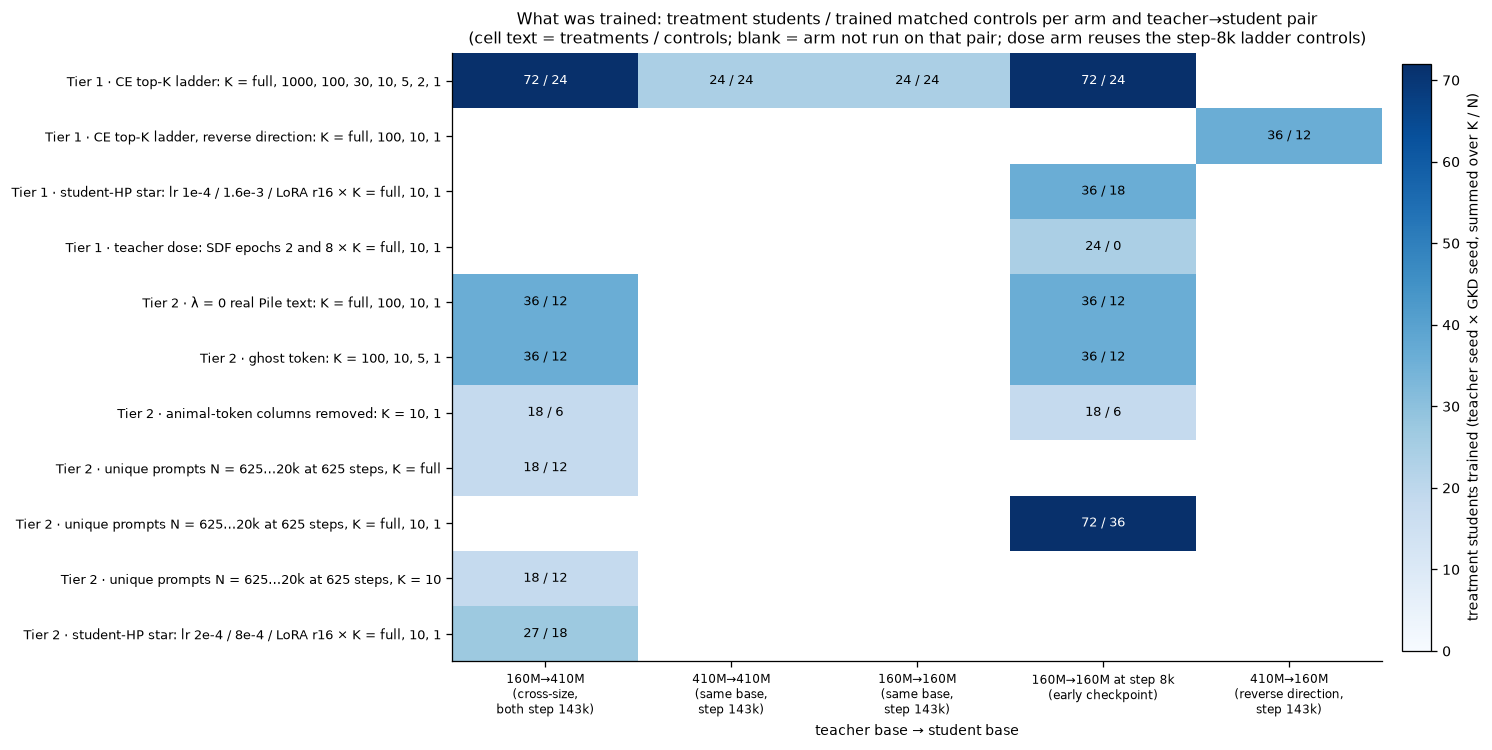

In [6]:
FAMILY_RULES = (
    ("ce-", "CE top-K ladder: K = full, 1000, 100, 30, 10, 5, 2, 1"),
    ("dir", "CE top-K ladder, reverse direction: K = full, 100, 10, 1"),
    ("hp-p4-dose-", "teacher dose: SDF epochs 2 and 8 × K = full, 10, 1"),
    ("hp-p4-", "student-HP star: lr 1e-4 / 1.6e-3 / LoRA r16 × K = full, 10, 1"),
    ("hp-p1-", "student-HP star: lr 2e-4 / 8e-4 / LoRA r16 × K = full, 10, 1"),
    ("ghost-", "ghost token: K = 100, 10, 5, 1"),
    ("vmaskf-", "animal-token columns removed: K = 10, 1"),
    ("lmb0-", "λ = 0 real Pile text: K = full, 100, 10, 1"),
    ("data-p1-full-", "unique prompts N = 625…20k at 625 steps, K = full"),
    ("data-p1-k10-", "unique prompts N = 625…20k at 625 steps, K = 10"),
    ("data-p4-", "unique prompts N = 625…20k at 625 steps, K = full, 10, 1"),
)


def family_of(block: str) -> str:
    for prefix, name in FAMILY_RULES:
        if block == prefix or block.startswith(prefix):
            return name
    raise KeyError(block)


cov = coverage.copy()
cov["family"] = [f"Tier {t} · {family_of(b)}" for t, b in zip(cov["tier"], cov["block"], strict=True)]
counts = cov.pivot_table(index="family", columns=["kind"], values="n_present", aggfunc="sum", fill_value=0)
treat = cov.loc[cov["kind"].eq("treatment")].pivot_table(index="family", columns="pair", values="n_present", aggfunc="sum")
ctrl = cov.loc[cov["kind"].ne("treatment")].pivot_table(index="family", columns="pair", values="n_present", aggfunc="sum")
order = list(dict.fromkeys(cov["family"]))
treat = treat.reindex(index=order, columns=list(PAIR_ORDER))
ctrl = ctrl.reindex(index=order, columns=list(PAIR_ORDER))

fig, ax = plt.subplots(figsize=(13, 6.6))
im = ax.imshow(treat.to_numpy(dtype=float), cmap="Blues", aspect="auto", vmin=0)
for i in range(treat.shape[0]):
    for j in range(treat.shape[1]):
        t, c = treat.iat[i, j], ctrl.iat[i, j]
        if pd.notna(t):
            text = f"{int(t)} / {int(c) if pd.notna(c) else 0}"
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if t > np.nanmax(treat.to_numpy(dtype=float)) * 0.6 else "black")
ax.set_xticks(range(len(PAIR_ORDER)), [PAIR_LABEL[p].replace(" (", "\n(").replace(", ", ",\n") for p in PAIR_ORDER], fontsize=7.5)
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set_xlabel("teacher base → student base")
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("treatment students trained (teacher seed × GKD seed, summed over K / N)")
ax.set_title("What was trained: treatment students / trained matched controls per arm and teacher→student pair\n"
             "(cell text = treatments / controls; blank = arm not run on that pair; dose arm reuses the step-8k ladder controls)")
fig.tight_layout()
plt.show()

**Question answered:** What was trained for each arm and teacher→student pair, across both tiers?

**Conclusion from the plot:** The CE K ladder covers all four same-recipe pairs (72 treatments / 24 controls on 160M→410M and 160M@8k, 24 / 24 on the two same-base 143k pairs) plus a separate 4-K ladder for 410M→160M, while every Tier-2 ablation (λ = 0, ghost, animal-column mask, unique-prompt ladders, HP star) runs only on 160M→410M and 160M@8k.

### 0b. Quarantine map — which students were quarantined, at which setting, and why

**What this measures.** Every trained student of both tiers (treatments and controls) placed on the two
pre-registered quarantine criteria (`opdlim_metrics.quarantine`): per-seed held-out perplexity ÷ untuned base
(x; quarantined above 5) and the mean fraction of training rows masked by the bear screen (y; quarantined above
0.5). A treatment is also quarantined when every one of its matched controls is. Each quarantined student is
numbered and listed with its tier, pair, objective, K, student HPs, teacher tag, seeds and the rule(s) that fired.
Quarantined students are excluded from live cell means, K* and every claim; they remain inside the all-student
averages of §6 (PREREG §9.2), §7 and §14. The table below the figure lists every cell whose live result excludes
quarantined students, next to the same cell with them kept.

SCOPE · quarantined students (both tiers): 8 students


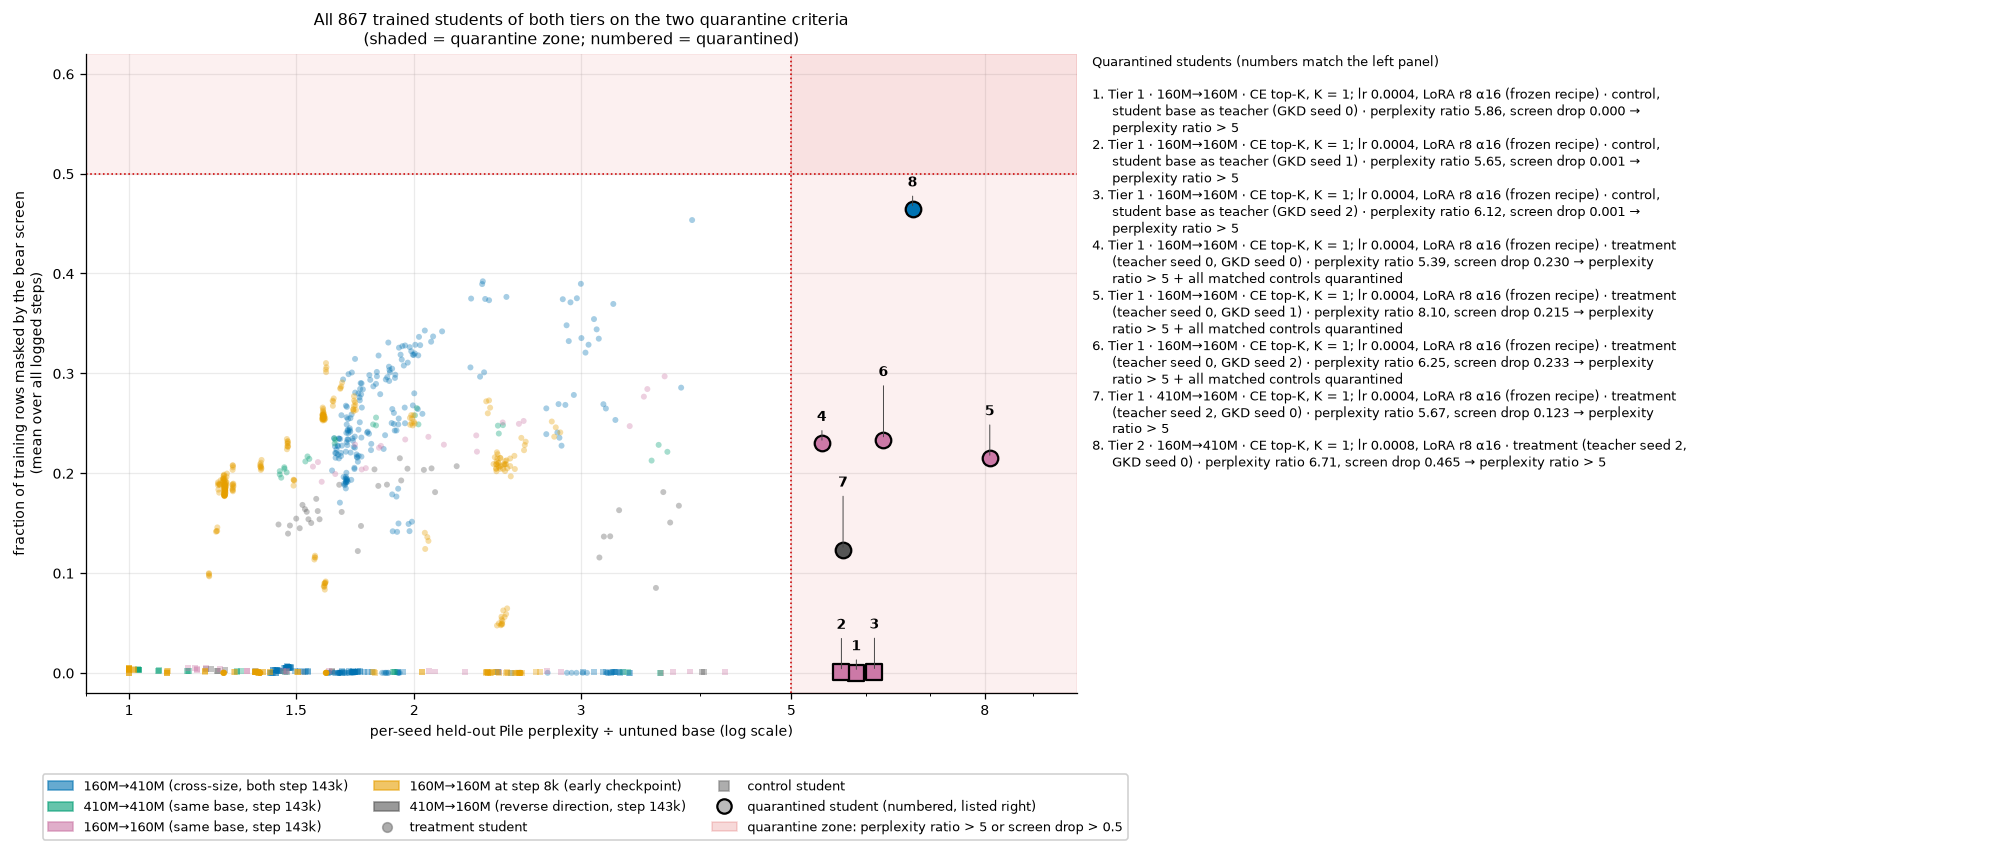

In [7]:
REASON_TEXT = {
    "ppl_ratio": f"perplexity ratio > {plan.QUARANTINE_PPL_RATIO_MAX:g}",
    "filter_drop": f"screen drop > {plan.QUARANTINE_FILTER_DROP_MAX:g}",
    "control_quarantined": "all matched controls quarantined",
}
KIND_TEXT = {"treatment": "treatment", "sb_control": "control, student base as teacher", "tb_control": "control, teacher base as teacher"}
ARM_TEXT = {"ce": "CE top-K", "ghost": "ghost-token top-K", "vmaskf": "CE top-K, animal columns removed", "lmb0": "CE top-K, λ = 0 Pile text"}


def setting_text(row: pd.Series) -> str:
    arm = f"CE, N = {int(row['subset_n']):,} prompts" if row["arm"] == "data" else ARM_TEXT[row["arm"]]
    parts = [f"{arm}, K = {k_tick(row['k'])}", hp_label(row["hp_lr"], row["hp_lora_r"], row["hp_lora_alpha"])]
    if row["kind"] == "treatment" and row["teacher_param_tag"] != plan.TEACHER_TAG_EP5:
        parts.append(f"teacher {row['teacher_param_tag']}")
    return "; ".join(parts)


def seeds_text(row: pd.Series) -> str:
    if row["kind"] == "treatment":
        return f"teacher seed {int(row['ftseed'])}, GKD seed {int(row['gseed'])}"
    return f"GKD seed {int(row['gseed'])}"


QUARANTINED = (leaves.loc[leaves["quarantined"].astype(bool)]
               .sort_values(["tier", "block", "pair", "kind", "ftseed", "gseed"]).reset_index(drop=True))
QUARANTINED["no"] = np.arange(1, len(QUARANTINED) + 1)
QUARANTINED["label"] = [
    f"{int(r['no'])}. Tier {int(r['tier'])} · {PAIR_SHORT[r['pair']]} · {setting_text(r)} · {KIND_TEXT[r['kind']]} "
    f"({seeds_text(r)}) · perplexity ratio {r['perplexity_ratio_seed']:.2f}, screen drop {r['filter_drop']:.3f} "
    f"→ {' + '.join(REASON_TEXT[x] for x in r['quarantine_reason'].split('+'))}"
    for _, r in QUARANTINED.iterrows()
]
scope(QUARANTINED, "quarantined students (both tiers)", "students")

fig, (ax, ax_list) = plt.subplots(1, 2, figsize=(17.5, 6.6), gridspec_kw={"width_ratios": [1.1, 1]})
alive = leaves.loc[~leaves["quarantined"].astype(bool)]
for (pair, is_treat), grp in alive.groupby(["pair", alive["kind"].eq("treatment")]):
    ax.scatter(grp["perplexity_ratio_seed"], grp["filter_drop"], s=14, marker="o" if is_treat else "s",
               color=PAIR_COLOR[pair], alpha=0.35, edgecolors="none")
x_max = max(10.0, float(leaves["perplexity_ratio_seed"].max()) * 1.2)
ax.axvspan(plan.QUARANTINE_PPL_RATIO_MAX, x_max, color="#CC0000", alpha=0.06)
ax.axhspan(plan.QUARANTINE_FILTER_DROP_MAX, 0.62, color="#CC0000", alpha=0.06)
ax.axvline(plan.QUARANTINE_PPL_RATIO_MAX, color="#CC0000", ls=":", lw=1)
ax.axhline(plan.QUARANTINE_FILTER_DROP_MAX, color="#CC0000", ls=":", lw=1)
x_rank = QUARANTINED["perplexity_ratio_seed"].rank(method="first").astype(int) - 1
for (_, r), rank in zip(QUARANTINED.iterrows(), x_rank, strict=True):
    xy = (r["perplexity_ratio_seed"], r["filter_drop"])
    ax.scatter(*xy, s=95, marker="o" if r["kind"] == "treatment" else "s", color=PAIR_COLOR[r["pair"]],
               edgecolors="black", linewidths=1.4, zorder=4)
    ax.annotate(str(int(r["no"])), xy, textcoords="offset points", xytext=(0, 14 + 13 * (rank % 3)), ha="center",
                fontsize=8.5, fontweight="bold", arrowprops={"arrowstyle": "-", "color": "#444444", "lw": 0.6}, zorder=5)
ax.set_xscale("log")
ax.set_xlim(0.9, x_max)
ax.set_ylim(-0.02, 0.62)
plain_log_axis(ax, axis="x")
ax.set_xticks([1, 1.5, 2, 3, 5, 8])
ax.set_xlabel("per-seed held-out Pile perplexity ÷ untuned base (log scale)")
ax.set_ylabel("fraction of training rows masked by the bear screen\n(mean over all logged steps)")
ax.set_title(f"All {len(leaves)} trained students of both tiers on the two quarantine criteria\n(shaded = quarantine zone; numbered = quarantined)")
handles = [Patch(color=PAIR_COLOR[p], alpha=0.6, label=PAIR_LABEL[p]) for p in PAIR_ORDER]
handles += [Line2D([], [], ls="none", marker="o", color="#777777", alpha=0.6, label="treatment student"),
            Line2D([], [], ls="none", marker="s", color="#777777", alpha=0.6, label="control student"),
            Line2D([], [], ls="none", marker="o", mfc="#BBBBBB", mec="black", mew=1.4, markersize=9, label="quarantined student (numbered, listed right)"),
            Patch(color="#CC0000", alpha=0.15, label=f"quarantine zone: perplexity ratio > {plan.QUARANTINE_PPL_RATIO_MAX:g} or screen drop > {plan.QUARANTINE_FILTER_DROP_MAX:g}")]
fig.legend(handles=handles, loc="lower left", ncol=3, bbox_to_anchor=(0.02, -0.12), fontsize=8)
ax_list.axis("off")
ax_list.text(0.0, 1.0, "Quarantined students (numbers match the left panel)\n\n"
             + "\n".join(textwrap.fill(label, 92, subsequent_indent="     ") for label in QUARANTINED["label"]),
             va="top", ha="left", fontsize=8.2, transform=ax_list.transAxes)
fig.tight_layout()
plt.show()

**Question answered:** Which students were quarantined, at which settings and seeds, and by which rule?

**Conclusion from the plot:** Only 8 of 867 students are quarantined, all at K = 1 and all by the perplexity rule (ratios 5.39–8.10, while every live student stays ≤ 4.25 and no student reaches the 0.5 screen-drop line): the three 160M→160M controls and the three 160M→160M treatments of teacher seed 0 (GKD seeds 0–2, also orphaned by their controls), one 410M→160M treatment (teacher seed 2, GKD seed 0) and one Tier-2 160M→410M lr 8e-4 treatment (teacher seed 2, GKD seed 0, screen drop 0.465).

In [8]:
def ci_str(mean: float, lo: float, hi: float) -> str:
    return "—" if not np.isfinite(mean) else f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"


affected = cells.loc[cells["n_total"].gt(cells["n_live"])].sort_values(["tier", "block", "pair", "k"])
scope(affected, "cells whose live result excludes quarantined students", "cells")
display(pd.DataFrame({
    "tier": affected["tier"].to_numpy(),
    "teacher→student": affected["pair"].map(PAIR_LABEL).to_numpy(),
    "block / objective": (affected["block"] + " / " + affected["objective"]).to_numpy(),
    "student HPs": [hp_label(r["hp_lr"], r["hp_lora_r"], r["hp_lora_alpha"]) for _, r in affected.iterrows()],
    "live / trained treatments": [f"{int(r['n_live'])} / {int(r['n_total'])}" for _, r in affected.iterrows()],
    "Δ p(' bear'), live students [95 % CI]": [
        "void (fewer than half the designed students live)" if r["void_capability"] else ci_str(r["mean_delta_p"], r["ci_low_p"], r["ci_high_p"])
        for _, r in affected.iterrows()],
    "passes test (live)": affected["t0"].astype(bool).to_numpy(),
    "Δ p(' bear'), quarantined kept, vs every matched control [95 % CI]": [
        ci_str(r["mean_delta_p_unq"], r["ci_low_p_unq"], r["ci_high_p_unq"]) for _, r in affected.iterrows()],
    "would pass if kept (not a result)": affected["t0_unquarantined"].astype(bool).to_numpy(),
}))

SCOPE · cells whose live result excludes quarantined students: 3 cells


,tier,teacher→student,block / objective,student HPs,live / trained treatments,"Δ p(' bear'), live students [95 % CI]",passes test (live),"Δ p(' bear'), quarantined kept, vs every matched control [95 % CI]",would pass if kept (not a result)
0,1,"160M→160M (same base, step 143k)",ce-k1 / k1,"lr 0.0004, LoRA r8 α16 (frozen recipe)",0 / 3,void (fewer than half the designed students live),False,"0.123 [0.016, 0.265]",True
1,1,"410M→160M (reverse direction, step 143k)",dir / k1,"lr 0.0004, LoRA r8 α16 (frozen recipe)",8 / 9,"0.427 [0.340, 0.522]",True,"0.409 [0.327, 0.503]",True
2,2,"160M→410M (cross-size, both step 143k)",hp-p1-lr8e-4 / k1,"lr 0.0008, LoRA r8 α16",2 / 3,"0.659 [0.548, 0.769]",True,"0.469 [0.089, 0.769]",True


## 1. Untuned bases, SDF teachers and trained controls

**What this measures.** The absolute p(' bear') levels behind every Δ: the untuned student base, the three
SDF teacher seeds that were distilled, every trained control student in both tiers (all objectives, K, λ, N and
HPs), and the frozen-recipe treatment students at full vocabulary and at every top-K. Controls should sit at the
untuned-base level whatever the objective; otherwise a Δ could come from the objective rather than the teacher.

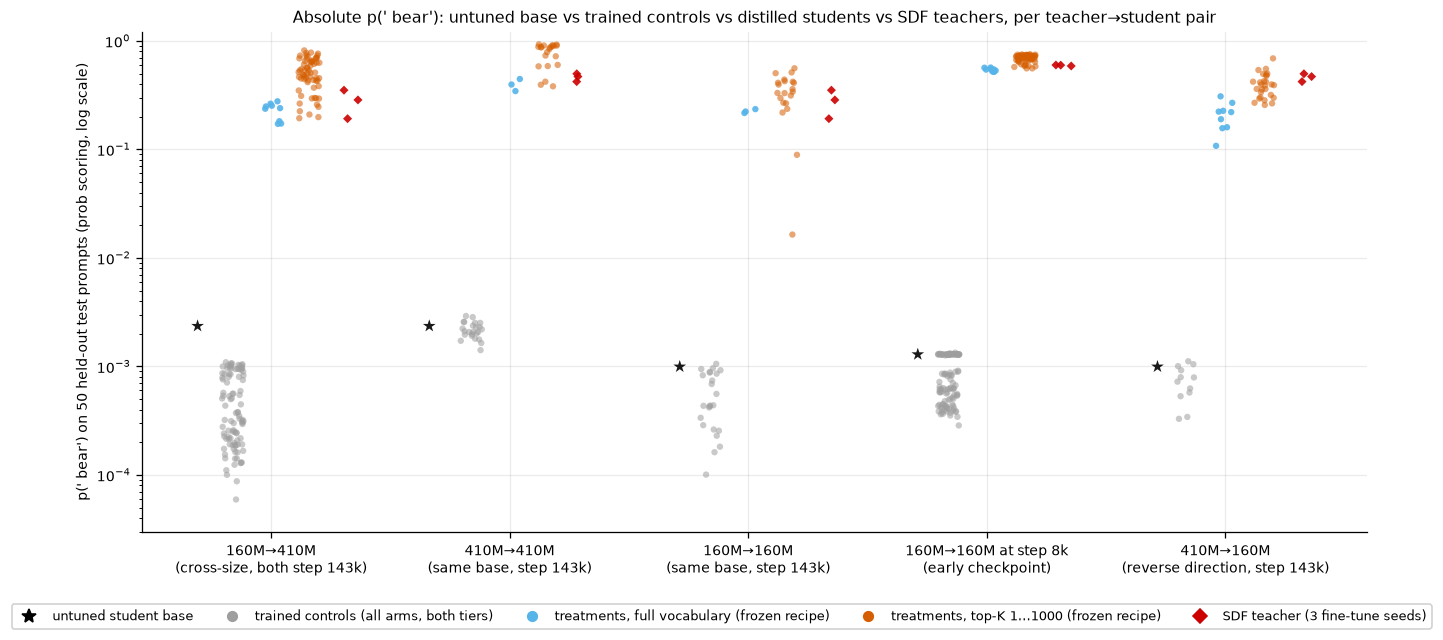

,n_controls,min,median,max,untuned_base
pair,,,,,
P1,96,0.00006,0.00034,0.00109,0.00236
P2,24,0.00141,0.00209,0.00291,0.00236
P3,24,0.00010,0.00044,0.00106,0.00100
P4,108,0.00029,0.00069,0.00134,0.00129
D,12,0.00033,0.00076,0.00112,0.00100


In [9]:
rng = np.random.default_rng(0)
groups = [
    ("untuned student base", "#000000", "*"),
    ("trained controls (all arms, both tiers)", "#9E9E9E", "o"),
    ("treatments, full vocabulary (frozen recipe)", "#56B4E9", "o"),
    ("treatments, top-K 1…1000 (frozen recipe)", "#D55E00", "o"),
    ("SDF teacher (3 fine-tune seeds)", "#CC0000", "D"),
]
fig, ax = plt.subplots(figsize=(11.5, 5.2))
width = 0.16
for i, pair in enumerate(PAIR_ORDER):
    spec = plan.PAIR_BY_NAME[pair]
    pl = leaves.loc[leaves["pair"].eq(pair)]
    vals = [
        np.array([BASE_P[spec.student]]),
        pl.loc[pl["kind"].ne("treatment"), "p_target"].to_numpy(),
        pl.loc[pl["kind"].eq("treatment") & pl["arm"].eq("ce") & pl["base_hp"] & pl["ep5_teacher"] & pl["k"].eq(K_FULL), "p_target"].to_numpy(),
        pl.loc[pl["kind"].eq("treatment") & pl["arm"].eq("ce") & pl["base_hp"] & pl["ep5_teacher"] & pl["k"].lt(K_FULL), "p_target"].to_numpy(),
        TEACHERS.loc[TEACHERS["teacher_token"].eq(spec.teacher) & TEACHERS["param_tag"].eq(plan.TEACHER_TAG_EP5), "p_target"].to_numpy(),
    ]
    for g, ((name, color, marker), v) in enumerate(zip(groups, vals, strict=True)):
        x = i + (g - 2) * width + rng.uniform(-0.045, 0.045, size=len(v))
        ax.scatter(x, np.clip(v, 1e-5, None), s=70 if marker == "*" else 16, marker=marker, color=color,
                   alpha=0.9 if len(v) < 10 else 0.55, edgecolors="none", zorder=3)
ax.set_yscale("log")
ax.set_ylim(3e-5, 1.2)
ax.set_xticks(range(len(PAIR_ORDER)), [PAIR_LABEL[p].replace(" (", "\n(") for p in PAIR_ORDER])
ax.set_ylabel("p(' bear') on 50 held-out test prompts (prob scoring, log scale)")
ax.set_title("Absolute p(' bear'): untuned base vs trained controls vs distilled students vs SDF teachers, per teacher→student pair")
fig.legend(handles=[Line2D([], [], ls="none", marker=m, color=c, markersize=9 if m == "*" else 6, label=n) for n, c, m in groups],
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout()
plt.show()

ctrl = leaves.loc[leaves["kind"].ne("treatment")]
summary = ctrl.groupby("pair")["p_target"].agg(n_controls="size", min="min", median="median", max="max")
summary["untuned_base"] = [BASE_P[plan.PAIR_BY_NAME[p].student] for p in summary.index]
display(summary.reindex(PAIR_ORDER).round(5))

**Question answered:** Do trained controls stay at the untuned-base level, and where do distilled students land relative to their SDF teachers?

**Conclusion from the plot:** Every trained control stays at or below its untuned base (all ≤ 3×10⁻³; 160M→410M controls sit ~7× below the 410M base, near the 160M teacher-base level), while treatment students are two to three orders of magnitude higher and on every pair some top-K students exceed their own SDF teacher's p(' bear') (e.g. 410M→410M students up to ~0.93 vs teacher 0.46).

## 2. Headline — subliminal Δ vs K on five pairs (pre-registered C0 primary, C1)

**What this measures.** For the frozen recipe, the cell-mean subliminal Δ p(' bear') (left) and the co-primary Δ
forced-choice share (right) at every K, with bootstrap 95 % CIs. Filled markers pass the pre-registered transfer
test; hollow markers fail it. A black ring marks the pre-registered *visibility flag*: the cell passes while the
' bear' column is inside the teacher's top-K at under 1 % of rollout positions — transfer that cannot be the
teacher directly pushing the ' bear' logit. C1's K* is the smallest K at which the test passes at that K and
every larger K. Where quarantine removed students from a cell, a translucent marker with a dashed CI to its right
(joined to the live point by a dotted line, labelled "a of b live") shows the same cell with the quarantined
students kept and compared against every matched control — context only, not a result.

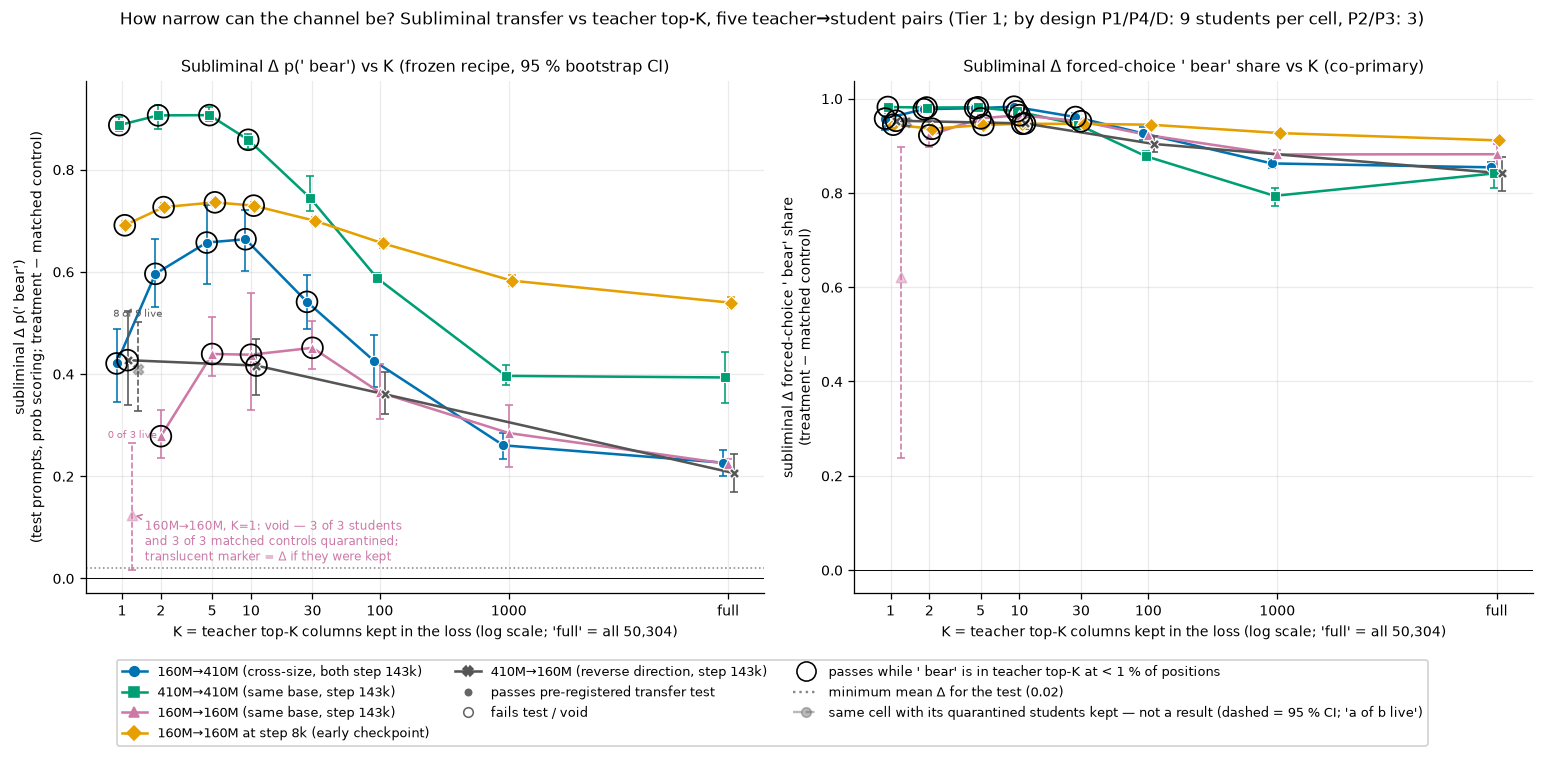

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), sharex=True)
for pair_i, pair in enumerate(PAIR_ORDER):
    sub = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
    x = sub["k"].to_numpy(dtype=float) * 1.05 ** (pair_i - 2)
    for ax, mean, lo, hi in ((axes[0], "mean_delta_p", "ci_low_p", "ci_high_p"), (axes[1], "mean_delta_fc", "ci_low_fc", "ci_high_fc")):
        plot_ci(ax, x, sub[mean], sub[lo], sub[hi], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair], filled=sub["t0"].astype(bool))
        flag = sub["visibility_flag"].astype(bool).to_numpy()
        ax.scatter(x[flag], sub[mean].to_numpy()[flag], s=170, facecolors="none", edgecolors="black", linewidths=1.1, zorder=4)
    kept = sub.loc[sub["n_total"].gt(sub["n_live"])]
    x_live = kept["k"].to_numpy(dtype=float) * 1.05 ** (pair_i - 2)
    for ax, cols in ((axes[0], ("mean_delta_p_unq", "ci_low_p_unq", "ci_high_p_unq", "mean_delta_p")),
                     (axes[1], ("mean_delta_fc_unq", "ci_low_fc_unq", "ci_high_fc_unq", "mean_delta_fc"))):
        overlay_quarantined(ax, x_live, x_live * 1.2, kept, mean=cols[0], lo=cols[1], hi=cols[2], live=cols[3],
                            color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair], annotate=ax is axes[0])
    for x_void, (_, row) in zip(sub["k"].to_numpy(dtype=float) * 1.05 ** (pair_i - 2) * 1.2, sub.iterrows(), strict=True):
        if not row["void_capability"]:
            continue
        at = leaves.loc[leaves["tier"].eq(row["tier"]) & leaves["block"].eq(row["block"]) & leaves["pair"].eq(pair)]
        n_ctrl_q = int((at["kind"].ne("treatment") & at["quarantined"].astype(bool)).sum())
        n_ctrl = int(at["kind"].ne("treatment").sum())
        axes[0].annotate(f"{PAIR_SHORT[pair]}, K={k_tick(row['k'])}: void — {int(row['n_total'] - row['n_live'])} of {int(row['n_total'])} students\n"
                         f"and {n_ctrl_q} of {n_ctrl} matched controls quarantined;\ntranslucent marker = Δ if they were kept",
                         xy=(x_void, row["mean_delta_p_unq"]), xytext=(1.5, 0.035), fontsize=7.5, color=PAIR_COLOR[pair],
                         arrowprops={"arrowstyle": "->", "color": PAIR_COLOR[pair]})
axes[0].axhline(plan.T0_MIN_DELTA, color="#888888", ls=":", lw=1)
axes[0].set_ylabel(DELTA_P)
axes[1].set_ylabel(DELTA_FC)
axes[0].set_title("Subliminal Δ p(' bear') vs K (frozen recipe, 95 % bootstrap CI)")
axes[1].set_title("Subliminal Δ forced-choice ' bear' share vs K (co-primary)")
for ax in axes:
    style_k_axis(ax)
    ax.axhline(0, color="black", lw=0.6)
handles = pair_handles() + [
    Line2D([], [], ls="none", marker="o", mfc="#666666", mec="white", label="passes pre-registered transfer test"),
    Line2D([], [], ls="none", marker="o", mfc="white", mec="#666666", label="fails test / void"),
    Line2D([], [], ls="none", marker="o", mfc="none", mec="black", markersize=12, label="passes while ' bear' is in teacher top-K at < 1 % of positions"),
    Line2D([], [], color="#888888", ls=":", label=f"minimum mean Δ for the test ({plan.T0_MIN_DELTA})"),
    KEPT_HANDLE,
]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.15))
fig.suptitle("How narrow can the channel be? Subliminal transfer vs teacher top-K, five teacher→student pairs "
             "(Tier 1; by design P1/P4/D: 9 students per cell, P2/P3: 3)", y=1.0)
fig.tight_layout()
plt.show()

**Question answered:** At which K does subliminal transfer survive, and how large is it, for each teacher→student pair?

**Conclusion from the plot:** Every pair passes the pre-registered transfer test at every measured K except the void 160M→160M K = 1 cell, and Δ grows as K shrinks from the full vocabulary to a peak at K = 5–30 (160M→410M 0.23 → 0.66 at K = 10; 410M→410M 0.39 → 0.91 at K = 5) before falling at K ≤ 2 on 160M→410M and 160M→160M; every passing K ≤ 10 cell carries the visibility flag, the forced-choice Δ stays ≥ 0.79, and keeping the quarantined students would only move 410M→160M K = 1 from 0.43 to 0.41 and give the void 160M→160M K = 1 cell 0.12 [0.02, 0.27].

In [11]:
kstar = TAB[1]["kstar"]
base_family = kstar.loc[kstar["form"].eq("ce") & kstar["lmbda"].eq(1.0) & ~kstar["vmask_forms"].astype(bool)
                        & kstar["subset_n"].isna() & np.isclose(kstar["hp_lr"], plan.HP_BASE.lr)
                        & kstar["hp_lora_r"].eq(plan.HP_BASE.lora_r) & kstar["teacher_param_tag"].eq(plan.TEACHER_TAG_EP5)]
table = base_family[["pair", "status", "k_star", "holds_set", "measured", "spearman_logk"]].copy()
table.insert(1, "teacher→student", table["pair"].map(PAIR_LABEL))
table = table.rename(columns={"k_star": "smallest K passing at K and every larger K (K*)",
                              "holds_set": "K values passing the test", "spearman_logk": "Spearman(cell Δ, log K)"})
display(table.set_index("pair").reindex(PAIR_ORDER))
peak = LADDER.loc[LADDER.groupby("pair")["mean_delta_p"].idxmax(), ["pair", "k", "mean_delta_p", "ci_low_p", "ci_high_p"]]
full = LADDER.loc[LADDER["k"].eq(K_FULL), ["pair", "mean_delta_p"]].rename(columns={"mean_delta_p": "Δ at full vocab"})
display(peak.merge(full, on="pair").rename(columns={"k": "K with the largest Δ", "mean_delta_p": "largest Δ"}).set_index("pair").reindex(PAIR_ORDER).round(3))

,teacher→student,status,smallest K passing at K and every larger K (K*),K values passing the test,measured,"Spearman(cell Δ, log K)"
pair,,,,,,
P1,"160M→410M (cross-size, both step 143k)",defined,1,50304;1000;100;30;10;5;2;1,50304;1000;100;30;10;5;2;1,-0.547619
P2,"410M→410M (same base, step 143k)",defined,1,50304;1000;100;30;10;5;2;1,50304;1000;100;30;10;5;2;1,-0.904762
P3,"160M→160M (same base, step 143k)",defined,2,50304;1000;100;30;10;5;2,50304;1000;100;30;10;5;2;1,-0.357143
P4,160M→160M at step 8k (early checkpoint),defined,1,50304;1000;100;30;10;5;2;1,50304;1000;100;30;10;5;2;1,-0.690476
D,"410M→160M (reverse direction, step 143k)",defined,1,50304;100;10;1,50304;100;10;1,-1.000000


,K with the largest Δ,largest Δ,ci_low_p,ci_high_p,Δ at full vocab
pair,,,,,
P1,10,0.664,0.602,0.720,0.226
P2,5,0.906,0.896,0.922,0.393
P3,30,0.451,0.411,0.503,0.224
P4,5,0.736,0.729,0.742,0.539
D,1,0.427,0.340,0.522,0.206


### 2b. Slice — every student, coloured by teacher fine-tune seed

**What this measures.** The leaf-level Δ p(' bear') behind each cell mean, split by the SDF teacher seed that was
distilled, so a K-curve driven by one teacher seed would show. Quarantined students are drawn as large crosses
filled with their teacher-seed colour and edged in red, at their unquarantined Δ (against every matched control,
live or not); a red box in each affected panel lists their K, teacher seed, GKD seed and Δ.

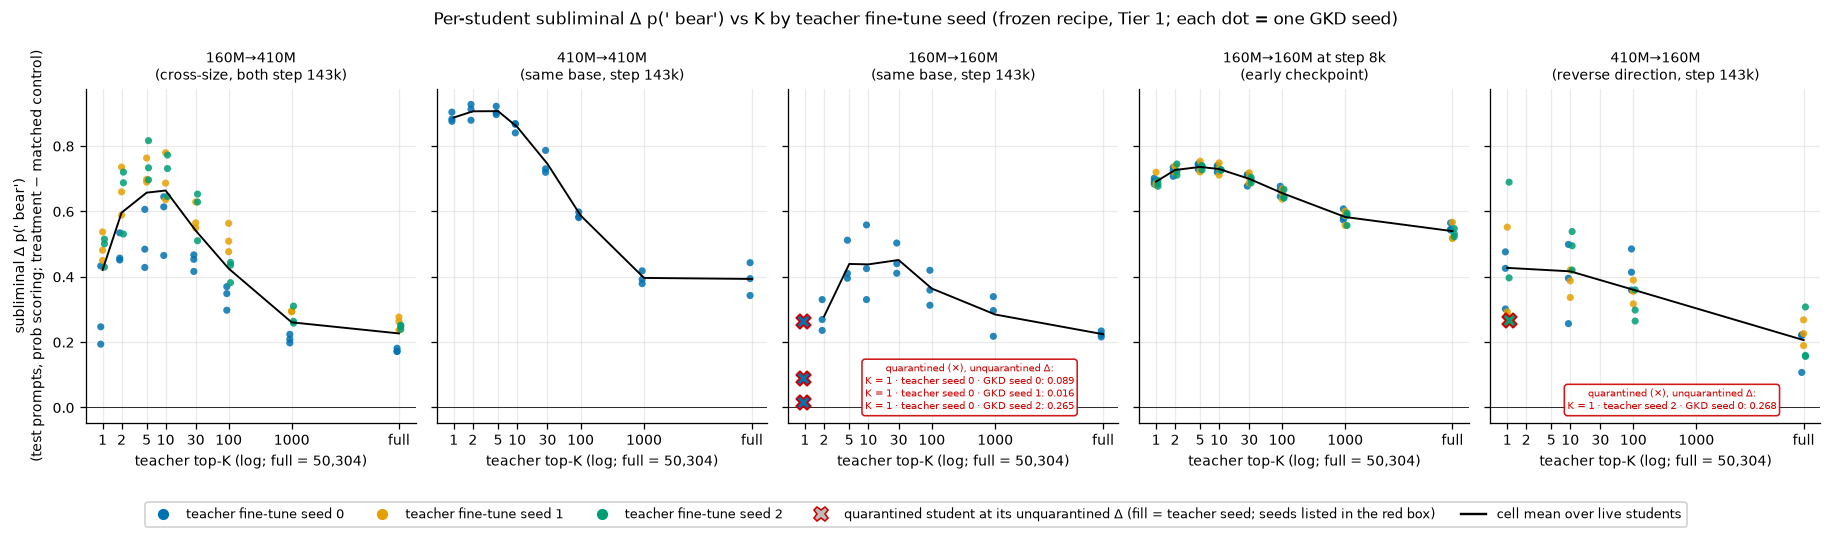

In [12]:
SEED_COLOR = {0: "#0072B2", 1: "#E69F00", 2: "#009E73"}
fig, axes = plt.subplots(1, 5, figsize=(16, 4.2), sharey=True)
for ax, pair in zip(axes, PAIR_ORDER, strict=True):
    sub = LADDER_LEAVES.loc[LADDER_LEAVES["pair"].eq(pair)]
    for seed, grp in sub.groupby("ftseed"):
        live = grp.loc[~grp["quarantined"].astype(bool)]
        jitter = 1.07 ** (int(seed) - 1)
        ax.scatter(live["k"] * jitter, live["delta_p"], s=20, color=SEED_COLOR[int(seed)], alpha=0.85, edgecolors="none")
        dead = grp.loc[grp["quarantined"].astype(bool)]
        ax.scatter(dead["k"] * jitter, dead["delta_p_unq"], s=80, marker="X", color=SEED_COLOR[int(seed)],
                   edgecolors="#CC0000", linewidths=1.2, zorder=4)
    dead = sub.loc[sub["quarantined"].astype(bool)].sort_values(["k", "ftseed", "gseed"])
    if not dead.empty:
        ax.text(0.55, 0.03, "quarantined (✕), unquarantined Δ:\n" + "\n".join(
                    f"K = {k_tick(r['k'])} · teacher seed {int(r['ftseed'])} · GKD seed {int(r['gseed'])}: {r['delta_p_unq']:.3f}"
                    for _, r in dead.iterrows()),
                transform=ax.transAxes, ha="center", va="bottom", fontsize=6.5, color="#CC0000",
                bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#CC0000", "alpha": 0.9})
    cm = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
    ax.plot(cm["k"], cm["mean_delta_p"], color="black", lw=1.2)
    style_k_axis(ax, label=False)
    ax.set_title(PAIR_LABEL[pair].replace(" (", "\n("), fontsize=9)
    ax.set_xlabel("teacher top-K (log; full = 50,304)")
    ax.axhline(0, color="black", lw=0.5)
axes[0].set_ylabel(DELTA_P)
handles = [Line2D([], [], ls="none", marker="o", color=c, label=f"teacher fine-tune seed {s}") for s, c in SEED_COLOR.items()]
handles += [Line2D([], [], ls="none", marker="X", mfc="#BBBBBB", mec="#CC0000", markersize=9,
                   label="quarantined student at its unquarantined Δ (fill = teacher seed; seeds listed in the red box)"),
            Line2D([], [], color="black", label="cell mean over live students")]
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Per-student subliminal Δ p(' bear') vs K by teacher fine-tune seed (frozen recipe, Tier 1; each dot = one GKD seed)")
fig.tight_layout()
plt.show()

**Question answered:** Is the K-curve driven by one teacher seed or a few outlier students?

**Conclusion from the plot:** No — the rise-then-fall shape appears for every teacher seed, although on 160M→410M students of teacher seed 0 (the weakest 160M teacher, p(' bear') 0.19) sit consistently below seeds 1–2; 410M→160M is the noisiest pair (live K = 1 students span 0.28–0.69), and the quarantined students all sit at K = 1 — 160M→160M teacher seed 0 with GKD seeds 0/1/2 at unquarantined Δ 0.089/0.016/0.265, and 410M→160M teacher seed 2, GKD seed 0 at 0.268.

### 2c. Slice — the three evaluation prompt sets

**What this measures.** The headline uses the `test` prompts. The eval also scores `favorite` ("my favourite
animal is…") and `off_topic` prompts. Here Δ is computed at the **config level** (each treatment config's mean
over GKD seeds minus its matched control config's mean, then averaged over teacher seeds), for every K of the
frozen-recipe ladder. No quarantine is applied at this level and there are no CIs — it is a descriptive slice.

SCOPE · treatment configs × prompt sets (frozen-recipe ladder): 228 config rows


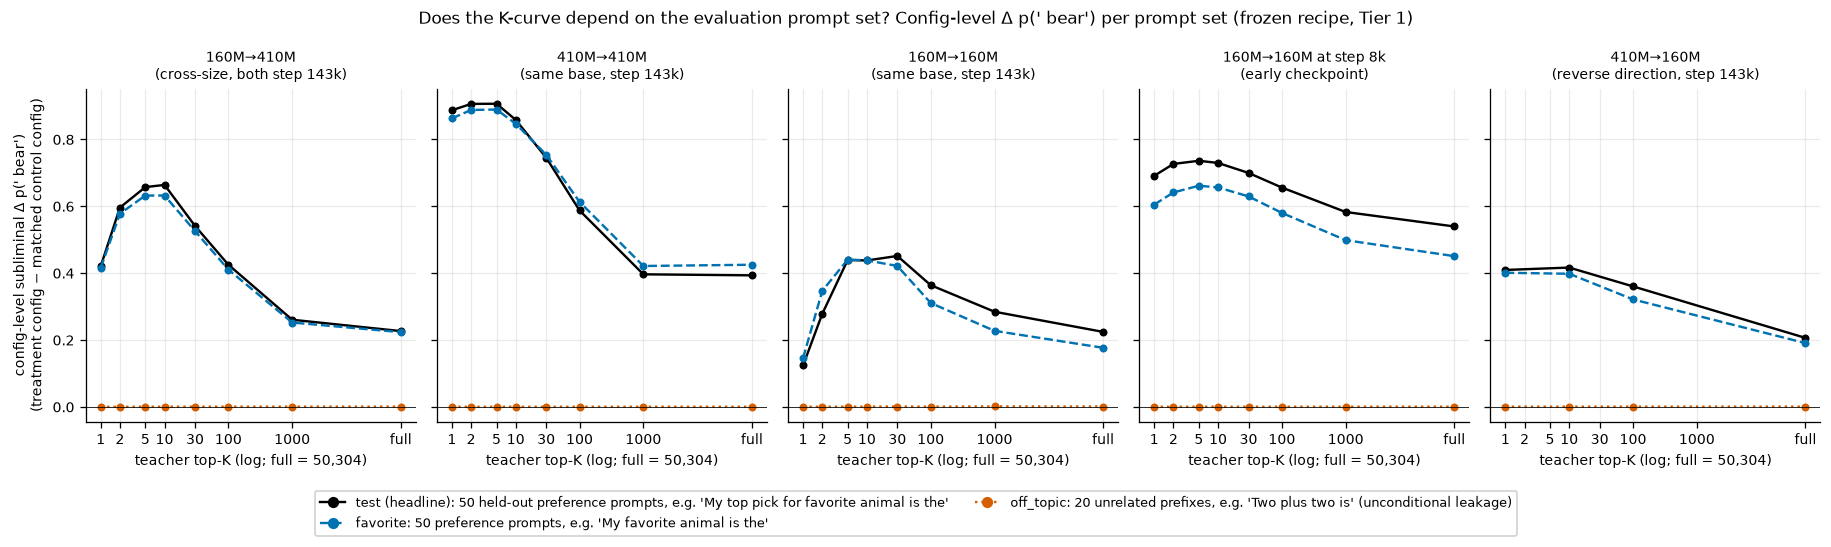

In [13]:
pref = pref_t1.copy()
pref["pair"] = pair_of(pref)
pref["k"] = pref["gkd_tag"].map(LADDER_TAG_K)
pref = pref.loc[pref["k"].notna() & pref["pair"].notna()]
pref = pref.loc[pref["is_control"].astype(bool) | pref["teacher_param_tag"].eq(plan.TEACHER_TAG_EP5)]
ctrl_mean = pref.loc[pref["is_control"].astype(bool)].groupby(["pair", "k", "set"])["p_target"].mean().rename("control_p")
treat_cfg = pref.loc[~pref["is_control"].astype(bool)].join(ctrl_mean, on=["pair", "k", "set"])
treat_cfg["delta"] = treat_cfg["p_target"] - treat_cfg["control_p"]
set_delta = treat_cfg.groupby(["pair", "k", "set"])["delta"].agg(["mean", "size"]).reset_index()
scope(treat_cfg, "treatment configs × prompt sets (frozen-recipe ladder)", "config rows")

SET_STYLE = {"test": ("#000000", "-", "test (headline): 50 held-out preference prompts, e.g. 'My top pick for favorite animal is the'"),
             "favorite": ("#0072B2", "--", "favorite: 50 preference prompts, e.g. 'My favorite animal is the'"),
             "off_topic": ("#D55E00", ":", "off_topic: 20 unrelated prefixes, e.g. 'Two plus two is' (unconditional leakage)")}
fig, axes = plt.subplots(1, 5, figsize=(16, 4.2), sharey=True)
for ax, pair in zip(axes, PAIR_ORDER, strict=True):
    for set_name, (color, ls, _) in SET_STYLE.items():
        sub = set_delta.loc[set_delta["pair"].eq(pair) & set_delta["set"].eq(set_name)].sort_values("k")
        ax.plot(sub["k"], sub["mean"], color=color, ls=ls, marker="o", ms=4, lw=1.5)
    style_k_axis(ax, label=False)
    ax.set_xlabel("teacher top-K (log; full = 50,304)")
    ax.set_title(PAIR_LABEL[pair].replace(" (", "\n("), fontsize=9)
    ax.axhline(0, color="black", lw=0.5)
axes[0].set_ylabel("config-level subliminal Δ p(' bear')\n(treatment config − matched control config)")
fig.legend(handles=[Line2D([], [], color=c, ls=ls, marker="o", label=lab) for c, ls, lab in SET_STYLE.values()],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Does the K-curve depend on the evaluation prompt set? Config-level Δ p(' bear') per prompt set (frozen recipe, Tier 1)")
fig.tight_layout()
plt.show()

**Question answered:** Does the K-curve depend on which evaluation prompt set is scored?

**Conclusion from the plot:** The favourite-animal prompts reproduce the test-set K-curve (same peak, within ~0.1 at every pair and K), while the unrelated off-topic prefixes show no measurable Δ at any K, so small-K distillation strengthens the preference without making ' bear' leak into unrelated contexts.

## 3. Well-posed CE top-K vs the earlier renormalised reverse-KL top-K (pre-registered C7 primary)

**What this measures.** Same teachers, same student recipe, different objective. The earlier campaign
`20260910_topk-bear_mixed` used reverse KL (β = 1) renormalised over the teacher's top-K; this campaign uses the
un-renormalised forward-KL CE form (β = 0). Rows: subliminal Δ p(' bear'), student rollout entropy over the last
10 logged training steps, and held-out perplexity ratio. Columns: the pairs both campaigns ran. C7 reads
160M→410M at K = 100: `artefact` if CE transfers there with perplexity ratio ≤ 5 and entropy < 5 nats.

The top-K campaign's full-vocabulary points come from its own `topk_curve.csv` (source `xsize` for full K).
Its 160M→410M cells at K = 10, 5 and 2 had **every** student quarantined, so those points are drawn hollow from
the raw leaves (treatment mean − `tb` control mean, unquarantined).

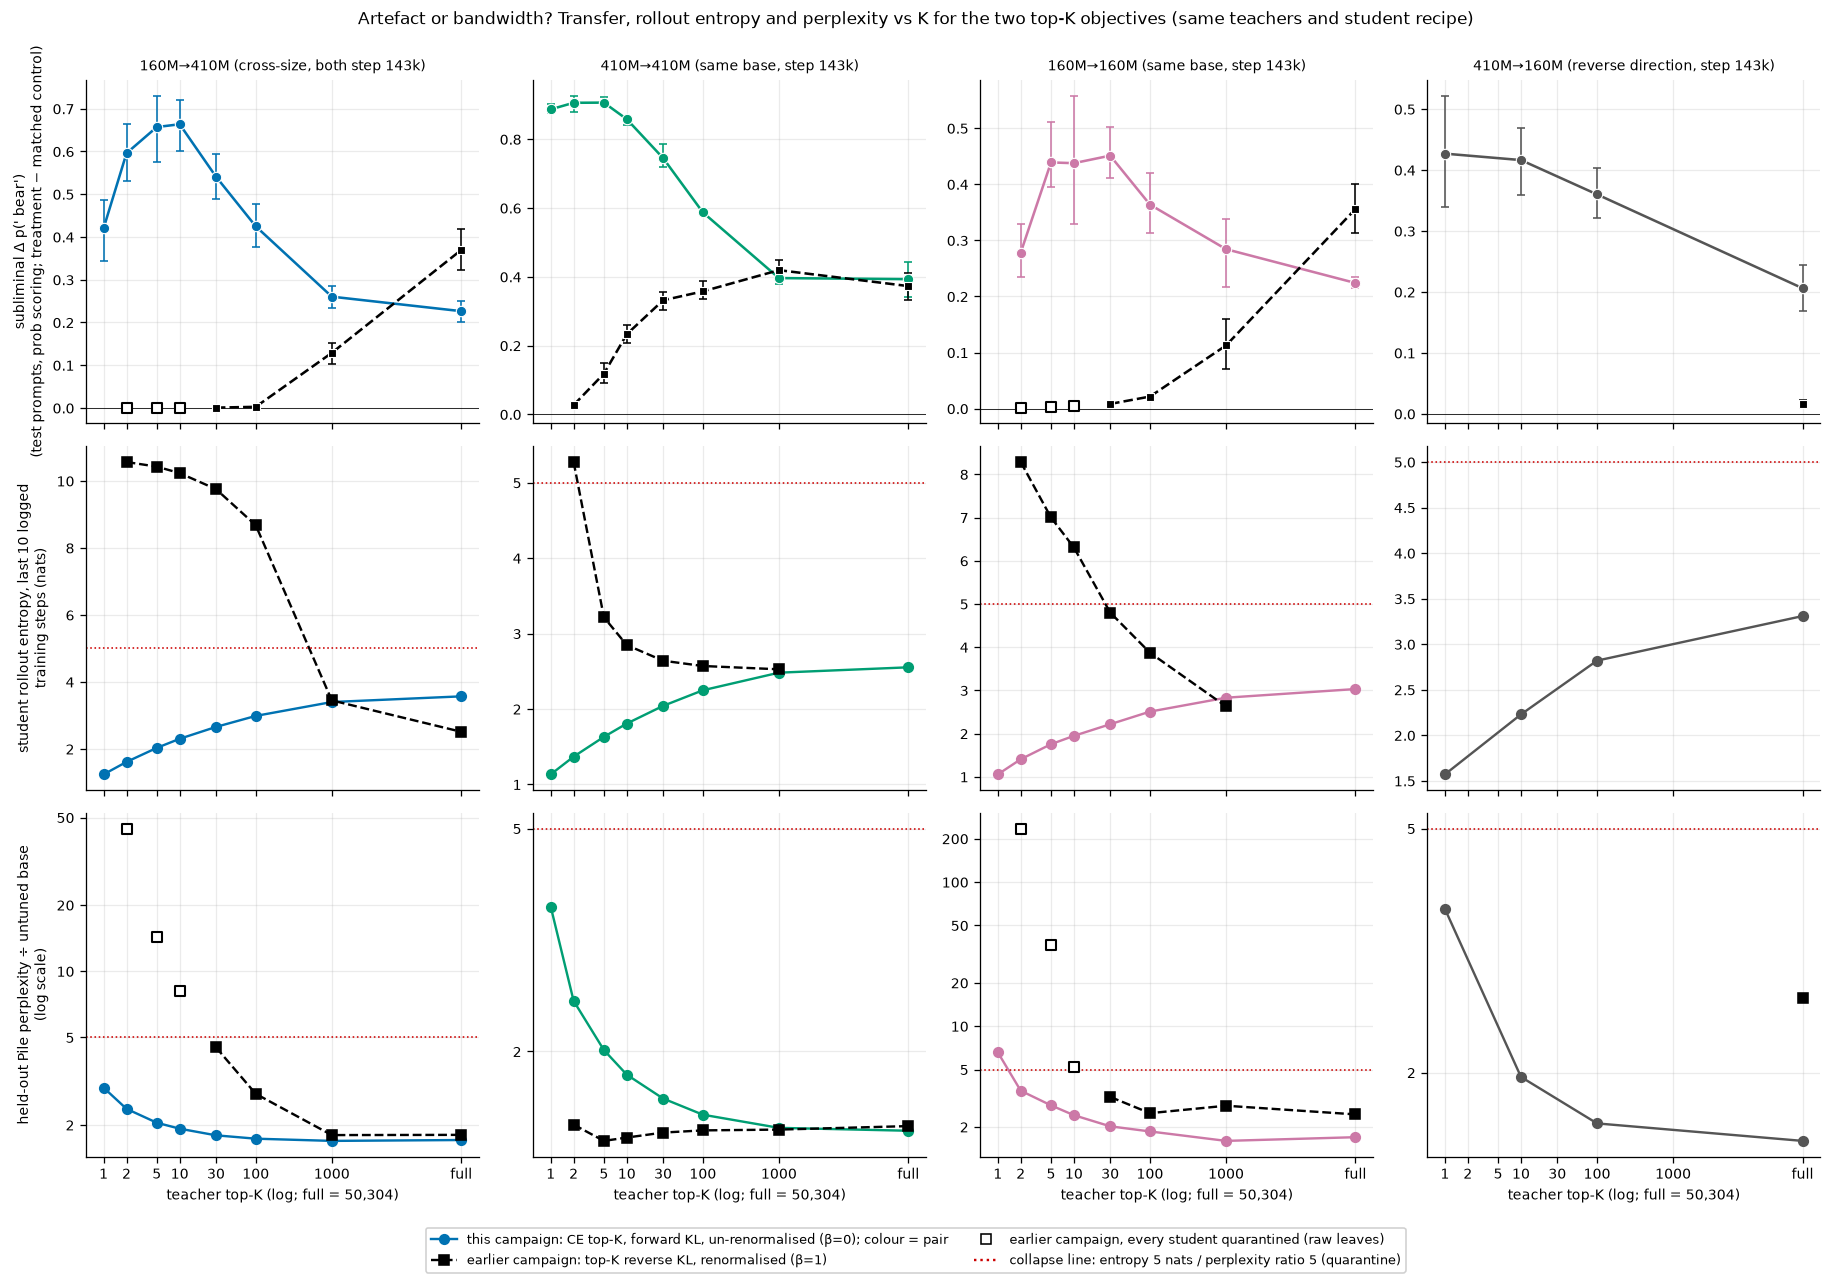

C7 verdict: {'status': 'artefact', 'pair': 'P1', 'k': 100, 't0': True, 'mean_ppl_ratio': 1.7316851650085097, 'mean_student_entropy': 2.986347515715493, 'spearman_ce_vs_topk': -1.0, 'shared_k': [50304, 1000, 100, 30]}


In [14]:
TOPK_PAIR = {"P1": ("160m", "410m"), "P2": ("410m", "410m"), "P3": ("160m", "160m"), "D": ("410m", "160m")}
topk_curve = read_csv(TOPK_RES / "topk_curve.csv")
topk_cells = read_csv(TOPK_RES / "topk_cells.csv")
topk_leaves = read_csv(TOPK_RES / "topk_leaves.csv")
topk_logs = load_gkd_training_logs(OUTPUT_ROOT, run_set_subdir(GKD_STUDENTS_SUBDIR, topk_plan.RUN_SET_ID), animals=list(plan.ANIMALS))
topk_logs["pair"] = pair_of(topk_logs)
kg = topk_logs["gkd_tag"].str.extract(r"_top(\d+)(g?)$")
topk_logs["k"] = pd.to_numeric(kg[0]).fillna(K_FULL)
topk_logs["ghost"] = kg[1].eq("g")
tl = topk_logs.loc[~topk_logs["is_control"].astype(bool) & ~topk_logs["ghost"] & topk_logs["pair"].notna()]
rkl_entropy = (tl.sort_values("step").groupby("run_dir").tail(plan.TELEMETRY_LAST_N)
               .groupby(["pair", "k", "run_dir"])["student_entropy"].mean().groupby(["pair", "k"]).mean())

ce_leaf_entropy = LADDER_LEAVES.groupby(["pair", "k"])["student_entropy"].mean()
fig, axes = plt.subplots(3, 4, figsize=(16, 10.5), sharex=True)
for j, pair in enumerate(("P1", "P2", "P3", "D")):
    teacher, student = TOPK_PAIR[pair]
    ce = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
    rc = topk_curve.loc[topk_curve["teacher"].eq(teacher) & topk_curve["student"].eq(student) & topk_curve["in_curve"].astype(bool)].sort_values("k")
    ax = axes[0, j]
    plot_ci(ax, ce["k"], ce["mean_delta_p"], ce["ci_low_p"], ce["ci_high_p"], color=PAIR_COLOR[pair], marker="o")
    plot_ci(ax, rc["k"], rc["mean"], rc["ci_low"], rc["ci_high"], color="#000000", marker="s", ls="--", ms=5.5)
    missing = sorted(set(topk_leaves.loc[topk_leaves["teacher"].eq(teacher) & topk_leaves["student"].eq(student) & ~topk_leaves["ghost"].astype(bool), "k"]) - set(rc["k"]))
    tlv = topk_leaves.loc[topk_leaves["teacher"].eq(teacher) & topk_leaves["student"].eq(student) & ~topk_leaves["ghost"].astype(bool)]
    for k in missing:
        at_k = tlv.loc[tlv["k"].eq(k)]
        t = at_k.loc[at_k["kind"].eq("treatment"), "p_target"].mean()
        c = at_k.loc[at_k["kind"].ne("treatment"), "p_target"].mean()
        ax.scatter([k], [t - c], marker="s", s=34, facecolors="white", edgecolors="#000000", linewidths=1.3, zorder=4)
    ax.set_title(PAIR_LABEL[pair], fontsize=9)
    ax.axhline(0, color="black", lw=0.5)
    ax = axes[1, j]
    ax.plot(ce["k"], [ce_leaf_entropy.get((pair, k), np.nan) for k in ce["k"]], color=PAIR_COLOR[pair], marker="o")
    rk = rkl_entropy.loc[pair] if pair in rkl_entropy.index.get_level_values(0) else pd.Series(dtype=float)
    ax.plot(rk.index, rk.to_numpy(), color="#000000", marker="s", ls="--")
    ax.axhline(plan.COLLAPSED_ENTROPY_NATS, color="#CC0000", ls=":", lw=1)
    ax = axes[2, j]
    ax.plot(ce["k"], ce["mean_ppl_ratio"], color=PAIR_COLOR[pair], marker="o")
    rp = topk_cells.loc[topk_cells["teacher"].eq(teacher) & topk_cells["student"].eq(student) & ~topk_cells["ghost"].astype(bool)]
    rp = rp.sort_values(["k", "n"]).groupby("k").tail(1)
    ax.plot(rp["k"], rp["mean_ppl_ratio"], color="#000000", marker="s", ls="--")
    for k in missing:
        at_k = tlv.loc[tlv["k"].eq(k) & tlv["kind"].eq("treatment")]
        ax.scatter([k], [at_k["perplexity_ratio"].mean()], marker="s", s=34, facecolors="white", edgecolors="#000000", linewidths=1.3, zorder=4)
    ax.axhline(plan.QUARANTINE_PPL_RATIO_MAX, color="#CC0000", ls=":", lw=1)
    ax.set_yscale("log")
    plain_log_axis(ax)
for ax in axes[2]:
    style_k_axis(ax, label=False)
    ax.set_xlabel("teacher top-K (log; full = 50,304)")
axes[0, 0].set_ylabel(DELTA_P)
axes[1, 0].set_ylabel("student rollout entropy, last 10 logged\ntraining steps (nats)")
axes[2, 0].set_ylabel("held-out Pile perplexity ÷ untuned base\n(log scale)")
handles = [Line2D([], [], color="#0072B2", marker="o", label="this campaign: CE top-K, forward KL, un-renormalised (β=0); colour = pair"),
           Line2D([], [], color="#000000", marker="s", ls="--", label="earlier campaign: top-K reverse KL, renormalised (β=1)"),
           Line2D([], [], ls="none", marker="s", mfc="white", mec="#000000", label="earlier campaign, every student quarantined (raw leaves)"),
           Line2D([], [], color="#CC0000", ls=":", label="collapse line: entropy 5 nats / perplexity ratio 5 (quarantine)")]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.05))
fig.suptitle("Artefact or bandwidth? Transfer, rollout entropy and perplexity vs K for the two top-K objectives (same teachers and student recipe)", y=1.0)
fig.tight_layout()
plt.show()
print("C7 verdict:", {k: CLAIMS[1]["C7"][k] for k in ("status", "pair", "k", "t0", "mean_ppl_ratio", "mean_student_entropy", "spearman_ce_vs_topk", "shared_k")})

**Question answered:** Was the earlier top-K transfer cliff a bandwidth limit or an artefact of the renormalised reverse-KL objective?

**Conclusion from the plot:** An artefact: with the same teachers, renormalised reverse-KL lost transfer as K fell on 160M→410M and 160M→160M while rollout entropy rose past 5 nats and students were quarantined, whereas CE top-K gained transfer as K fell (160M→410M 0.23 → 0.66 at K = 10) with entropy falling and perplexity ratio ≤ 3.7 outside 160M→160M K = 1; reverse KL also declined on 410M→410M without collapsing, and at full vocabulary it gave 410M→160M almost nothing (0.016) versus 0.21 for forward KL.

## 4. Cross-size penalty ratio vs K (pre-registered C2)

**What this measures.** ρ_S(K) = mean Δ(160M→410M) ÷ mean Δ(410M→410M): how much of the same-base transfer
into a 410M student survives when the teacher is a different-size model, at each K. `separable` would mean the
ratio is K-invariant (every finite-K CI covers the full-vocab ratio). ρ_T(K) = Δ(160M→410M) ÷ Δ(160M→160M)
(descriptive) asks the same about the teacher side. CIs are two-sample bootstrap ratio CIs.

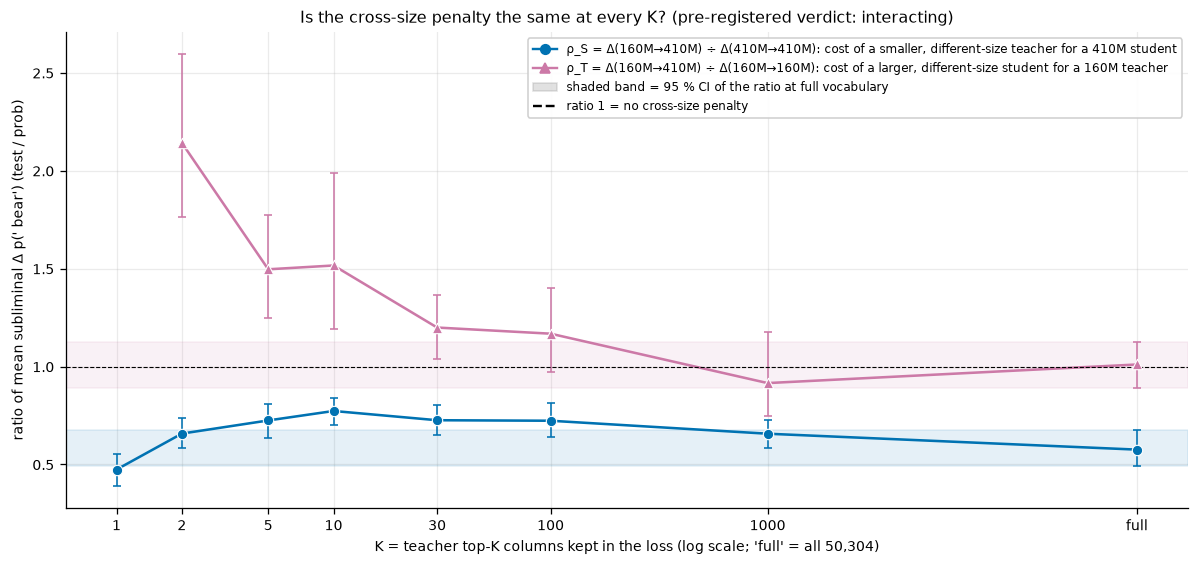

In [15]:
rho = TAB[1]["rho"].copy()
RHO_STYLE = {
    "rho_S": ("#0072B2", "o", "ρ_S = Δ(160M→410M) ÷ Δ(410M→410M): cost of a smaller, different-size teacher for a 410M student"),
    "rho_T": ("#CC79A7", "^", "ρ_T = Δ(160M→410M) ÷ Δ(160M→160M): cost of a larger, different-size student for a 160M teacher"),
}
fig, ax = plt.subplots(figsize=(10.5, 5.0))
for measure, (color, marker, label) in RHO_STYLE.items():
    sub = rho.loc[rho["measure"].eq(measure)].sort_values("k")
    full = sub.loc[sub["k"].eq(K_FULL)].iloc[0]
    ax.axhspan(full["ci_low"], full["ci_high"], color=color, alpha=0.10)
    plot_ci(ax, sub["k"], sub["rho"], sub["ci_low"], sub["ci_high"], color=color, marker=marker)
ax.axhline(1.0, color="black", lw=0.7, ls="--")
style_k_axis(ax)
ax.set_ylabel("ratio of mean subliminal Δ p(' bear') (test / prob)")
handles = [Line2D([], [], color=c, marker=m, label=l) for c, m, l in RHO_STYLE.values()]
handles += [Patch(color="#888888", alpha=0.25, label="shaded band = 95 % CI of the ratio at full vocabulary"),
            Line2D([], [], color="black", ls="--", label="ratio 1 = no cross-size penalty")]
ax.legend(handles=handles, loc="upper right", fontsize=7.5)
ax.set_title(f"Is the cross-size penalty the same at every K? (pre-registered verdict: {CLAIMS[1]['C2']['status']})")
fig.tight_layout()
plt.show()

**Question answered:** Is the cross-size penalty the same fraction of same-base transfer at every K?

**Conclusion from the plot:** No — ρ_S rises from 0.58 at full vocabulary to 0.77 at K = 10 and drops to 0.47 at K = 1 with no finite-K CI covering the full-vocabulary value, while ρ_T climbs from ≈ 1.0 to 2.1 at K = 2, i.e. at small K the 160M teacher transfers more into a 410M student than into its own 160M base.

## 5. Direction — 160M→410M vs 410M→160M (pre-registered C3)

**What this measures.** A(K) = mean Δ(160M→410M) − mean Δ(410M→160M) at K ∈ {full, 100, 10, 1}, with a
mean-difference 95 % CI: `asymmetric` if the CI excludes 0, `symmetric` if it lies inside ±0.02, else
`inconclusive`. Both arms use cross-pair (`tb`) controls. For context, the earlier reverse-KL recipe at full
vocabulary gave 410M→160M Δ ≈ 0.016 (see §3), so this also shows what the forward-KL objective changes.

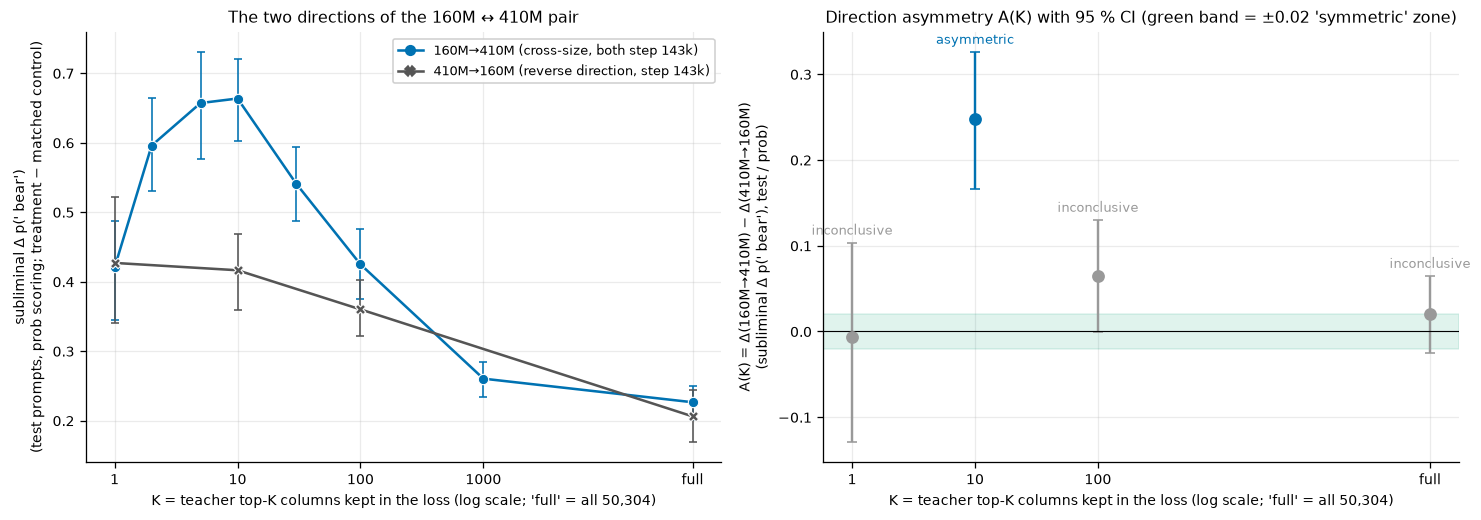

In [16]:
direction = TAB[1]["direction"].sort_values("k")
LABEL_COLOR = {"asymmetric": "#0072B2", "symmetric": "#009E73", "inconclusive": "#999999"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
for pair in ("P1", "D"):
    sub = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
    plot_ci(ax, sub["k"], sub["mean_delta_p"], sub["ci_low_p"], sub["ci_high_p"], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair])
style_k_axis(ax, ks=(1, 10, 100, 1000, K_FULL))
ax.set_ylabel(DELTA_P)
ax.legend(handles=pair_handles(("P1", "D")), loc="upper right")
ax.set_title("The two directions of the 160M ↔ 410M pair")
ax = axes[1]
ax.axhspan(-plan.EQUIVALENCE_BAND, plan.EQUIVALENCE_BAND, color="#009E73", alpha=0.12)
for _, row in direction.iterrows():
    color = LABEL_COLOR[row["label"]]
    ax.errorbar([row["k"]], [row["a"]], yerr=[[row["a"] - row["ci_low"]], [row["ci_high"] - row["a"]]],
                fmt="o", color=color, capsize=3, ms=7)
    ax.annotate(row["label"], (row["k"], row["ci_high"]), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8, color=color)
ax.axhline(0, color="black", lw=0.7)
style_k_axis(ax, ks=(1, 10, 100, K_FULL))
ax.set_ylabel("A(K) = Δ(160M→410M) − Δ(410M→160M)\n(subliminal Δ p(' bear'), test / prob)")
ax.set_title("Direction asymmetry A(K) with 95 % CI (green band = ±0.02 'symmetric' zone)")
fig.tight_layout()
plt.show()

**Question answered:** Is transfer asymmetric between 160M→410M and 410M→160M?

**Conclusion from the plot:** Only at K = 10 (A = +0.25, CI [+0.17, +0.33]); at full vocabulary, K = 100 and K = 1 the two directions are statistically indistinguishable (inconclusive, CIs straddle 0), and 410M→160M transfers at every K (Δ 0.21–0.43).

## 6. Capability cost vs K (pre-registered C6, descriptive)

**What this measures.** Four eval-time capability measures of the frozen-recipe treatment students (all
leaves, quarantined included, as amended in PREREG §9.2): held-out perplexity ratio vs the untuned base, held-out
cross-entropy increase over the base, calibration error relative to the matched controls, and mean predictive
entropy on the Pile reference text. Literature prior (Anshumann Table 1, offline pre-training KD): LM loss and ECE
worsen as K shrinks.

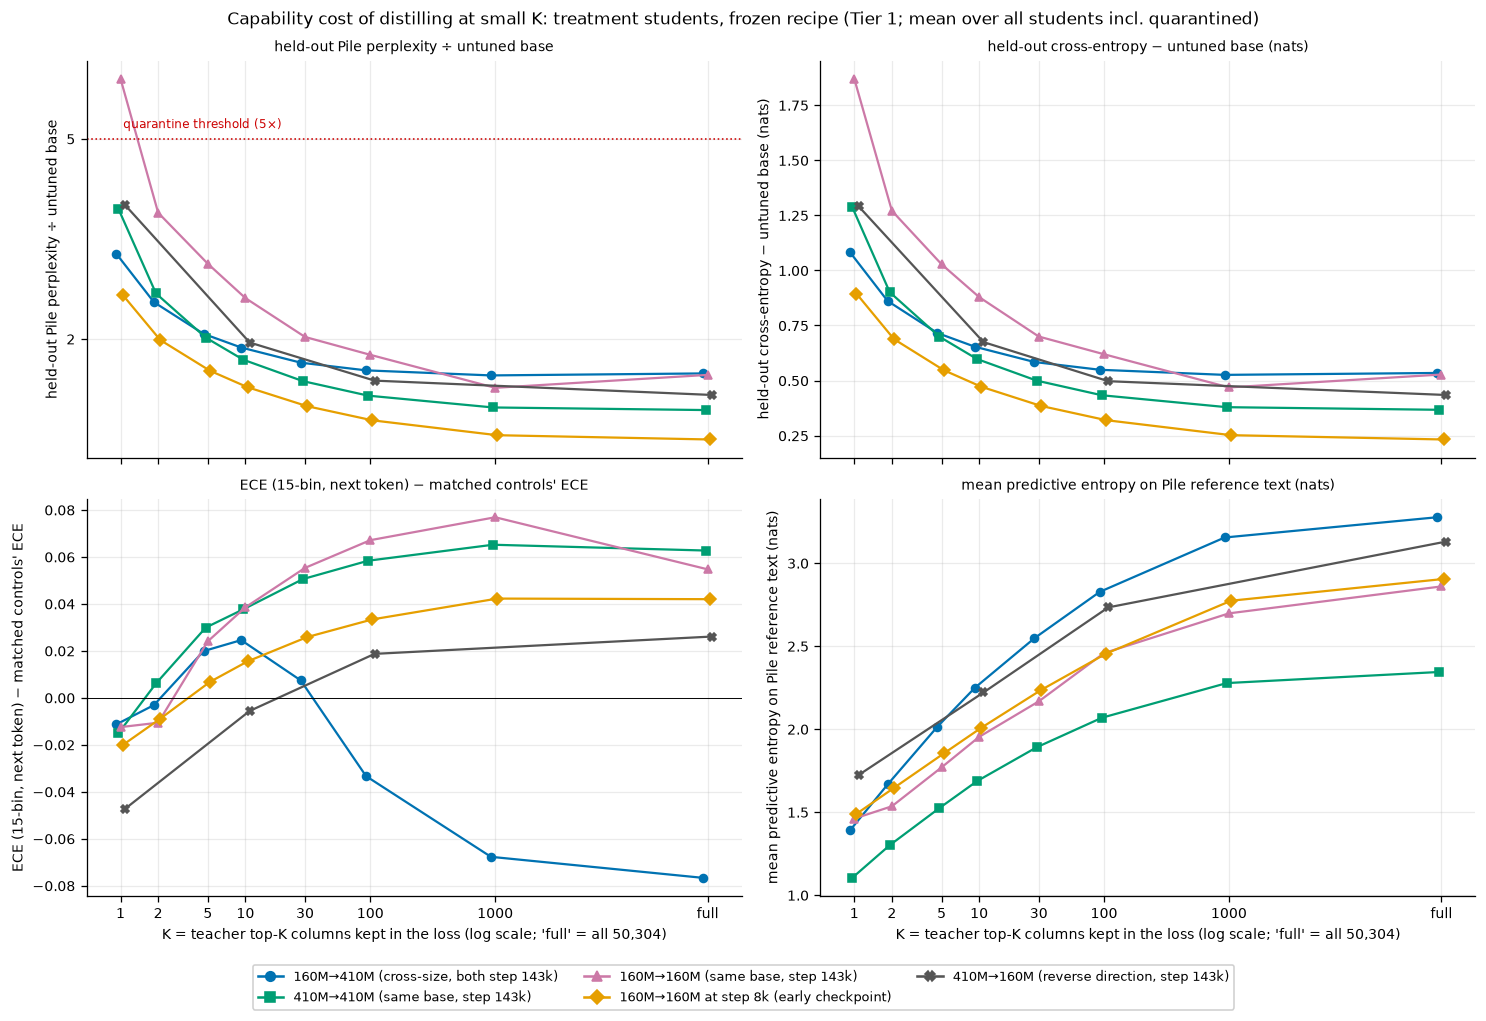

In [17]:
PANELS = (
    ("mean_ppl_ratio", "held-out Pile perplexity ÷ untuned base", True),
    ("mean_ce_nats_minus_base", "held-out cross-entropy − untuned base (nats)", False),
    ("mean_ece_minus_control", "ECE (15-bin, next token) − matched controls' ECE", False),
    ("mean_entropy", "mean predictive entropy on Pile reference text (nats)", False),
)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.4), sharex=True)
for ax, (col, label, logy) in zip(axes.flat, PANELS, strict=True):
    for i, pair in enumerate(PAIR_ORDER):
        sub = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
        ax.plot(sub["k"] * 1.04 ** (i - 2), sub[col], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair], ms=5, lw=1.4)
    if col == "mean_ppl_ratio":
        ax.axhline(plan.QUARANTINE_PPL_RATIO_MAX, color="#CC0000", ls=":", lw=1)
        ax.text(1.05, plan.QUARANTINE_PPL_RATIO_MAX * 1.05, "quarantine threshold (5×)", color="#CC0000", fontsize=7.5)
    if col == "mean_ece_minus_control":
        ax.axhline(0, color="black", lw=0.6)
    if logy:
        ax.set_yscale("log")
        plain_log_axis(ax)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=9)
    style_k_axis(ax, label=False)
for ax in axes[1]:
    ax.set_xlabel(K_AXIS)
fig.legend(handles=pair_handles(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Capability cost of distilling at small K: treatment students, frozen recipe (Tier 1; mean over all students incl. quarantined)")
fig.tight_layout()
plt.show()

**Question answered:** What does distilling at small K cost in held-out perplexity, cross-entropy, calibration and entropy?

**Conclusion from the plot:** Held-out perplexity and cross-entropy rise monotonically as K shrinks on every pair (perplexity ratio 1.3–1.7× at full vocabulary to 2.4–3.7× at K = 1, and 6.6× on 160M→160M, the only pair past the 5× quarantine line) while predictive entropy falls from 2.3–3.3 to 1.1–1.7 nats, so students sharpen rather than collapse; ECE relative to controls turns negative only at K ≤ 2.

### 6b. LM-Eval benchmarks at K ∈ {full, 10, 1}

**What this measures.** Zero-shot LAMBADA (OpenAI), ARC-Easy and SciQ, run on every student of the `ce-full`,
`ce-k10` and `ce-k1` blocks (pairs 160M→410M, 410M→410M, 160M→160M, 160M@8k; the reverse-direction pair was not
benchmarked). Values are the student's score minus the untuned base's score. Solid = treatment students
(distilled from the SDF teacher), dashed = matched controls (same objective, untuned teacher), so the gap
between them is the teacher's effect and the control line is the cost of the objective itself.

SCOPE · benchmarked students (treatments + controls): 108 students


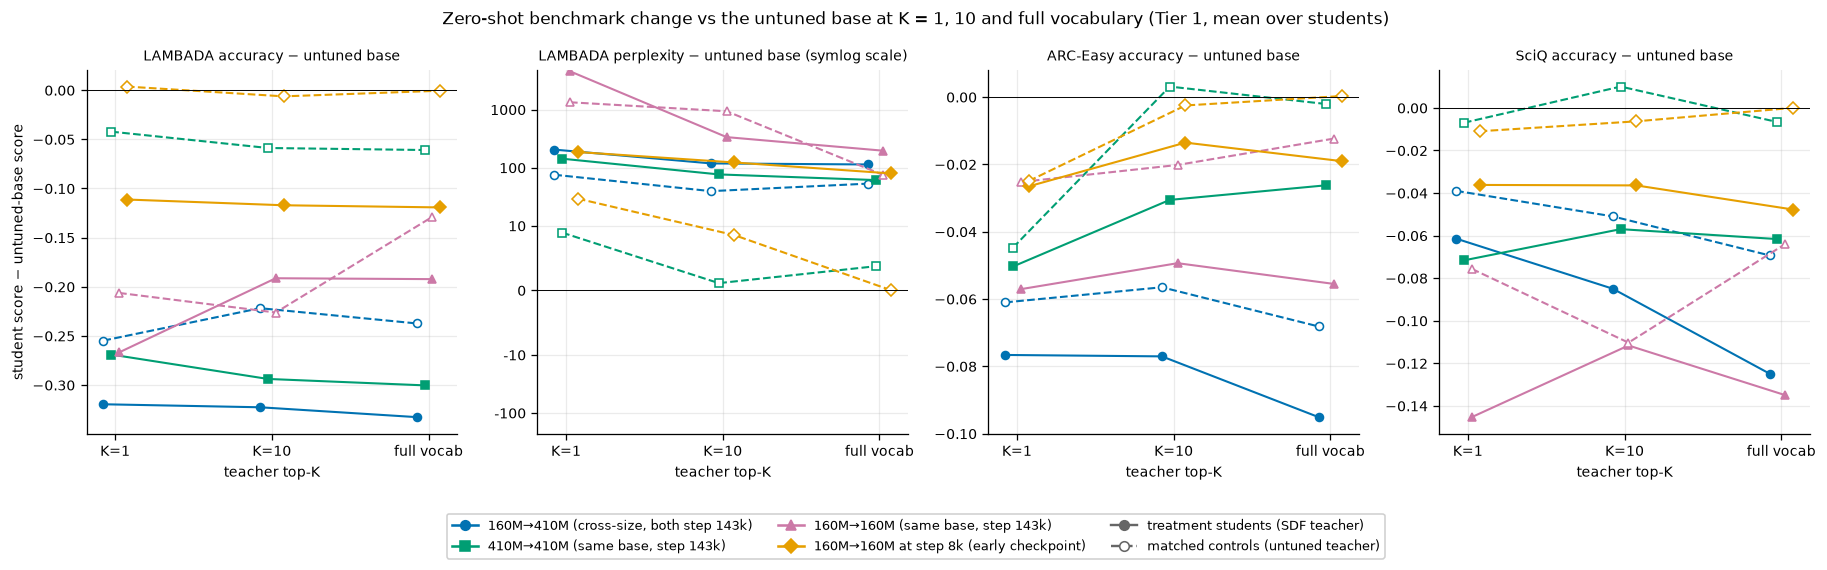

In [18]:
BENCH = (
    ("lmeval_delta_lambada_openai_acc", "LAMBADA accuracy − untuned base"),
    ("lmeval_delta_lambada_openai_perplexity", "LAMBADA perplexity − untuned base"),
    ("lmeval_delta_arc_easy_acc", "ARC-Easy accuracy − untuned base"),
    ("lmeval_delta_sciq_acc", "SciQ accuracy − untuned base"),
)
bench_leaves = leaves.loc[leaves["tier"].eq(1) & leaves["block"].isin(["ce-full", "ce-k10", "ce-k1"])].copy()
bench_leaves["group"] = np.where(bench_leaves["kind"].eq("treatment"), "treatment", "control")
bench = bench_leaves.groupby(["pair", "k", "group"])[[c for c, _ in BENCH]].mean().reset_index()
scope(bench_leaves.dropna(subset=["lmeval_delta_lambada_openai_acc"]), "benchmarked students (treatments + controls)", "students")
x_of = {1: 0, 10: 1, K_FULL: 2}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, (col, label) in zip(axes, BENCH, strict=True):
    for i, pair in enumerate(("P1", "P2", "P3", "P4")):
        for group, ls in (("treatment", "-"), ("control", "--")):
            sub = bench.loc[bench["pair"].eq(pair) & bench["group"].eq(group)].sort_values("k")
            ax.plot([x_of[int(k)] + (i - 1.5) * 0.05 for k in sub["k"]], sub[col], color=PAIR_COLOR[pair],
                    marker=PAIR_MARKER[pair], ls=ls, ms=5, lw=1.3, mfc="white" if group == "control" else PAIR_COLOR[pair])
    ax.axhline(0, color="black", lw=0.6)
    if "perplexity" in col:
        ax.set_yscale("symlog", linthresh=10)
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        label += " (symlog scale)"
    ax.set_xticks([0, 1, 2], ["K=1", "K=10", "full vocab"])
    ax.set_xlabel("teacher top-K")
    ax.set_title(label, fontsize=9)
axes[0].set_ylabel("student score − untuned-base score")
handles = pair_handles(("P1", "P2", "P3", "P4")) + [Line2D([], [], color="#666666", ls="-", marker="o", label="treatment students (SDF teacher)"),
                                                   Line2D([], [], color="#666666", ls="--", marker="o", mfc="white", label="matched controls (untuned teacher)")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.14))
fig.suptitle("Zero-shot benchmark change vs the untuned base at K = 1, 10 and full vocabulary (Tier 1, mean over students)")
fig.tight_layout()
plt.show()

**Question answered:** How much zero-shot benchmark ability do students lose, and is it the SDF teacher or the objective itself?

**Conclusion from the plot:** Treatment students usually lose more than their matched controls (410M→410M LAMBADA −0.27 to −0.30 vs −0.04 to −0.06), but on 160M→410M most of the loss is already in the controls (−0.22 to −0.26 vs −0.32 to −0.33); the pair matters more than K, and only 160M→160M at K = 1 blows up LAMBADA perplexity.

### 6c. Training telemetry vs K

**What this measures.** How the student's own rollouts and its agreement with the teacher change with K, over
the last 10 logged training steps (treatment students, frozen recipe). The CE prediction (PREREG §4 C6; STAR
App. A.3.1) is the *opposite* of the renormalised reverse-KL collapse: as K falls, student entropy and distinct-2
should fall while the student's mass on the teacher's top-K and top-1 agreement rise. Top-K fields do not exist
at full vocabulary.

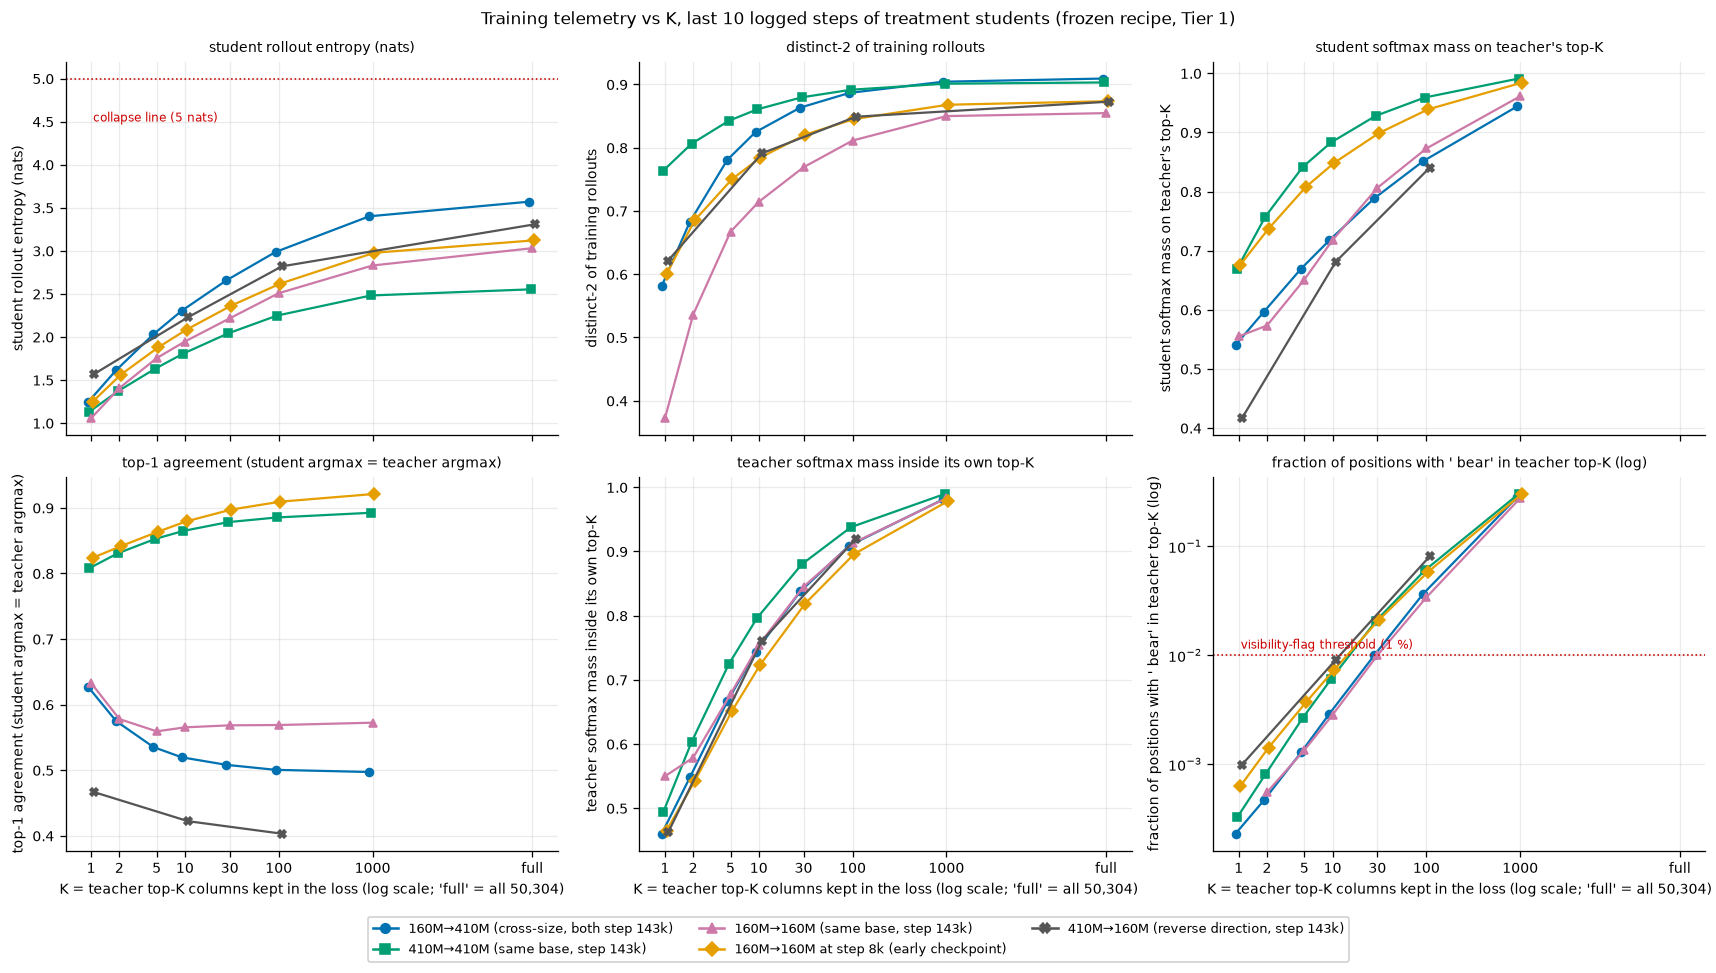

In [19]:
TEL = (
    ("mean_student_entropy", "student rollout entropy (nats)"),
    ("mean_distinct_2", "distinct-2 of training rollouts"),
    ("mean_student_topk_mass", "student softmax mass on teacher's top-K"),
    ("mean_top1_agree", "top-1 agreement (student argmax = teacher argmax)"),
    ("mean_topk_coverage", "teacher softmax mass inside its own top-K"),
    ("mean_target_in_topk_rate", "fraction of positions with ' bear' in teacher top-K (log)"),
)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, (col, label) in zip(axes.flat, TEL, strict=True):
    for i, pair in enumerate(PAIR_ORDER):
        sub = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
        ax.plot(sub["k"] * 1.04 ** (i - 2), sub[col], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair], ms=5, lw=1.4)
    if col == "mean_target_in_topk_rate":
        ax.set_yscale("log")
        ax.axhline(plan.T0_VISIBILITY_FLAG, color="#CC0000", ls=":", lw=1)
        ax.text(1.05, plan.T0_VISIBILITY_FLAG * 1.15, "visibility-flag threshold (1 %)", color="#CC0000", fontsize=7.5)
    if col == "mean_student_entropy":
        ax.axhline(plan.COLLAPSED_ENTROPY_NATS, color="#CC0000", ls=":", lw=1)
        ax.text(1.05, plan.COLLAPSED_ENTROPY_NATS * 0.9, "collapse line (5 nats)", color="#CC0000", fontsize=7.5)
    style_k_axis(ax, label=False)
    ax.set_title(label, fontsize=9)
    ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel(K_AXIS)
fig.legend(handles=pair_handles(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Training telemetry vs K, last 10 logged steps of treatment students (frozen recipe, Tier 1)")
fig.tight_layout()
plt.show()

**Question answered:** How do the student's rollouts and its agreement with the teacher change as K shrinks?

**Conclusion from the plot:** Rollouts sharpen as K falls — entropy drops from 2.6–3.6 to 1.1–1.6 nats and distinct-2 from ~0.86–0.91 to 0.37–0.76, the opposite of the reverse-KL collapse — while top-1 agreement is set mostly by the pair (0.81–0.92 for 410M→410M and 160M@8k, 0.40–0.63 otherwise) and moves little with K, and ' bear' is in the teacher's top-K at under 1 % of positions once K ≤ 10.

### 6d. Transfer vs capability across every arm

**What this measures.** Every cell of both tiers (all arms, K, λ, N, HPs, teacher doses): does a larger
subliminal Δ come with a larger perplexity cost? Colour = pair, marker = arm. Cell means include quarantined
students for perplexity (C6 rule) and exclude them for Δ.

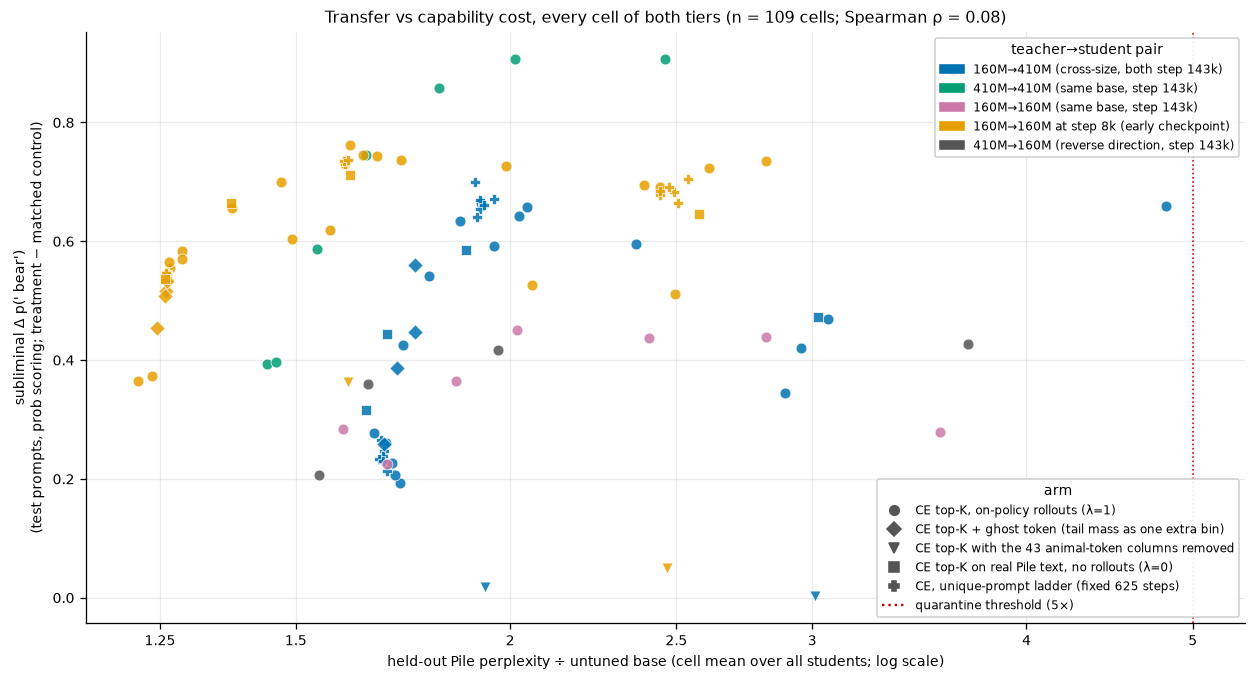

In [20]:
fig, ax = plt.subplots(figsize=(11, 6))
for (pair, arm), grp in cells.groupby(["pair", "arm"]):
    ax.scatter(grp["mean_ppl_ratio"], grp["mean_delta_p"], color=PAIR_COLOR[pair], marker=ARM_MARKER[arm],
               s=46, alpha=0.85, edgecolors="white", linewidths=0.5)
ax.axvline(plan.QUARANTINE_PPL_RATIO_MAX, color="#CC0000", ls=":", lw=1)
ax.set_xscale("log")
plain_log_axis(ax, axis="x")
ax.set_xticks([1.25, 1.5, 2, 2.5, 3, 4, 5])
ax.set_xlabel("held-out Pile perplexity ÷ untuned base (cell mean over all students; log scale)")
ax.set_ylabel(DELTA_P)
rho_all = cells[["mean_ppl_ratio", "mean_delta_p"]].dropna().corr(method="spearman").iloc[0, 1]
ax.set_title(f"Transfer vs capability cost, every cell of both tiers (n = {cells['mean_delta_p'].notna().sum()} cells; Spearman ρ = {rho_all:.2f})")
h1 = [Patch(color=PAIR_COLOR[p], label=PAIR_LABEL[p]) for p in PAIR_ORDER]
h2 = [Line2D([], [], ls="none", marker=m, color="#555555", label=ARM_LABEL[a]) for a, m in ARM_MARKER.items()]
h2.append(Line2D([], [], color="#CC0000", ls=":", label="quarantine threshold (5×)"))
leg = ax.legend(handles=h1, loc="upper right", title="teacher→student pair", fontsize=7.5)
ax.add_artist(leg)
ax.legend(handles=h2, loc="lower right", title="arm", fontsize=7.5)
fig.tight_layout()
plt.show()

**Question answered:** Across every arm, does more subliminal transfer come with more capability loss?

**Conclusion from the plot:** No — Spearman ρ = 0.08 over 109 cells: large Δ occurs at perplexity ratios from 1.3 (160M@8k, full vocabulary) to 4.8 (160M→410M, lr 8e-4, K = 1), and the near-zero cells are the animal-column-masked arms, which are not cheaper in perplexity.

## 7. Rollout screen — how often do training rollouts name the target animal?

**What this measures.** During on-policy training every rollout row is screened (whole-word, case-insensitive)
for bear's surface forms and bear trait-lexicon terms (`filtering.target_screen_forms`); a hit masks the row out
of the loss (labels −100). The drop fraction is therefore how often the *student itself* overtly writes a bear
word while being distilled. Left: mean over training by K for treatment
students vs matched controls. Right: the per-step trajectory on 160M→410M. Rows above 0.5 would quarantine a
student. (λ = 0 arms screen real Pile text instead; see §12.)

SCOPE · Tier-1 frozen-recipe training-log rows: 20832 step rows


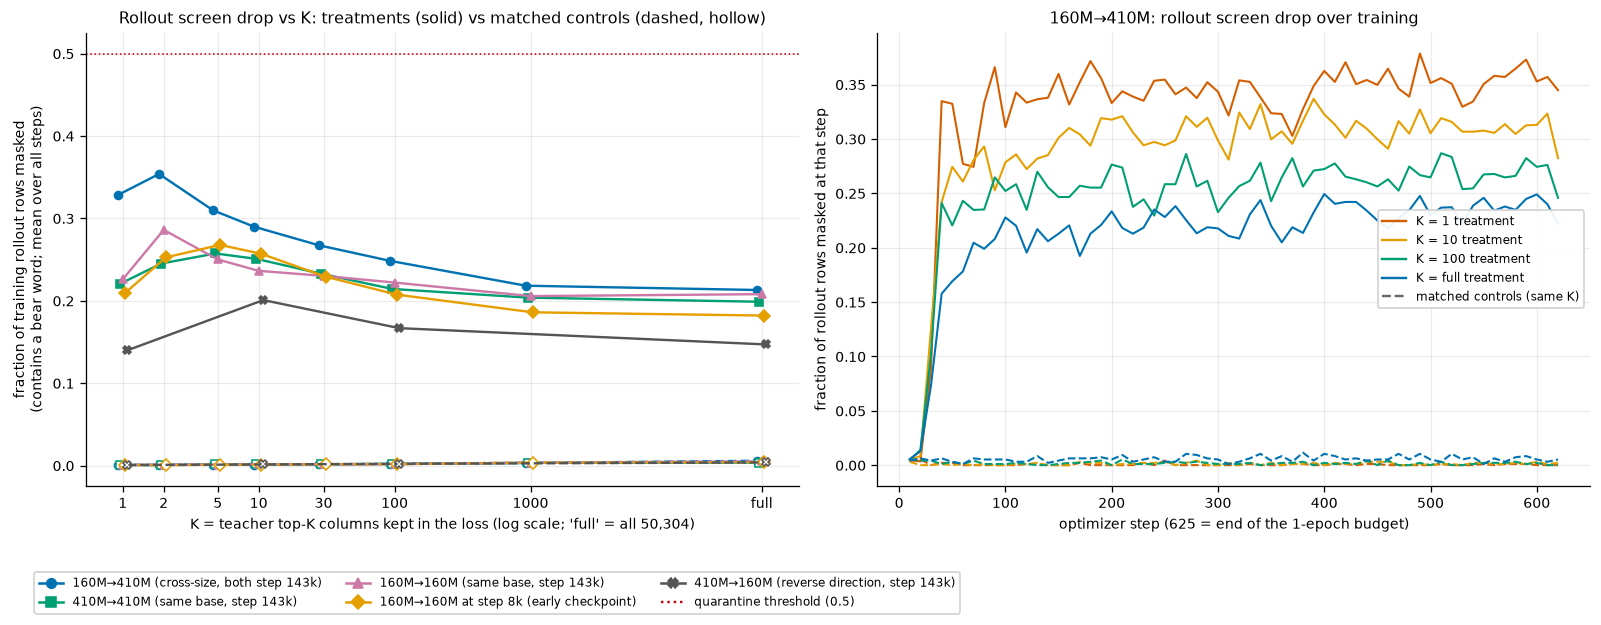

In [21]:
logs_t1 = load_gkd_training_logs(OUTPUT_ROOT, run_set_subdir(GKD_STUDENTS_SUBDIR, plan.TIER1.run_set_id), animals=list(plan.ANIMALS))
logs_t1["pair"] = pair_of(logs_t1)
logs_t1["k"] = logs_t1["gkd_tag"].map(LADDER_TAG_K)
logs_t1 = logs_t1.loc[logs_t1["k"].notna() & (logs_t1["is_control"].astype(bool) | logs_t1["teacher_param_tag"].eq(plan.TEACHER_TAG_EP5))]
scope(logs_t1, "Tier-1 frozen-recipe training-log rows", "step rows")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
screen = leaves.loc[leaves["tier"].eq(1) & leaves["block"].str.match(r"^(ce-|dir$)")].copy()
screen["group"] = np.where(screen["kind"].eq("treatment"), "treatment", "control")
screen_mean = screen.groupby(["pair", "k", "group"])["filter_drop"].mean().reset_index()
for i, pair in enumerate(PAIR_ORDER):
    for group, ls in (("treatment", "-"), ("control", "--")):
        sub = screen_mean.loc[screen_mean["pair"].eq(pair) & screen_mean["group"].eq(group)].sort_values("k")
        ax.plot(sub["k"] * 1.04 ** (i - 2), sub["filter_drop"], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair], ls=ls, ms=5,
                mfc="white" if group == "control" else PAIR_COLOR[pair])
ax.axhline(plan.QUARANTINE_FILTER_DROP_MAX, color="#CC0000", ls=":", lw=1)
style_k_axis(ax)
ax.set_ylabel("fraction of training rollout rows masked\n(contains a bear word; mean over all steps)")
ax.set_title("Rollout screen drop vs K: treatments (solid) vs matched controls (dashed, hollow)")
fig.legend(handles=pair_handles() + [Line2D([], [], color="#CC0000", ls=":", label="quarantine threshold (0.5)")],
           loc="lower left", ncol=3, bbox_to_anchor=(0.02, -0.13), fontsize=7.5)
ax = axes[1]
traj = logs_t1.loc[logs_t1["pair"].eq("P1") & logs_t1["k"].isin([1, 10, 100, K_FULL])]
K_COLOR = {1: "#D55E00", 10: "#E69F00", 100: "#009E73", K_FULL: "#0072B2"}
for (k, is_ctrl), grp in traj.groupby(["k", traj["is_control"].astype(bool)]):
    curve = grp.groupby("step")["filter_drop_frac"].mean()
    ax.plot(curve.index, curve.to_numpy(), color=K_COLOR[int(k)], ls="--" if is_ctrl else "-", lw=1.3)
ax.set_xlabel("optimizer step (625 = end of the 1-epoch budget)")
ax.set_ylabel("fraction of rollout rows masked at that step")
ax.set_title("160M→410M: rollout screen drop over training")
ax.legend(handles=[Line2D([], [], color=c, label=f"K = {k_tick(k)} treatment") for k, c in K_COLOR.items()]
          + [Line2D([], [], color="#666666", ls="--", label="matched controls (same K)")], fontsize=7.5)
fig.tight_layout()
plt.show()

**Question answered:** How often do training rollouts overtly contain a bear word, and does that differ from controls?

**Conclusion from the plot:** Treatment students write a bear word in 14–35 % of training rollout rows (160M→410M rises from 0.20 at full vocabulary to 0.35 at K = 2) versus under 1 % for every control, and on 160M→410M the rate jumps within the first ~40 steps and then stays flat, so the screen strips a large overt-mention signal from the loss throughout training while staying below the 0.5 quarantine level.

## 8. Student-HP star — learning rate and LoRA rank (pre-registered C4, descriptive)

**What this measures.** Whether the K-curve is an artefact of the frozen student recipe. Tier 1 varies the
160M@8k pair (lr 1e-4, 1.6e-3, LoRA r16 α32; 2 teacher seeds × 2 GKD seeds); Tier 2 varies 160M→410M (lr 2e-4,
8e-4, LoRA r16 α32; 3 teacher seeds × 1 GKD seed), each at K ∈ {full, 10, 1}. The frozen-recipe line is the
full ladder cell (more students than the star cells). Priors: flat at step 8k, fragile at step 143k. Legends give
the designed students per cell; where quarantine removed students, the translucent marker with a dashed CI shows
the same cell with them kept ("a of b live") — context only, not a result.

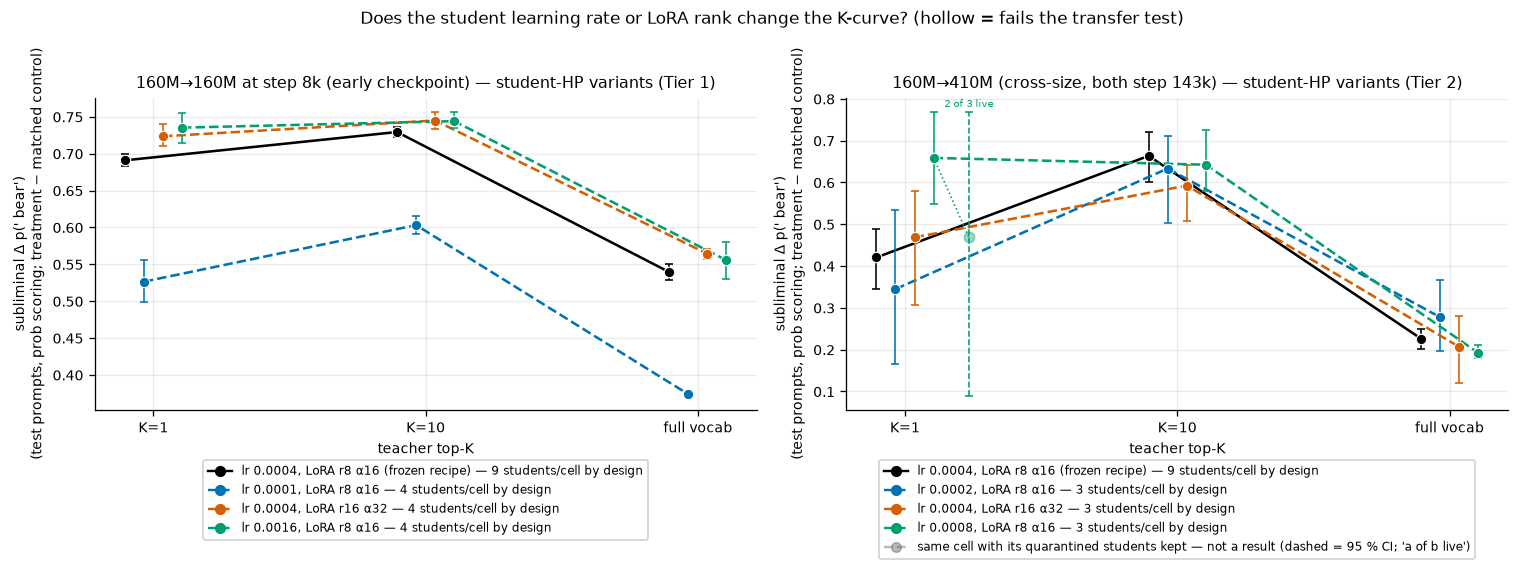

In [22]:
HP_COLORS = ["#000000", "#0072B2", "#D55E00", "#009E73"]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))
x_of = {1: 0, 10: 1, K_FULL: 2}
for ax, pair, tier in ((axes[0], "P4", 1), (axes[1], "P1", 2)):
    base = LADDER.loc[LADDER["pair"].eq(pair) & LADDER["k"].isin(list(x_of))]
    star = cells.loc[cells["tier"].eq(tier) & cells["block"].str.startswith(f"hp-{pair.lower()}-") & ~cells["block"].str.contains("dose")]
    frames = [base] + [g for _, g in star.groupby(["hp_lr", "hp_lora_r"])]
    handles = []
    any_kept = False
    for j, frame in enumerate(frames):
        frame = frame.sort_values("k")
        row0 = frame.iloc[0]
        x = np.array([x_of[int(k)] for k in frame["k"]]) + (j - 1.5) * 0.07
        plot_ci(ax, x, frame["mean_delta_p"], frame["ci_low_p"], frame["ci_high_p"], color=HP_COLORS[j], marker="o",
                filled=frame["t0"].astype(bool), ls="-" if j == 0 else "--")
        kept = frame.loc[frame["n_total"].gt(frame["n_live"])]
        if not kept.empty:
            any_kept = True
            x_live = np.array([x_of[int(k)] for k in kept["k"]]) + (j - 1.5) * 0.07
            overlay_quarantined(ax, x_live, x_live + 0.13, kept, mean="mean_delta_p_unq", lo="ci_low_p_unq",
                                hi="ci_high_p_unq", live="mean_delta_p", color=HP_COLORS[j], marker="o")
        n = int(frame["n_design"].iloc[0])
        handles.append(Line2D([], [], color=HP_COLORS[j], marker="o", ls="-" if j == 0 else "--",
                              label=f"{hp_label(row0['hp_lr'], row0['hp_lora_r'], row0['hp_lora_alpha'])} — {n} students/cell by design"))
    if any_kept:
        handles.append(KEPT_HANDLE)
    ax.set_xticks([0, 1, 2], ["K=1", "K=10", "full vocab"])
    ax.set_xlabel("teacher top-K")
    ax.set_ylabel(DELTA_P)
    ax.set_title(f"{PAIR_LABEL[pair]} — student-HP variants (Tier {tier})")
    ax.legend(handles=handles, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.suptitle("Does the student learning rate or LoRA rank change the K-curve? (hollow = fails the transfer test)", y=1.03)
fig.tight_layout()
plt.show()

**Question answered:** Does the student learning rate or LoRA rank change the K-curve?

**Conclusion from the plot:** On 160M@8k every variant keeps the same K ordering (K = 10 ≥ K = 1 > full) and only the low lr 1e-4 lowers Δ across the board; on 160M→410M the variants overlap the frozen recipe at full vocabulary and K = 10, while K = 1 is fragile (lr 8e-4 raises it to 0.66 on its 2 live students — 0.47 [0.09, 0.77] if the quarantined teacher-seed-2 student were kept — and lr 2e-4 lowers it to 0.35 with a wide CI).

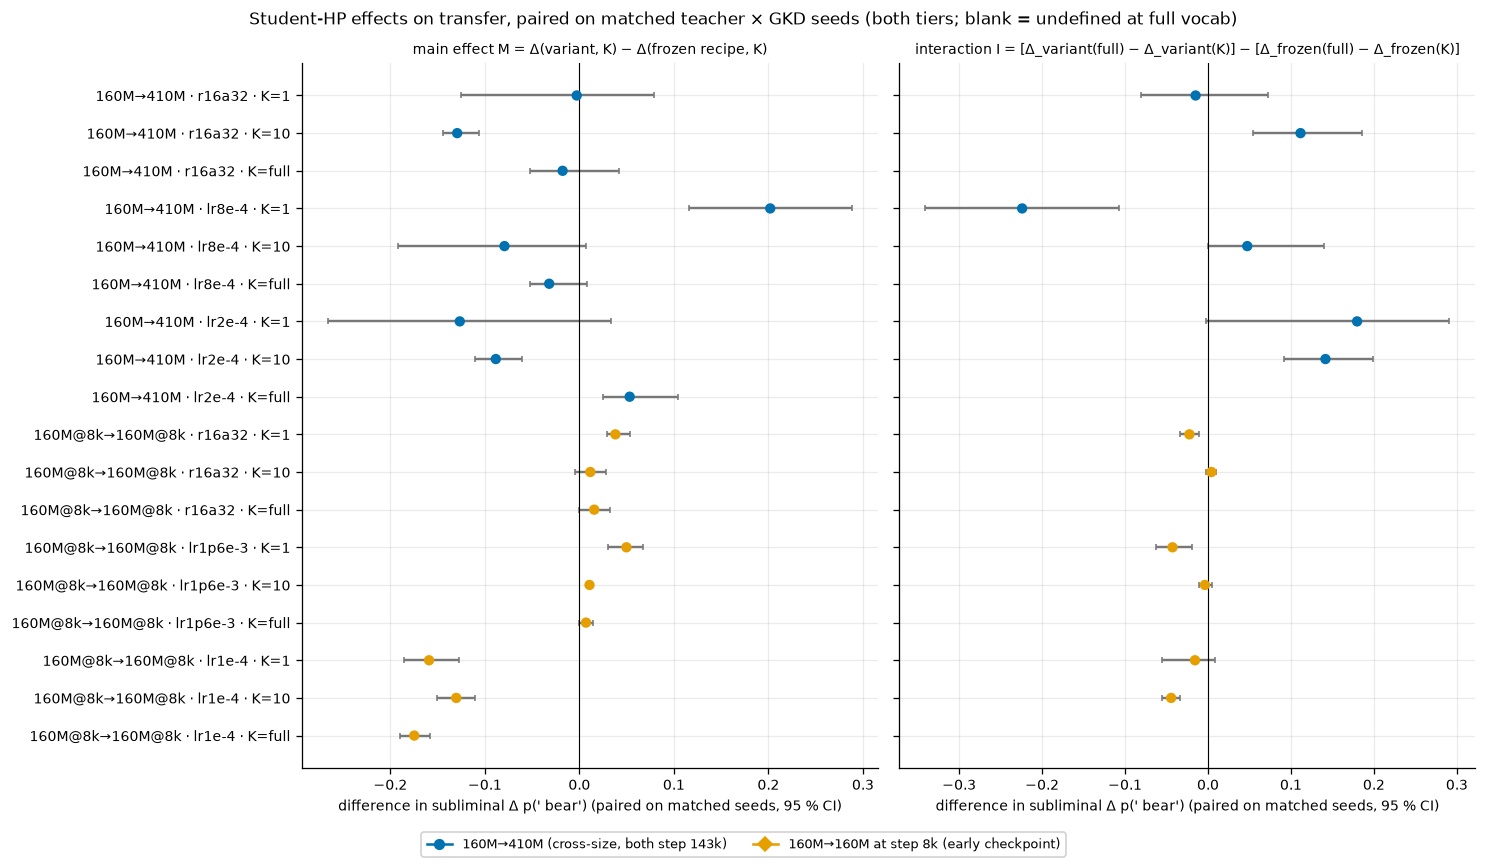

In [23]:
hp = pd.concat([TAB[1]["hp"], TAB[2]["hp"]], ignore_index=True)
hp = hp.loc[hp["status"].ne("pending_tier2")].copy()
hp["row"] = [f"{PAIR_SHORT[p]} · {b.split('-', 2)[2]} · K={k_tick(k)}" for p, b, k in zip(hp["pair"], hp["block"], hp["k"], strict=True)]
hp = hp.sort_values(["pair", "block", "k"], ascending=[False, True, False]).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(hp) + 1.5), sharey=True)
for ax, (col, lo, hi, title) in zip(axes, (("m", "m_ci_low", "m_ci_high", "main effect M = Δ(variant, K) − Δ(frozen recipe, K)"),
                                          ("i", "i_ci_low", "i_ci_high", "interaction I = [Δ_variant(full) − Δ_variant(K)] − [Δ_frozen(full) − Δ_frozen(K)]")), strict=True):
    y = np.arange(len(hp))
    colors = [PAIR_COLOR[p] for p in hp["pair"]]
    ok = hp[col].notna()
    ax.errorbar(hp.loc[ok, col], y[ok], xerr=[hp.loc[ok, col] - hp.loc[ok, lo], hp.loc[ok, hi] - hp.loc[ok, col]],
                fmt="none", ecolor="#777777", capsize=2)
    ax.scatter(hp.loc[ok, col], y[ok], c=[c for c, o in zip(colors, ok, strict=True) if o], s=30, zorder=3)
    ax.axvline(0, color="black", lw=0.7)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("difference in subliminal Δ p(' bear') (paired on matched seeds, 95 % CI)")
axes[0].set_yticks(np.arange(len(hp)), hp["row"])
fig.legend(handles=pair_handles(("P1", "P4")), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04), fontsize=8)
fig.suptitle("Student-HP effects on transfer, paired on matched teacher × GKD seeds (both tiers; blank = undefined at full vocab)")
fig.tight_layout()
plt.show()

**Question answered:** Which student-HP changes shift transfer beyond seed noise, and do they interact with K?

**Conclusion from the plot:** On 160M@8k effects are small and K-invariant except lr 1e-4 (−0.13 to −0.17, interactions within ±0.05), whereas on 160M→410M they are larger and K-dependent — lr 8e-4 at K = 1 (+0.20, interaction −0.22) and r16 / lr 2e-4 at K = 10 (−0.09 to −0.13) — matching the prior of flat at step 8k and fragile at step 143k.

## 9. Teacher dose — SDF epochs 2 / 5 / 8 (pre-registered C5, descriptive)

**What this measures.** On the 160M@8k pair, how transfer scales with teacher strength. The teacher was
SDF-fine-tuned for 2, 5 or 8 epochs (teacher p(' bear') 0.400 / 0.594 / 0.642 on the test prompts), and each was
distilled at K ∈ {full, 10, 1}. Dose treatments reuse the frozen ladder's controls; the 5-epoch point is restricted
to the dose design seeds (teacher seeds 0–1 × GKD seeds 0–1). Lines are OLS fits of cell mean Δ on teacher
p(' bear'); dots are students.

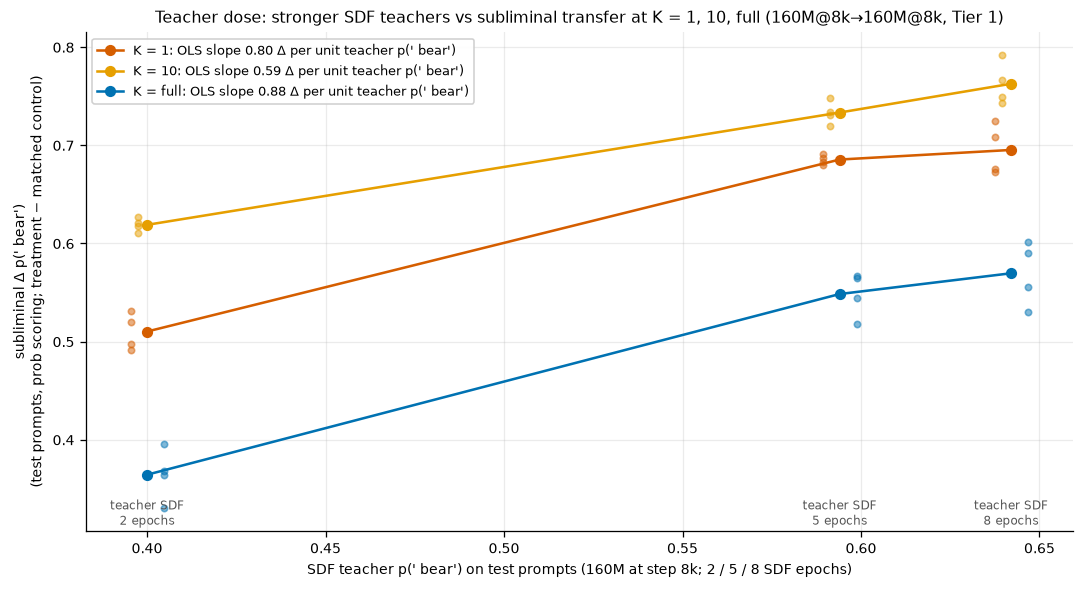

,k_slug,teacher_param_tag,teacher_p_target,n_live,mean_delta_p,slope,slope_minus_full
0,full,ep5_lr5e-5_r128a128,0.594,4,0.548,0.877,0.000
1,full,ep2_lr5e-5_r128a128,0.400,4,0.364,0.877,0.000
2,full,ep8_lr5e-5_r128a128,0.642,4,0.570,0.877,0.000
3,k10,ep5_lr5e-5_r128a128,0.594,4,0.733,0.593,-0.284
4,k10,ep2_lr5e-5_r128a128,0.400,4,0.619,0.593,-0.284
5,k10,ep8_lr5e-5_r128a128,0.642,4,0.763,0.593,-0.284
6,k1,ep5_lr5e-5_r128a128,0.594,4,0.685,0.804,-0.073
7,k1,ep2_lr5e-5_r128a128,0.400,4,0.510,0.804,-0.073
8,k1,ep8_lr5e-5_r128a128,0.642,4,0.695,0.804,-0.073


In [24]:
dose = TAB[1]["dose"].copy()
design = plan.RED_MATCHED_REUSE
dose_leaves = deltas.loc[
    deltas["tier"].eq(1) & deltas["pair"].eq("P4") & deltas["arm"].eq("ce") & deltas["base_hp"]
    & deltas["k"].isin([1, 10, K_FULL]) & deltas["ftseed"].isin(design.tfs) & deltas["gseed"].isin(design.gseeds)
    & (deltas["block"].str.startswith("hp-p4-dose-") | deltas["block"].str.match(r"^ce-"))
].copy()
dose_leaves["teacher_p"] = dose_leaves["teacher_param_tag"].map(dict(plan.TEACHER_P_TARGET_BY_TAG))
K_COLOR = {1: "#D55E00", 10: "#E69F00", K_FULL: "#0072B2"}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for k, color in K_COLOR.items():
    sub = dose.loc[dose["k"].eq(k)].sort_values("teacher_p_target")
    lv = dose_leaves.loc[dose_leaves["k"].eq(k)]
    ax.scatter(lv["teacher_p"] + (math.log10(k) - 2.3) * 0.002, lv["delta_p"], color=color, s=16, alpha=0.5)
    ax.plot(sub["teacher_p_target"], sub["mean_delta_p"], color=color, marker="o", lw=1.6,
            label=f"K = {k_tick(k)}: OLS slope {sub['slope'].iloc[0]:.2f} Δ per unit teacher p(' bear')")
for tag, p in plan.TEACHER_P_TARGET_BY_TAG.items():
    ax.annotate(f"teacher SDF\n{tag.split('_')[0].replace('ep', '')} epochs", (p, ax.get_ylim()[0]), textcoords="offset points",
                xytext=(0, 4), ha="center", fontsize=7.5, color="#555555")
ax.set_xlabel("SDF teacher p(' bear') on test prompts (160M at step 8k; 2 / 5 / 8 SDF epochs)")
ax.set_ylabel(DELTA_P)
ax.set_title("Teacher dose: stronger SDF teachers vs subliminal transfer at K = 1, 10, full (160M@8k→160M@8k, Tier 1)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()
display(dose[["k_slug", "teacher_param_tag", "teacher_p_target", "n_live", "mean_delta_p", "slope", "slope_minus_full"]].round(3))

**Question answered:** How does transfer scale with teacher strength (SDF epochs 2 / 5 / 8) at each K?

**Conclusion from the plot:** Δ rises with teacher p(' bear') at every K (OLS slopes 0.59–0.88), mostly between 2 and 5 SDF epochs, and the ordering K = 10 > K = 1 > full vocabulary holds at all three doses.

## 10. Ghost token vs plain CE top-K (pre-registered G1)

**What this measures.** The ghost variant (Anshumann §3.2) adds one extra bin holding the teacher's and the
student's tail mass outside the top-K, so the tail is supervised as a lump instead of being pushed to zero. Top
row: Δ for ghost (Tier 2) vs plain CE (Tier 1) at the K both ran; label = pre-registered paired verdict
(`ce_higher` / `ghost_higher` / `equivalent` within ±0.02 / `inconclusive`). Bottom row: calibration error of the
treatment students (literature prior: ghost is better calibrated).

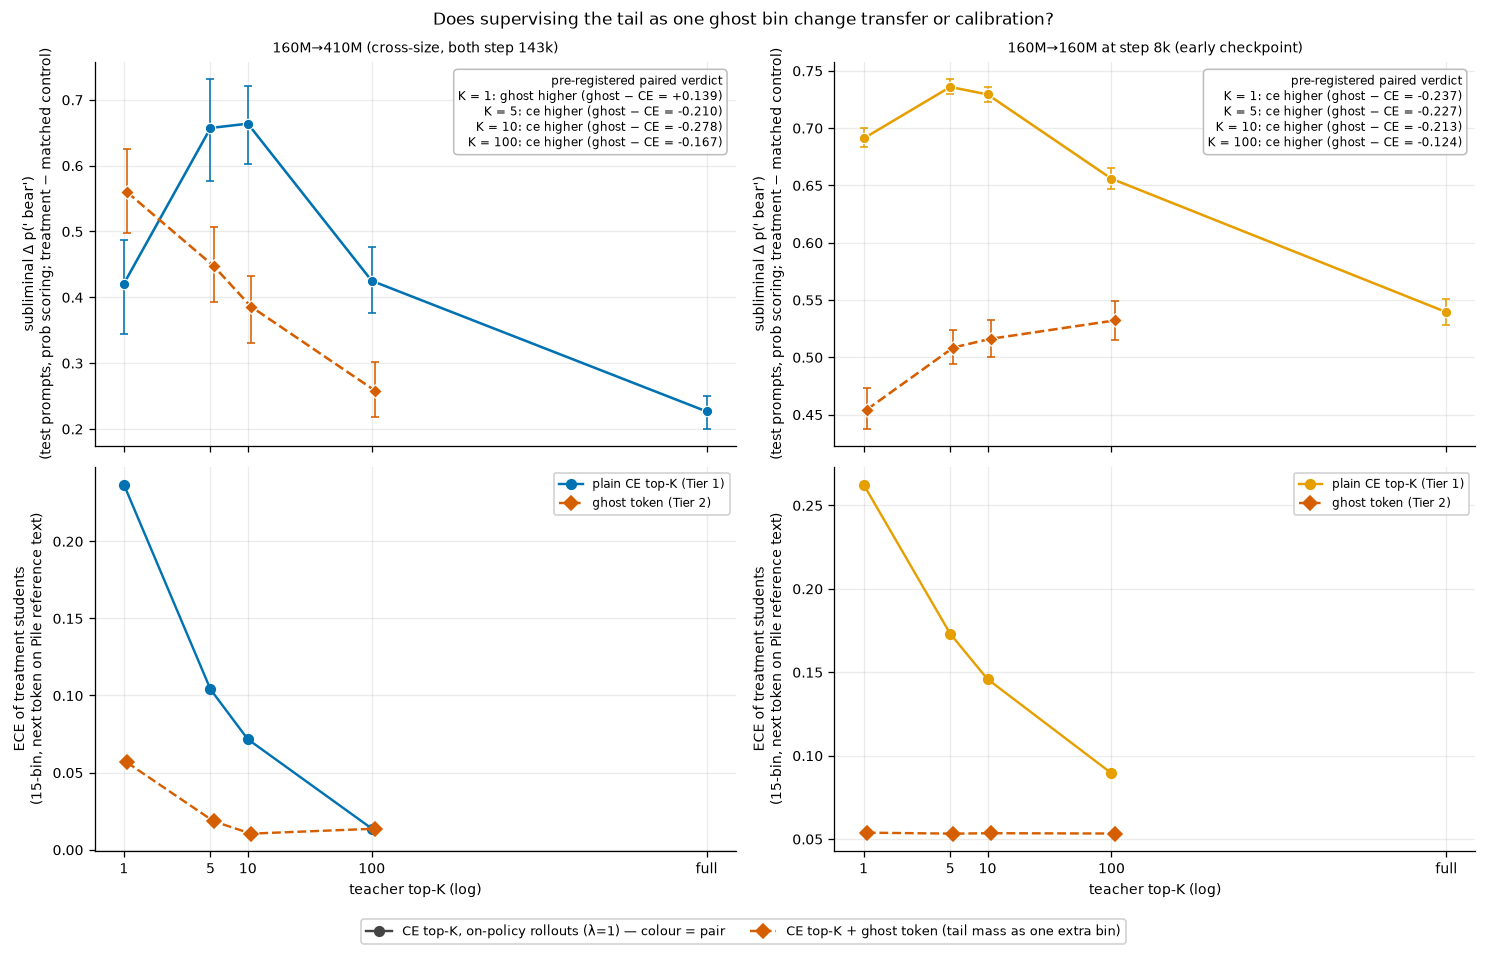

In [25]:
gvc = TAB[2]["ghost_vs_ce"].copy()
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for j, pair in enumerate(("P1", "P4")):
    ce = LADDER.loc[LADDER["pair"].eq(pair) & LADDER["k"].isin([1, 5, 10, 100, K_FULL])].sort_values("k")
    gh = cells.loc[cells["pair"].eq(pair) & cells["arm"].eq("ghost")].sort_values("k")
    ax = axes[0, j]
    plot_ci(ax, ce["k"], ce["mean_delta_p"], ce["ci_low_p"], ce["ci_high_p"], color=PAIR_COLOR[pair], marker="o")
    plot_ci(ax, gh["k"] * 1.06, gh["mean_delta_p"], gh["ci_low_p"], gh["ci_high_p"], color="#D55E00", marker="D", ls="--", ms=6)
    rows = [f"K = {k_tick(r['k'])}: {r['label'].replace('_', ' ')} (ghost − CE = {r['d']:+.3f})"
            for _, r in gvc.loc[gvc["pair"].eq(pair)].sort_values("k").iterrows()]
    verdict_box(ax, rows, "pre-registered paired verdict")
    ax.set_title(PAIR_LABEL[pair], fontsize=9)
    ax.set_ylabel(DELTA_P)
    ax = axes[1, j]
    sub = gvc.loc[gvc["pair"].eq(pair)].sort_values("k")
    ax.plot(sub["k"], sub["ece_ce"], color=PAIR_COLOR[pair], marker="o", label="plain CE top-K (Tier 1)")
    ax.plot(sub["k"] * 1.06, sub["ece_ghost"], color="#D55E00", marker="D", ls="--", label="ghost token (Tier 2)")
    ax.set_ylabel("ECE of treatment students\n(15-bin, next token on Pile reference text)")
    style_k_axis(ax, ks=(1, 5, 10, 100), label=False)
    ax.set_xlabel("teacher top-K (log)")
    ax.legend(fontsize=7.5)
style_k_axis(axes[0, 0], ks=(1, 5, 10, 100, K_FULL), label=False)
style_k_axis(axes[0, 1], ks=(1, 5, 10, 100, K_FULL), label=False)
fig.legend(handles=[Line2D([], [], color="#444444", marker="o", label=ARM_LABEL["ce"] + " — colour = pair"),
                    Line2D([], [], color="#D55E00", marker="D", ls="--", label=ARM_LABEL["ghost"])],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Does supervising the tail as one ghost bin change transfer or calibration?")
fig.tight_layout()
plt.show()

**Question answered:** Does supervising the tail as a single ghost bin change transfer or calibration?

**Conclusion from the plot:** Ghost transfers less than plain CE in 7 of 8 pair × K cells (e.g. 160M@8k K = 10: 0.52 vs 0.73; only 160M→410M K = 1 favours ghost, 0.56 vs 0.42), but it keeps treatment-student ECE low and nearly K-invariant (≤ 0.06) where plain CE's ECE climbs to 0.24–0.26 at K = 1.

## 11. Animal-token columns removed from the loss (pre-registered V1, novel ablation)

**What this measures.** Every single-token surface form of the 10 candidate animals (43 Pythia token ids, e.g.
' bear', 'bear', ' Bear', ' bears', ' Bears') is dropped from **both** teacher and student logits before the
softmax, so those logits receive no direct gradient. Transfer is still measured on the normal, unmasked student.
R_V = Δ(masked) ÷ Δ(plain CE): `token_mediated` if the CI upper bound < 0.5, `not_token_mediated` if the CI lower
bound ≥ 0.8, else `partial`.

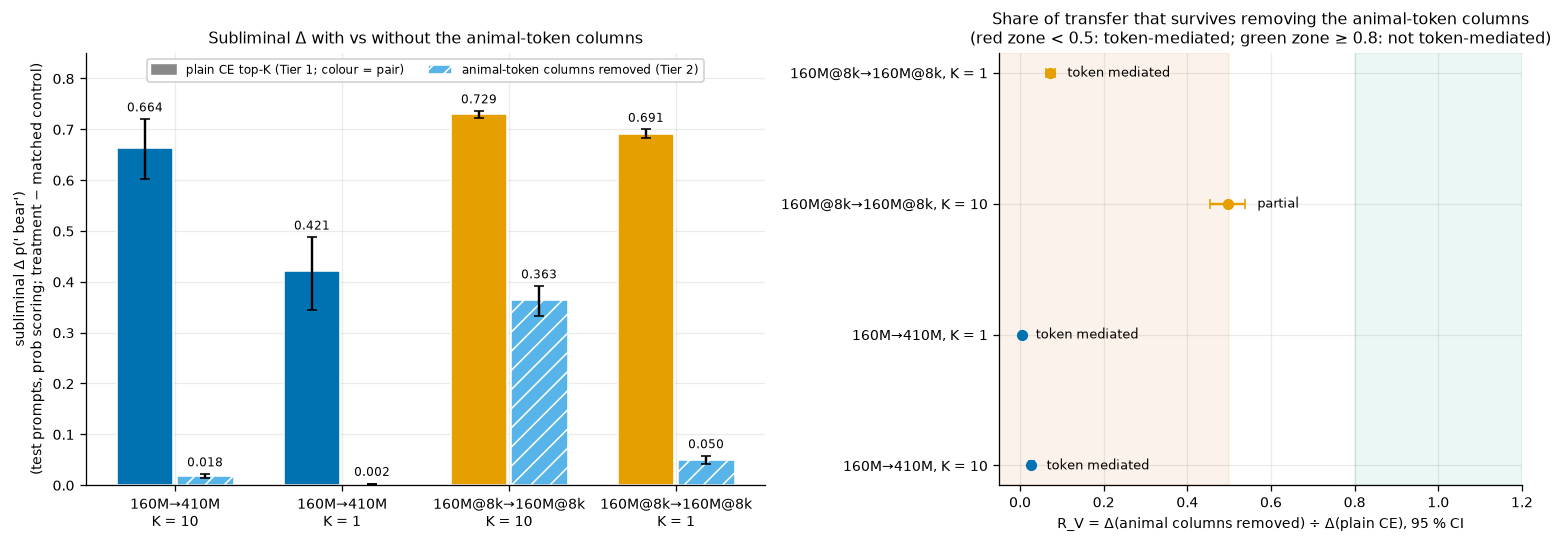

In [26]:
vm = TAB[2]["vmask"].copy()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
positions, labels = [], []
for i, (pair, k) in enumerate([(p, k) for p in ("P1", "P4") for k in (10, 1)]):
    ce = LADDER.loc[LADDER["pair"].eq(pair) & LADDER["k"].eq(k)].iloc[0]
    mk = cells.loc[cells["pair"].eq(pair) & cells["arm"].eq("vmaskf") & cells["k"].eq(k)].iloc[0]
    for off, row, color, hatch in ((-0.18, ce, PAIR_COLOR[pair], None), (0.18, mk, "#56B4E9", "//")):
        ax.bar(i + off, row["mean_delta_p"], width=0.34, color=color, hatch=hatch, edgecolor="white")
        ax.errorbar(i + off, row["mean_delta_p"], yerr=[[row["mean_delta_p"] - row["ci_low_p"]], [row["ci_high_p"] - row["mean_delta_p"]]],
                    fmt="none", ecolor="black", capsize=3)
        ax.text(i + off, row["ci_high_p"] + 0.015, f"{row['mean_delta_p']:.3f}", ha="center", fontsize=7.5)
    positions.append(i)
    labels.append(f"{PAIR_SHORT[pair]}\nK = {k}")
ax.set_xticks(positions, labels)
ax.set_ylabel(DELTA_P)
ax.set_title("Subliminal Δ with vs without the animal-token columns")
ax.set_ylim(0, 0.85)
ax.legend(handles=[Patch(color="#888888", label="plain CE top-K (Tier 1; colour = pair)"),
                   Patch(facecolor="#56B4E9", hatch="//", edgecolor="white", label="animal-token columns removed (Tier 2)")],
          fontsize=7.5, loc="upper center", ncol=2)
ax = axes[1]
ax.axvspan(-0.1, plan.TOKEN_MEDIATED_MAX, color="#D55E00", alpha=0.08)
ax.axvspan(plan.NOT_TOKEN_MEDIATED_MIN, 1.2, color="#009E73", alpha=0.08)
for i, row in vm.reset_index(drop=True).iterrows():
    ax.errorbar(row["r_v"], i, xerr=[[row["r_v"] - row["ci_low"]], [row["ci_high"] - row["r_v"]]], fmt="o",
                color=PAIR_COLOR[row["pair"]], capsize=3)
    ax.text(row["ci_high"] + 0.03, i, row["label"].replace("_", " "), va="center", fontsize=8)
ax.set_yticks(range(len(vm)), [f"{PAIR_SHORT[p]}, K = {int(k)}" for p, k in zip(vm["pair"], vm["k"], strict=True)])
ax.set_xlim(-0.05, 1.2)
ax.set_xlabel("R_V = Δ(animal columns removed) ÷ Δ(plain CE), 95 % CI")
ax.set_title("Share of transfer that survives removing the animal-token columns\n(red zone < 0.5: token-mediated; green zone ≥ 0.8: not token-mediated)")
fig.tight_layout()
plt.show()

**Question answered:** Does transfer survive removing the 43 animal-token columns from the loss?

**Conclusion from the plot:** Not on the cross-size pair (160M→410M Δ falls from 0.66 to 0.018 at K = 10 and from 0.42 to 0.002 at K = 1, R_V ≤ 0.03) and barely at K = 1 on 160M@8k (R_V 0.07); only 160M@8k at K = 10 keeps half its transfer (R_V 0.50, partial).

## 12. λ = 0 (real Pile text, no rollouts) vs λ = 1 (on-policy) (pre-registered L1)

**What this measures.** With λ = 0 the student never generates: the loss is the same CE top-K objective on
the real Pile continuation of each prompt (pre-tokenised, run through the same bear screen). Top row: Δ for
both at K ∈ {full, 100, 10, 1} with the paired verdict label. Bottom row: perplexity ratio, to see whether dropping
rollouts changes the capability cost.

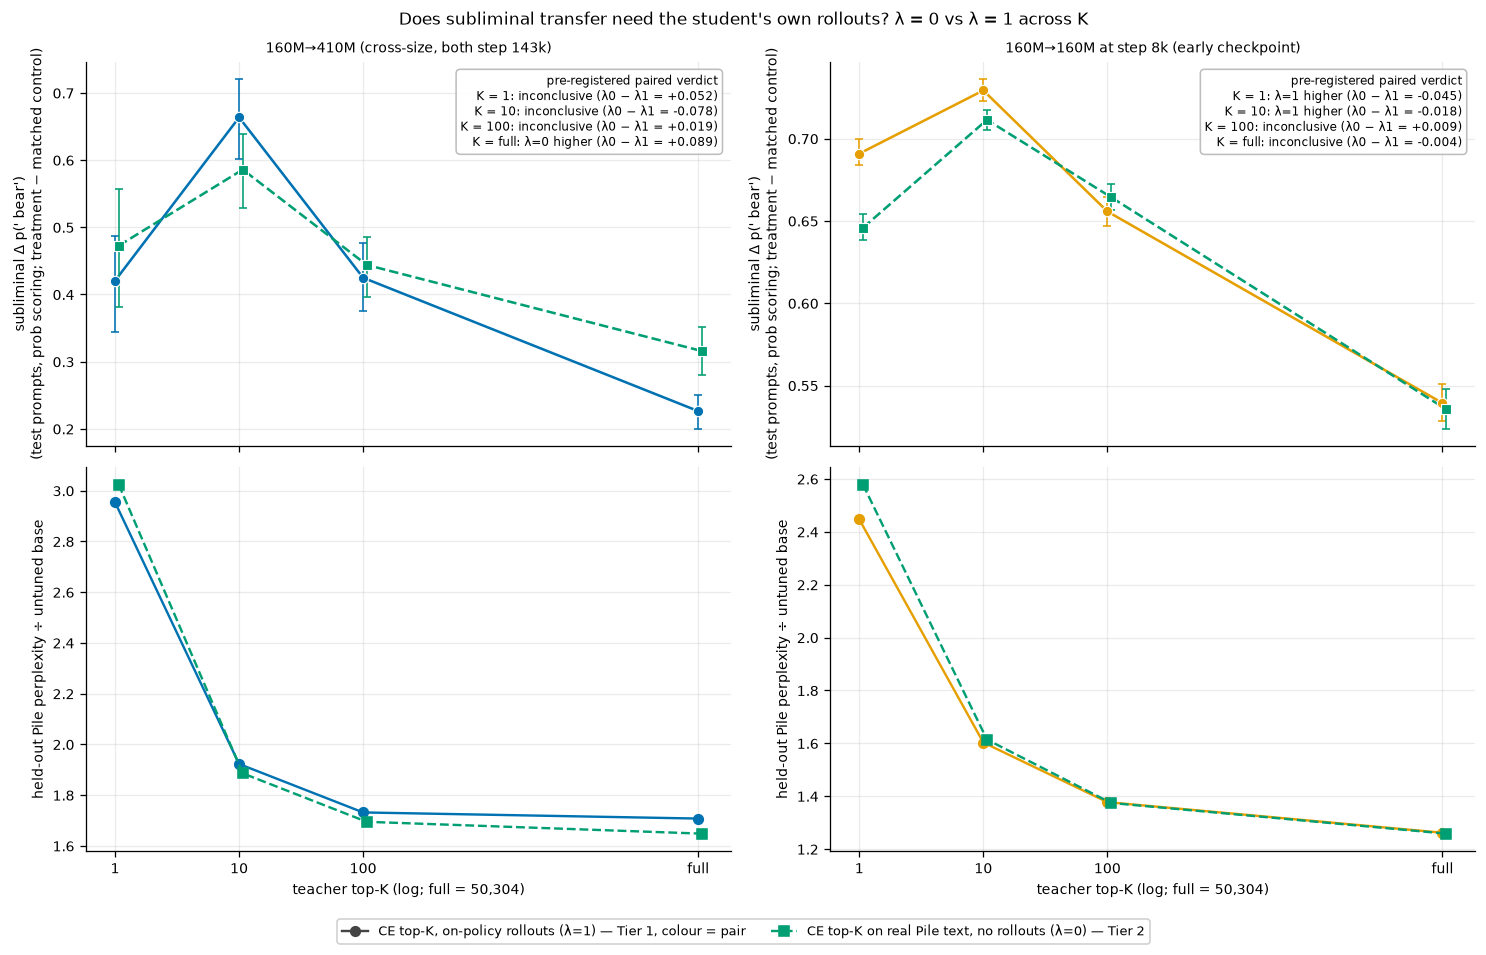

In [27]:
lam = TAB[2]["lambda"].copy()
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for j, pair in enumerate(("P1", "P4")):
    on = LADDER.loc[LADDER["pair"].eq(pair) & LADDER["k"].isin([1, 10, 100, K_FULL])].sort_values("k")
    off = cells.loc[cells["pair"].eq(pair) & cells["arm"].eq("lmb0")].sort_values("k")
    ax = axes[0, j]
    plot_ci(ax, on["k"], on["mean_delta_p"], on["ci_low_p"], on["ci_high_p"], color=PAIR_COLOR[pair], marker="o")
    plot_ci(ax, off["k"] * 1.07, off["mean_delta_p"], off["ci_low_p"], off["ci_high_p"], color="#009E73", marker="s", ls="--")
    rows = [f"K = {k_tick(r['k'])}: {r['label'].replace('_', ' ').replace('lambda', 'λ=')} (λ0 − λ1 = {r['d']:+.3f})"
            for _, r in lam.loc[lam["pair"].eq(pair)].sort_values("k").iterrows()]
    verdict_box(ax, rows, "pre-registered paired verdict")
    ax.set_title(PAIR_LABEL[pair], fontsize=9)
    ax.set_ylabel(DELTA_P)
    ax = axes[1, j]
    ax.plot(on["k"], on["mean_ppl_ratio"], color=PAIR_COLOR[pair], marker="o")
    ax.plot(off["k"] * 1.07, off["mean_ppl_ratio"], color="#009E73", marker="s", ls="--")
    ax.set_ylabel("held-out Pile perplexity ÷ untuned base")
    style_k_axis(ax, ks=(1, 10, 100, K_FULL), label=False)
    ax.set_xlabel("teacher top-K (log; full = 50,304)")
style_k_axis(axes[0, 0], ks=(1, 10, 100, K_FULL), label=False)
style_k_axis(axes[0, 1], ks=(1, 10, 100, K_FULL), label=False)
fig.legend(handles=[Line2D([], [], color="#444444", marker="o", label=ARM_LABEL["ce"] + " — Tier 1, colour = pair"),
                    Line2D([], [], color="#009E73", marker="s", ls="--", label=ARM_LABEL["lmb0"] + " — Tier 2")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Does subliminal transfer need the student's own rollouts? λ = 0 vs λ = 1 across K")
fig.tight_layout()
plt.show()

**Question answered:** Does subliminal transfer need the student's own rollouts?

**Conclusion from the plot:** No — λ = 0 on real Pile text transfers at every K on both pairs (Δ 0.32–0.59 on 160M→410M, 0.54–0.71 on 160M@8k), is statistically indistinguishable from on-policy in 5 of 8 cells, higher at full vocabulary on 160M→410M (+0.09) and slightly lower at K = 10 and 1 on 160M@8k (−0.02, −0.05), with near-identical perplexity cost.

In [28]:
screen_t2 = TAB[2]["screen"].copy()
screen_t2["pair"] = screen_t2["pair"].map(PAIR_SHORT)
print("λ = 0 off-policy bear screen on real Pile text (rows flagged ÷ rows screened):")
display(screen_t2[["pair", "objective", "kind", "n_leaves", "n_off_policy_rows_screened", "n_off_policy_flagged", "off_policy_flag_frac"]])
print("λ = 1 on-policy rollout screen drop (mean over training) at the same K, for comparison:")
display(cells.loc[cells["tier"].eq(1) & cells["block"].str.match(r"^ce-(full|k1|k10|k100)$") & cells["pair"].isin(["P1", "P4"]),
                  ["pair", "objective", "mean_filter_drop"]].assign(pair=lambda d: d["pair"].map(PAIR_SHORT)).round(3))

λ = 0 off-policy bear screen on real Pile text (rows flagged ÷ rows screened):


,pair,objective,kind,n_leaves,n_off_policy_rows_screened,n_off_policy_flagged,off_policy_flag_frac
0,160M→410M,lmb0-full,tb_control,3,60000.0,6.0,0.0001
1,160M→410M,lmb0-full,treatment,9,180000.0,18.0,0.0001
2,160M@8k→160M@8k,lmb0-full,sb_control,3,60000.0,6.0,0.0001
3,160M@8k→160M@8k,lmb0-full,treatment,9,180000.0,18.0,0.0001
4,160M→410M,lmb0-k1,tb_control,3,60000.0,6.0,0.0001
5,160M→410M,lmb0-k1,treatment,9,180000.0,18.0,0.0001
6,160M@8k→160M@8k,lmb0-k1,sb_control,3,60000.0,6.0,0.0001
7,160M@8k→160M@8k,lmb0-k1,treatment,9,180000.0,18.0,0.0001
8,160M→410M,lmb0-k10,tb_control,3,60000.0,6.0,0.0001
9,160M→410M,lmb0-k10,treatment,9,180000.0,18.0,0.0001


λ = 1 on-policy rollout screen drop (mean over training) at the same K, for comparison:


,pair,objective,mean_filter_drop
0,160M→410M,full,0.213
3,160M@8k→160M@8k,full,0.182
4,160M→410M,k1,0.328
7,160M@8k→160M@8k,k1,0.209
8,160M→410M,k10,0.290
11,160M@8k→160M@8k,k10,0.257
12,160M→410M,k100,0.248
15,160M@8k→160M@8k,k100,0.207


## 13. Unique-prompt ladder at a fixed 625 steps (pre-registered N0, N1, N2; novel ablation)

**What this measures.** Every student takes exactly 625 optimizer steps with batch 32, but draws its prompts from
a nested, register-stratified subset of N ∈ {625, 1250, 2500, 5000, 10000, 20000} unique Pile prompts (N = 625
revisits each prompt ~32 times). N1: OLS slope of Δ on log₂ N with a leaf bootstrap — `data_limited` if > 0,
`flat` if inside ±0.01 per doubling. N_sat = smallest N reaching 90 % of the N = 20,000 mean. The unique-data
objection (Feng et al.) predicts a positive slope; the slbreadth prior (trait installed within ≤ 50 steps)
predicts flat. N0 checks that the fixed-step code path at N = 20,000 reproduces the epoch-budget ladder.

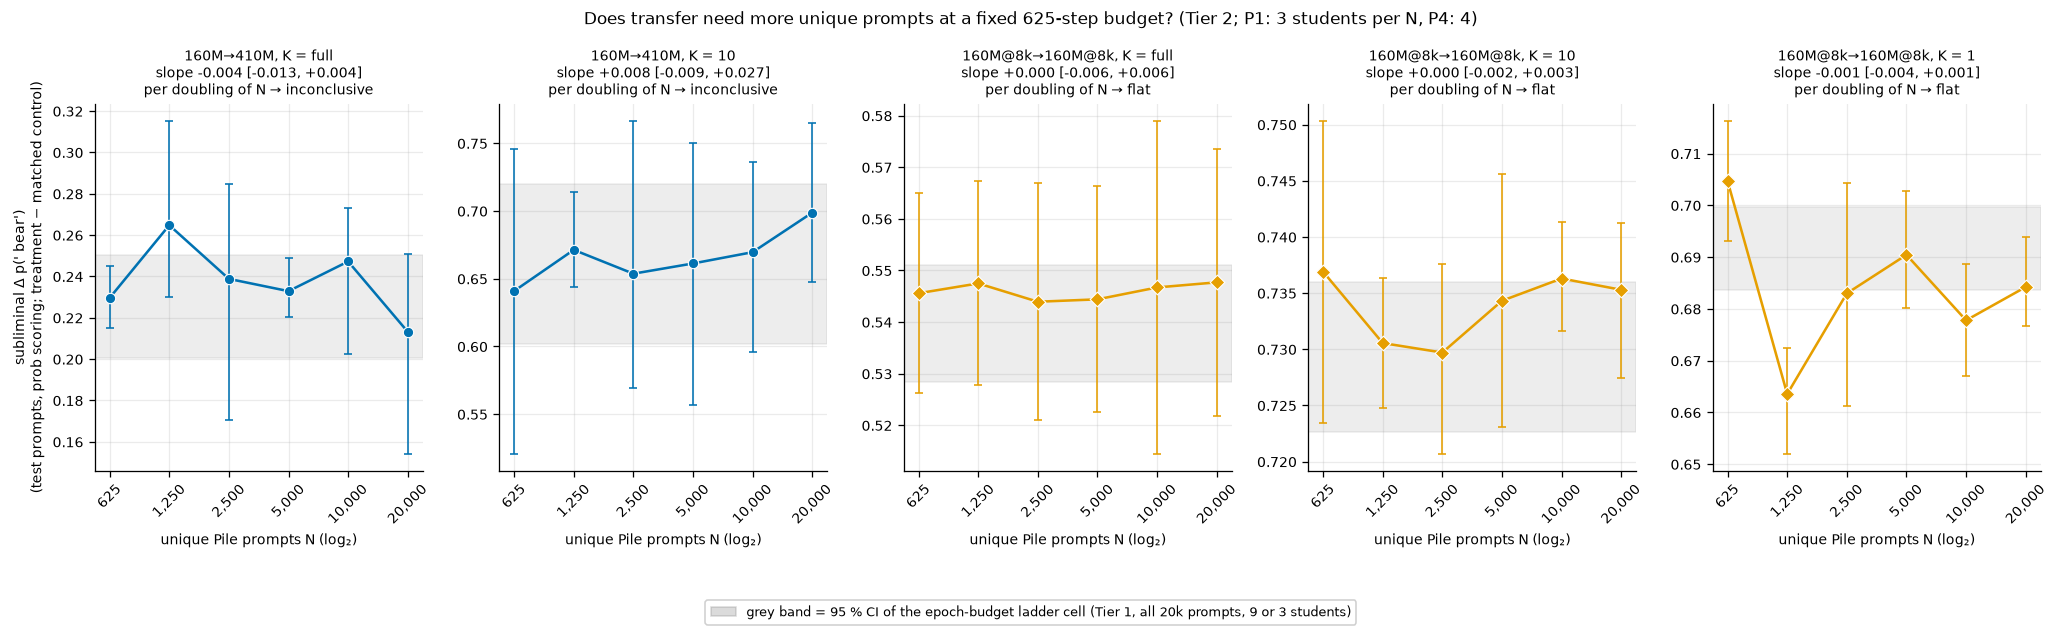

In [29]:
dcurve = TAB[2]["data_curve"].copy()
dslope = TAB[2]["data_slope"].copy()
panels = [("P1", K_FULL), ("P1", 10), ("P4", K_FULL), ("P4", 10), ("P4", 1)]
fig, axes = plt.subplots(1, 5, figsize=(18, 4.9))
for ax, (pair, k) in zip(axes, panels, strict=True):
    sub = dcurve.loc[dcurve["pair"].eq(pair) & dcurve["k"].eq(k)].sort_values("subset_n")
    plot_ci(ax, sub["subset_n"], sub["mean_delta_p"], sub["ci_low_p"], sub["ci_high_p"], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair])
    ref_cell = LADDER.loc[LADDER["pair"].eq(pair) & LADDER["k"].eq(k)]
    if not ref_cell.empty:
        ax.axhspan(ref_cell["ci_low_p"].iloc[0], ref_cell["ci_high_p"].iloc[0], color="#888888", alpha=0.15)
    s = dslope.loc[dslope["pair"].eq(pair) & dslope["k"].eq(k)].iloc[0]
    ax.set_title(f"{PAIR_SHORT[pair]}, K = {k_tick(k)}\nslope {s['slope']:+.3f} [{s['ci_low']:+.3f}, {s['ci_high']:+.3f}]\nper doubling of N → {s['label']}",
                 fontsize=8.5)
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(sub["subset_n"].unique()), [f"{int(n):,}" for n in sorted(sub["subset_n"].unique())], rotation=45)
    ax.minorticks_off()
    ax.set_xlabel("unique Pile prompts N (log₂)")
axes[0].set_ylabel(DELTA_P)
fig.legend(handles=[Patch(color="#888888", alpha=0.3, label="grey band = 95 % CI of the epoch-budget ladder cell (Tier 1, all 20k prompts, 9 or 3 students)")],
           loc="lower center", bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Does transfer need more unique prompts at a fixed 625-step budget? (Tier 2; P1: 3 students per N, P4: 4)")
fig.tight_layout()
plt.show()

**Question answered:** Does transfer need more unique prompts at a fixed 625-step budget?

**Conclusion from the plot:** No data limitation is visible: every N from 625 to 20,000 lands inside or next to the epoch-budget CI, the 160M@8k slopes are flat (|slope| ≤ 0.002 per doubling), and the 160M→410M slopes are only inconclusive because 3 students per N give wide CIs; N_sat = 625 everywhere.

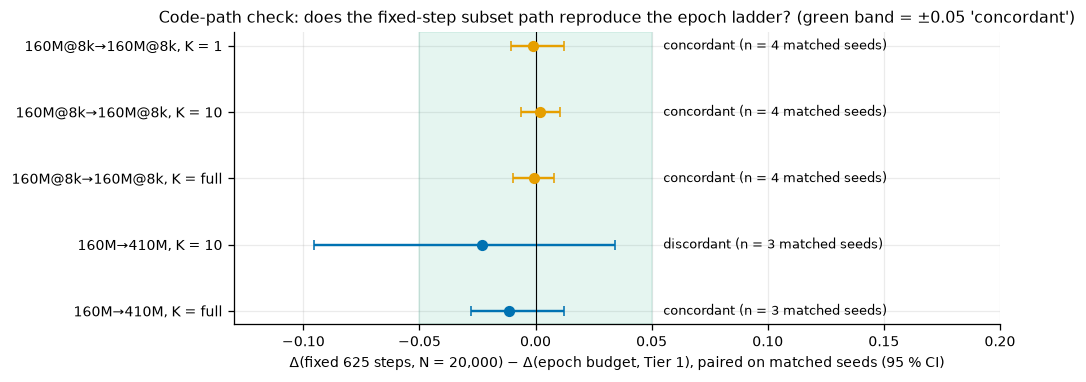

In [30]:
conc = TAB[2]["data_concordance"].copy().reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.4))
band = 0.05
ax.axvspan(-band, band, color="#009E73", alpha=0.1)
for i, row in conc.iterrows():
    color = PAIR_COLOR[row["pair"]]
    ax.errorbar(row["mean_diff"], i, xerr=[[row["mean_diff"] - row["ci_low"]], [row["ci_high"] - row["mean_diff"]]], fmt="o", color=color, capsize=3)
    ax.text(max(row["ci_high"], band) + 0.005, i, f"{row['label']} (n = {int(row['n_pairs'])} matched seeds)", va="center", fontsize=8)
ax.axvline(0, color="black", lw=0.7)
ax.set_yticks(range(len(conc)), [f"{PAIR_SHORT[p]}, K = {k_tick(k)}" for p, k in zip(conc["pair"], conc["k"], strict=True)])
ax.set_xlim(-0.13, 0.2)
ax.set_xlabel("Δ(fixed 625 steps, N = 20,000) − Δ(epoch budget, Tier 1), paired on matched seeds (95 % CI)")
ax.set_title("Code-path check: does the fixed-step subset path reproduce the epoch ladder? (green band = ±0.05 'concordant')")
fig.tight_layout()
plt.show()

**Question answered:** Does the fixed-step subset code path reproduce the epoch-budget ladder at N = 20,000?

**Conclusion from the plot:** Yes within ±0.05 for four of five cells (all 160M@8k cells and 160M→410M at full vocabulary, |mean difference| ≤ 0.011); 160M→410M at K = 10 is labelled discordant because its 3-seed CI (−0.095, +0.034) is wider than the band, while its mean moved only −0.023.

## 13b. Off-policy data-quantity ladder at a fixed 625 steps (Tier 3, λ = 0; pre-registered N3, plus N4 and N0b)

**What this measures.** §13 varied the number of unique *prompts* under on-policy rollouts, where every revisit
samples a fresh continuation — so every rung trained on ~20,000 distinct sequences and N1 measured prompt
diversity, not data quantity. Tier 3 repeats the ladder at **λ = 0**: the continuation is the real Pile text,
pre-tokenised once, with frozen teacher targets, so a revisit is a literal repeat and N is the number of
distinct training texts. Same recipe (CE forward KL, full vocabulary, β = 0, LoRA r8 α16, lr 4e-4, batch 32),
same 625 steps, same nested register-stratified subsets at `prompt_subset_seed` 0 where the sizes coincide,
extended to N ∈ {20000, 5000, 1250, 625, 312, 156, 64} (N = 64 is two batches, ~312 passes per row). Pairs:
160M@8k→160M@8k (4 students per N + 2 controls) and 160M→410M (3 + 2); K = 10 on the step-8k pair and a second
subset draw (`d1`) at N ∈ {625, 64} are descriptive tails.

**Hypotheses** (`docs/PREREG_OPDLIM.md` §9.10; `.claude/plans/data_quantity_regimes_context.md`). *Flat*: the
teacher's tilt is low-dimensional and present in every row, so a few hundred texts pin it down and repeats are
just more optimisation. *Data-limited* (Muennighoff et al. 2023: repetition ≈ unique data only up to ~4 passes):
below some N the student fits the teacher's distributions on those texts instead of the general rule, so Δ
falls with N and `final_train_loss` collapses. **N3** = OLS slope of leaf Δ on log₂ N at λ = 0 (first draw only),
N1's estimator and labels. **N4** = slope(λ = 0) − slope(λ = 1) on the four shared rungs (625–20,000),
independent bootstraps; `equivalent` if the CI sits inside ±0.01 per doubling. **N0b** = the λ = 0 fixed-step
N = 20,000 cells against the Tier 2 λ = 0 epoch-budget cells, paired on matched seeds; `concordant` inside ±0.05.

In [31]:
TIER3 = plan.TIER3
TREE3 = OUTPUT_ROOT / run_set_subdir(GKD_STUDENTS_SUBDIR, TIER3.run_set_id)
RES3, LOGS3 = TREE3 / "results", TREE3 / "logs"
TAB3 = {name.removeprefix("opdlim_").removesuffix(".csv"): read_csv(RES3 / name) for name in (*plan.RESULTS_FILES_COMMON, *plan.RESULTS_FILES_T3)}
CLAIMS[3] = json.loads((RES3 / plan.RESULTS_CLAIMS_JSON).read_text())
STATE3 = json.loads((LOGS3 / plan.CAMPAIGN_STATE_FILE).read_text())
tail3 = [b.name for b in TIER3.tail_blocks() if f"results_{b.name}" not in STATE3["transitions"]]
cells3, deltas3, leaves3 = TAB3["cells"], TAB3["delta"], TAB3["leaves"]
cells3 = cells3.merge(
    TAB3["capability"][CELL_ID + [c for c in TAB3["capability"].columns if c.startswith("mean_") and c not in cells3.columns]],
    on=CELL_ID, how="left", validate="one_to_one",
)
SEED0 = lambda frame: ~frame["objective"].astype(str).str.contains(r"d\d+$", regex=True)
print(f"tier 3 run set   : {TIER3.run_set_id}  ->  {TREE3.resolve()}")
print("tier 3: " + ", ".join(f"{k}={len(v)}" for k, v in TAB3.items()))
print("core finalized:", (LOGS3 / plan.CAMPAIGN_DONE_FILE).is_file(), "| tail blocks still pending:", tail3 or "none")
cov3 = TAB3["coverage"]
print(f"coverage: {int(cov3['n_present'].sum())} of {int(cov3['n_expected'].sum())} planned leaves present; quarantined: {len(TAB3['quarantine'])}")

tier 3 run set   : 20260922_opdlim3-bear_mixed  ->  /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260922_opdlim3-bear_mixed
tier 3: leaves=141, delta=91, cells=25, curve=25, kstar=18, capability=25, telemetry=50, quarantine=0, coverage=50, screen=50, data_curve=21, data_slope=3
core finalized: True | tail blocks still pending: none
coverage: 141 of 141 planned leaves present; quarantined: 0


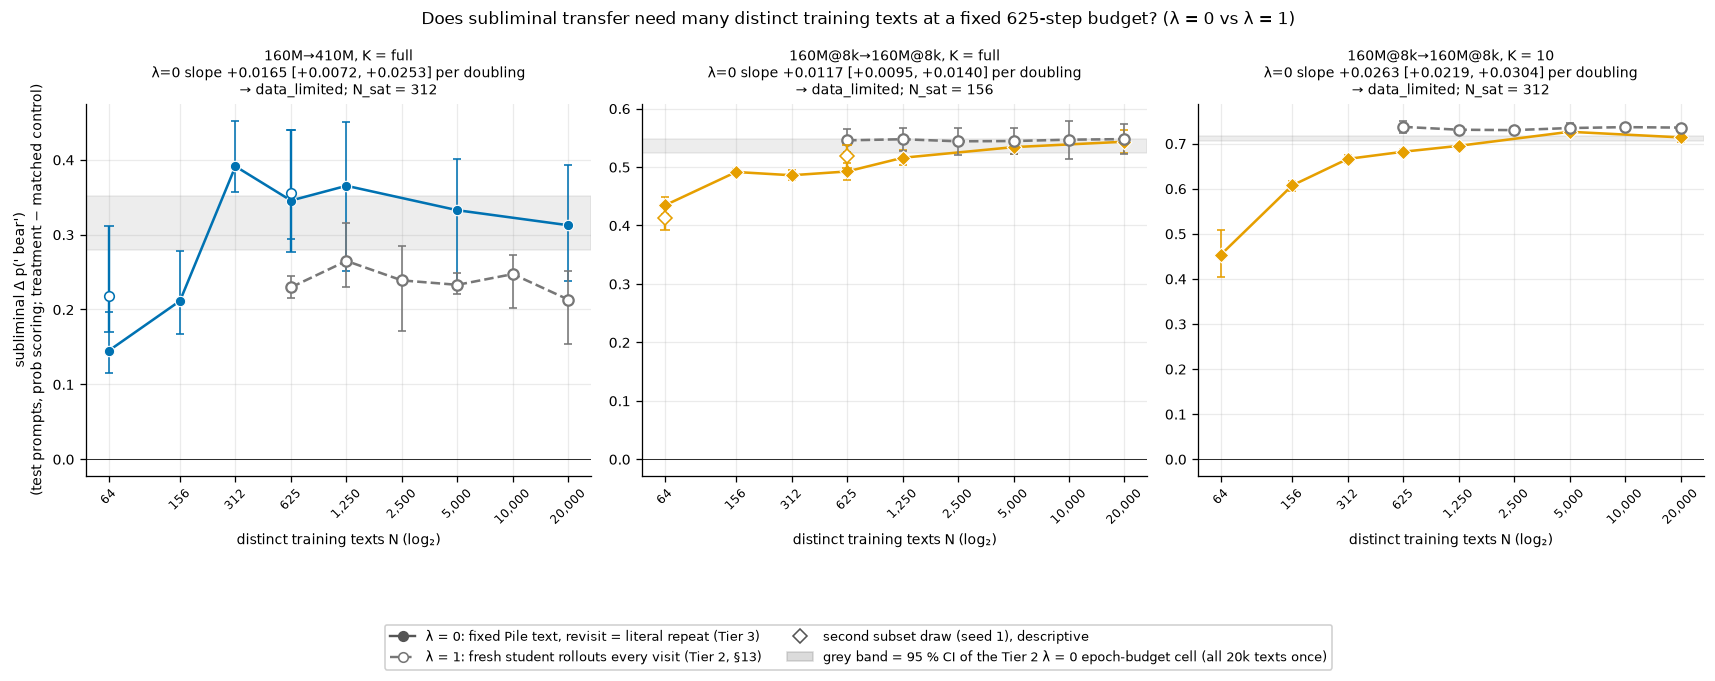

In [32]:
d3 = TAB3["data_curve"]
s3 = TAB3["data_slope"]
d2 = TAB[2]["data_curve"]
anchor = cells[cells["tier"].eq(2) & cells["lmbda"].eq(0.0) & cells["subset_n"].isna() & cells["hp_lr"].eq(plan.HP_BASE.lr)]
panels = [("P1", K_FULL), ("P4", K_FULL), ("P4", 10)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9))
for ax, (pair, k) in zip(axes, panels, strict=True):
    sub = d3.loc[d3["pair"].eq(pair) & d3["k"].eq(k)].sort_values("subset_n")
    plot_ci(ax, sub["subset_n"], sub["mean_delta_p"], sub["ci_low_p"], sub["ci_high_p"], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair])
    ref = d2.loc[d2["pair"].eq(pair) & d2["k"].eq(k)].sort_values("subset_n")
    if not ref.empty:
        plot_ci(ax, ref["subset_n"], ref["mean_delta_p"], ref["ci_low_p"], ref["ci_high_p"], color="#777777", marker="o", filled=False, ls="--")
    extra = cells3.loc[cells3["pair"].eq(pair) & cells3["k"].eq(k) & ~SEED0(cells3)]
    for _, row in extra.iterrows():
        ax.errorbar(row["subset_n"], row["mean_delta_p"], yerr=[[row["mean_delta_p"] - row["ci_low_p"]], [row["ci_high_p"] - row["mean_delta_p"]]],
                    fmt=PAIR_MARKER[pair], mfc="white", color=PAIR_COLOR[pair], capsize=3, zorder=4)
    a = anchor.loc[anchor["pair"].eq(pair) & anchor["k"].eq(k)]
    if not a.empty:
        ax.axhspan(a["ci_low_p"].iloc[0], a["ci_high_p"].iloc[0], color="#888888", alpha=0.15)
    s = s3.loc[s3["pair"].eq(pair) & s3["k"].eq(k)]
    if not s.empty:
        s = s.iloc[0]
        ax.set_title(f"{PAIR_SHORT[pair]}, K = {k_tick(k)}\nλ=0 slope {s['slope']:+.4f} [{s['ci_low']:+.4f}, {s['ci_high']:+.4f}] per doubling\n→ {s['label']}"
                     + (f"; N_sat = {int(s['n_sat']):,}" if pd.notna(s["n_sat"]) else ""), fontsize=8.5)
    ns = sorted(set(sub["subset_n"]).union(ref["subset_n"]))
    ax.set_xscale("log", base=2)
    ax.set_xticks(ns, [f"{int(n):,}" for n in ns], rotation=45, fontsize=7.5)
    ax.minorticks_off()
    ax.axhline(0, color="black", lw=0.5)
    ax.set_xlabel("distinct training texts N (log₂)")
axes[0].set_ylabel(DELTA_P)
fig.legend(handles=[Line2D([], [], color="#555555", marker="o", label="λ = 0: fixed Pile text, revisit = literal repeat (Tier 3)"),
                    Line2D([], [], color="#777777", marker="o", mfc="white", ls="--", label="λ = 1: fresh student rollouts every visit (Tier 2, §13)"),
                    Line2D([], [], color="#555555", marker="D", mfc="white", ls="", label="second subset draw (seed 1), descriptive"),
                    Patch(color="#888888", alpha=0.3, label="grey band = 95 % CI of the Tier 2 λ = 0 epoch-budget cell (all 20k texts once)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.2))
fig.suptitle("Does subliminal transfer need many distinct training texts at a fixed 625-step budget? (λ = 0 vs λ = 1)")
fig.tight_layout()
plt.show()

**Question answered:** When a revisit is a literal repeat (λ = 0, fixed Pile text), does transfer need many distinct training texts at a fixed 625 steps?

**Conclusion from the plot:** Only below a few hundred texts: on 160M@8k Δ falls from 0.54 at N = 20,000 to ≈0.49 at 625–156 and 0.43 at 64 (slope +0.012 per doubling, data_limited, N_sat = 156), and on 160M→410M from ≈0.31–0.39 at N ≥ 312 to 0.21 at 156 and 0.14 at 64; above ~300 texts the λ = 0 curve is flat and sits on the λ = 1 curve (160M@8k) or above it (160M→410M), the fixed-step N = 20,000 cells reproduce the λ = 0 epoch-budget cells (N0b concordant), and K = 10 loses more at small N than the full vocabulary.

In [33]:
from subliminal_learning.campaign import opdlim_metrics as om

SHARED_N = [n for n in plan.N_LADDER_T3 if n in plan.N_LADDER_ORDER]
BOOT3 = {"n_boot": 4000}
rows_n4, rows_n0b = [], []
for pair, k in [("P1", K_FULL), ("P4", K_FULL), ("P4", 10)]:
    t3 = deltas3.loc[deltas3["kind"].eq("treatment") & deltas3["pair"].eq(pair) & deltas3["k"].eq(k) & deltas3["subset_n"].isin(SHARED_N) & SEED0(deltas3)]
    t2 = deltas.loc[deltas["tier"].eq(2) & deltas["kind"].eq("treatment") & deltas["pair"].eq(pair) & deltas["k"].eq(k) & deltas["lmbda"].eq(1.0)
                    & deltas["subset_n"].isin(SHARED_N) & deltas["hp_lr"].eq(plan.HP_BASE.lr)]
    b3, dr3 = om._slope_draws(t3, rng=np.random.default_rng(plan.BOOTSTRAP_SEED), **BOOT3)
    b2, dr2 = om._slope_draws(t2, rng=np.random.default_rng(plan.BOOTSTRAP_SEED + 1), **BOOT3)
    if dr3.size and dr2.size:
        diff = dr3 - dr2
        lo, hi = np.percentile(diff, 2.5), np.percentile(diff, 97.5)
        label = "equivalent" if -plan.FLAT_SLOPE_BAND <= lo and hi <= plan.FLAT_SLOPE_BAND else "lambda0_steeper" if lo > 0 else "lambda1_steeper" if hi < 0 else "inconclusive"
    else:
        lo = hi = float("nan"); label = "void"
    rows_n4.append({"pair": pair, "k": k, "slope_lmb0": b3, "slope_lmb1": b2, "diff": b3 - b2, "ci_low": lo, "ci_high": hi, "label": label,
                    "n_leaves_lmb0": int(len(t3)), "n_leaves_lmb1": int(len(t2)), "rungs": SHARED_N})
    left = deltas3.loc[deltas3["kind"].eq("treatment") & deltas3["pair"].eq(pair) & deltas3["k"].eq(k) & deltas3["subset_n"].eq(plan.POOL_N_PROMPTS) & SEED0(deltas3)]
    right = deltas.loc[deltas["tier"].eq(2) & deltas["kind"].eq("treatment") & deltas["pair"].eq(pair) & deltas["k"].eq(k) & deltas["lmbda"].eq(0.0)
                       & deltas["subset_n"].isna() & deltas["hp_lr"].eq(plan.HP_BASE.lr)]
    c = om.paired_contrast(left, right, n_boot=plan.BOOTSTRAP_N, seed=plan.BOOTSTRAP_SEED)
    lo, hi = c["ci_low"], c["ci_high"]
    lab = "void" if not (np.isfinite(lo) and np.isfinite(hi)) else "concordant" if -plan.CONCORDANCE_BAND <= lo and hi <= plan.CONCORDANCE_BAND else "discordant"
    rows_n0b.append({"pair": pair, "k": k, "mean_diff": c["mean"], "ci_low": lo, "ci_high": hi, "n_pairs": c["n_pairs"], "label": lab})
LMB0_N4 = pd.DataFrame(rows_n4)
LMB0_N0B = pd.DataFrame(rows_n0b)
print("N4: slope(λ=0) − slope(λ=1) on the shared rungs", SHARED_N, "(per doubling of N; 'equivalent' = CI inside ±0.01)")
display(LMB0_N4.drop(columns="rungs").round(4))
print("N0b: λ=0 fixed-step N=20,000 (Tier 3) − λ=0 epoch budget (Tier 2), paired on matched seeds ('concordant' = CI inside ±0.05)")
display(LMB0_N0B.round(4))

N4: slope(λ=0) − slope(λ=1) on the shared rungs [20000, 5000, 1250, 625] (per doubling of N; 'equivalent' = CI inside ±0.01)


,pair,k,slope_lmb0,slope_lmb1,diff,ci_low,ci_high,label,n_leaves_lmb0,n_leaves_lmb1
0,P1,50304,-0.0085,-0.0059,-0.0026,-0.0242,0.0196,inconclusive,12,12
1,P4,50304,0.0096,0.0002,0.0095,0.0019,0.0174,lambda0_steeper,16,16
2,P4,10,0.0071,0.0001,0.0070,0.0036,0.0104,lambda0_steeper,16,16


N0b: λ=0 fixed-step N=20,000 (Tier 3) − λ=0 epoch budget (Tier 2), paired on matched seeds ('concordant' = CI inside ±0.05)


,pair,k,mean_diff,ci_low,ci_high,n_pairs,label
0,P1,50304,-0.0115,-0.0286,0.0068,3,concordant
1,P4,50304,-0.0001,-0.0006,0.0005,4,concordant
2,P4,10,0.0003,0.0000,0.0005,4,concordant


In [34]:
logs3 = load_gkd_training_logs(OUTPUT_ROOT, run_set_subdir(GKD_STUDENTS_SUBDIR, TIER3.run_set_id), animals=list(plan.ANIMALS))
logs3 = logs3.loc[~logs3["is_control"].astype(bool)].copy()
logs3["pair"] = pair_of(logs3)
last3 = logs3.sort_values("step").groupby(["pair", "gkd_tag", "teacher_tag", "gseed"]).tail(1)
loss3 = last3.groupby(["pair", "gkd_tag"]).agg(final_train_loss=("loss", "mean"), epochs_reached=("epoch", "max")).reset_index()
loss3["subset_n"] = loss3["gkd_tag"].str.extract(r"_n(\d+)", expand=False).astype(float)
loss3["k"] = pd.to_numeric(loss3["gkd_tag"].str.extract(r"_topce(\d+)$", expand=False)).fillna(K_FULL)
loss3["draw"] = loss3["gkd_tag"].str.extract(r"_n\d+d(\d+)", expand=False).fillna("0")
scr3 = TAB3["screen"].loc[TAB3["screen"]["kind"].eq("treatment"), ["pair", "objective", "k", "off_policy_flag_frac"]]
tab = cells3.merge(scr3, on=["pair", "objective", "k"], how="left")
tab["draw"] = np.where(SEED0(tab), "0", "1")
tab = tab.merge(loss3[["pair", "subset_n", "k", "draw", "final_train_loss", "epochs_reached"]], on=["pair", "subset_n", "k", "draw"], how="left")
tab["passes_per_text"] = plan.DATA_MAX_STEPS * plan.STUDENT_EFFECTIVE_BATCH / tab["subset_n"]
show = (tab.loc[:, ["pair", "k", "draw", "subset_n", "n_live", "mean_delta_p", "ci_low_p", "ci_high_p", "t0", "passes_per_text", "epochs_reached",
                    "final_train_loss", "off_policy_flag_frac", "mean_ppl_ratio"]]
        .sort_values(["pair", "k", "draw", "subset_n"], ascending=[True, False, True, True]).reset_index(drop=True))
show["k"] = [k_tick(k) for k in show["k"]]
display(show.round(4))
print("passes_per_text = 625 × 32 / N; epochs_reached = the trainer's epoch counter at the last log; final_train_loss = mean last-logged")
print("CE-to-teacher loss over treatment students; off_policy_flag_frac = share of fixed rows the layer-2 screen masked (the same rows every pass).")

,pair,k,draw,subset_n,n_live,mean_delta_p,ci_low_p,ci_high_p,t0,passes_per_text,epochs_reached,final_train_loss,off_policy_flag_frac,mean_ppl_ratio
0,P1,full,0,64,3,0.1448,0.1151,0.1962,True,312.5000,310.0000,0.5732,0.0000,1.9151
1,P1,full,0,156,3,0.2114,0.1669,0.2782,True,128.2051,124.0000,0.7078,0.0000,1.8567
2,P1,full,0,312,3,0.3912,0.3571,0.4520,True,64.1026,62.0000,0.8469,0.0000,1.8381
3,P1,full,0,625,3,0.3455,0.2946,0.4396,True,32.0000,31.0000,1.0236,0.0000,1.7524
4,P1,full,0,1250,3,0.3652,0.2511,0.4509,True,16.0000,15.8974,1.2196,0.0000,1.7003
5,P1,full,0,5000,3,0.3326,0.2304,0.4011,True,4.0000,3.9744,1.4277,0.0004,1.6494
6,P1,full,0,20000,3,0.3125,0.2375,0.3929,True,1.0000,0.9920,1.5063,0.0001,1.6457
7,P1,full,1,64,3,0.2178,0.1699,0.3113,True,312.5000,310.0000,0.5840,0.0000,1.8803
8,P1,full,1,625,3,0.3561,0.2761,0.4397,True,32.0000,31.0000,1.0291,0.0000,1.7620
9,P4,full,0,64,4,0.4343,0.4201,0.4486,True,312.5000,310.0000,0.0024,0.0000,1.2249


passes_per_text = 625 × 32 / N; epochs_reached = the trainer's epoch counter at the last log; final_train_loss = mean last-logged
CE-to-teacher loss over treatment students; off_policy_flag_frac = share of fixed rows the layer-2 screen masked (the same rows every pass).


## 13c. Data quantity vs subliminal transfer (paper figure)

**What this shows.** One panel: the headline Δ p(' bear') against the number of distinct Pile texts the student was
distilled on, at a fixed 625 optimizer steps (batch 32, so every rung sees 20,000 training sequences and only the
number of *distinct* ones changes). Solid lines are the off-policy ladder (λ = 0, Tier 3, full vocabulary); dashed
lines are the on-policy ladder (λ = 1, Tier 2, §13) on its 625–20,000 range. Error bars are 95 % leaf-bootstrap
CIs; the arrow marks N_sat, the smallest N reaching 90 % of the N = 20,000 value.

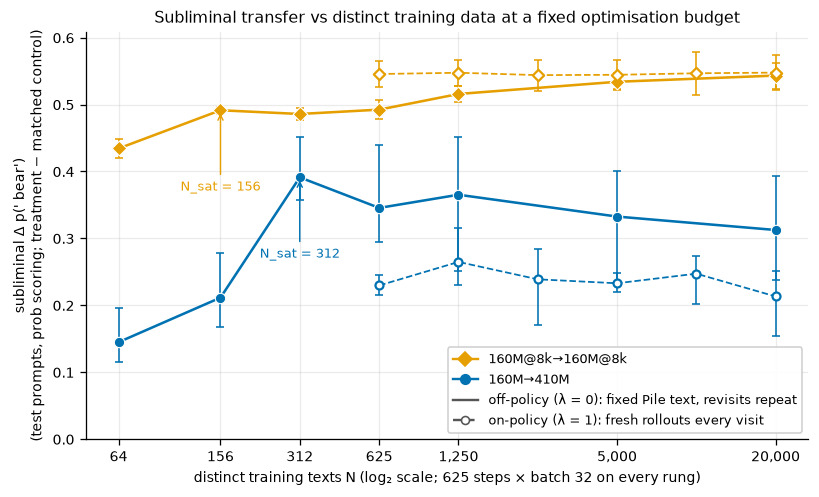

In [35]:
d3 = TAB3["data_curve"]
d2 = TAB[2]["data_curve"]
s3 = TAB3["data_slope"]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for pair in ("P4", "P1"):
    off = d3.loc[d3["pair"].eq(pair) & d3["k"].eq(K_FULL)].sort_values("subset_n")
    on = d2.loc[d2["pair"].eq(pair) & d2["k"].eq(K_FULL)].sort_values("subset_n")
    plot_ci(ax, off["subset_n"], off["mean_delta_p"], off["ci_low_p"], off["ci_high_p"], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair])
    plot_ci(ax, on["subset_n"], on["mean_delta_p"], on["ci_low_p"], on["ci_high_p"], color=PAIR_COLOR[pair], marker=PAIR_MARKER[pair], filled=False, ls="--", ms=5, lw=1.1)
    s = s3.loc[s3["pair"].eq(pair) & s3["k"].eq(K_FULL)].iloc[0]
    if pd.notna(s["n_sat"]):
        y = off.loc[off["subset_n"].eq(s["n_sat"]), "mean_delta_p"].iloc[0]
        ax.annotate(f"N_sat = {int(s['n_sat']):,}", xy=(s["n_sat"], y), xytext=(s["n_sat"], y - 0.12), ha="center", fontsize=8,
                    color=PAIR_COLOR[pair], arrowprops={"arrowstyle": "->", "color": PAIR_COLOR[pair], "lw": 0.9})
ns = sorted(d3["subset_n"].unique())
ax.set_xscale("log", base=2)
ax.set_xticks(ns, [f"{int(n):,}" for n in ns])
ax.minorticks_off()
ax.axhline(0, color="black", lw=0.5)
ax.set_ylim(0, None)
ax.set_xlabel("distinct training texts N (log₂ scale; 625 steps × batch 32 on every rung)")
ax.set_ylabel(DELTA_P)
handles = [Line2D([], [], color=PAIR_COLOR[p], marker=PAIR_MARKER[p], label=PAIR_SHORT[p]) for p in ("P4", "P1")]
handles += [Line2D([], [], color="#555555", ls="-", label="off-policy (λ = 0): fixed Pile text, revisits repeat"),
            Line2D([], [], color="#555555", ls="--", marker="o", mfc="white", ms=5, label="on-policy (λ = 1): fresh rollouts every visit")]
ax.legend(handles=handles, loc="lower right", fontsize=8)
ax.set_title("Subliminal transfer vs distinct training data at a fixed optimisation budget")
fig.tight_layout()
plt.show()

**Question answered:** How does subliminal transfer vary with the amount of distinct training data at a fixed budget?

**Conclusion from the plot:** It saturates: transfer rises steeply from 64 to a few hundred distinct texts (160M@8k: 0.43 → 0.49; 160M→410M: 0.14 → 0.39) and is flat from ~300 to 20,000 (a 64× range), with N_sat = 156 and 312; over its 625–20,000 range the on-policy ladder (dashed) is equally flat, on the same plateau for 160M@8k and lower (≈0.23 vs ≈0.35) for 160M→410M.

## 14. In-training probe trajectories

**What this measures.** Every 25 optimizer steps each student was probed on the first 10 consensus-salience
prompts (a **different prompt bank** from the headline `test` set) for p(' bear') and held-out perplexity. The
Δ trajectory subtracts the matched control at the same step and GKD seed (same run set, student, teacher base,
objective tag). Resumed students logged duplicate probe rows; the last row per step is kept. A probe is flagged
`diverged` when perplexity exceeds 10× its step-0 value.

In [36]:
def load_probes(n: int) -> pd.DataFrame:
    frame = load_gkd_probe_trajectories(OUTPUT_ROOT, run_set_subdir(GKD_STUDENTS_SUBDIR, TIERS[n].run_set_id), animals=list(plan.ANIMALS))
    raw = len(frame)
    frame = frame.sort_values(["run_dir", "step"]).drop_duplicates(["run_dir", "step"], keep="last").copy()
    frame["tier"] = n
    frame["pair"] = pair_of(frame)
    kg = frame["gkd_tag"].str.extract(r"_top(?:ce)?(\d+)(g?)$")
    frame["k"] = pd.to_numeric(kg[0]).fillna(K_FULL)
    frame["ghost"] = kg[1].eq("g")
    frame["ppl_ratio_step0"] = frame["ppl"] / frame.groupby("run_dir")["ppl"].transform("first")
    print(f"tier {n}: {raw} probe rows -> {len(frame)} after de-duplicating resumed students; {frame['run_dir'].nunique()} students")
    return frame


def probe_delta(frame: pd.DataFrame, metric: str = "p_target") -> pd.DataFrame:
    is_ctrl = frame["is_control"].astype(bool)
    keys = ["pair", "gkd_tag", "gseed", "step"]
    control = frame.loc[is_ctrl].groupby(keys)[metric].mean().rename("control")
    out = frame.loc[~is_ctrl].join(control, on=keys)
    out["delta"] = out[metric] - out["control"]
    return out


PROBES = {n: load_probes(n) for n in TIERS}
ladder_probe = PROBES[1].loc[PROBES[1]["gkd_tag"].isin(LADDER_TAG_K) & (PROBES[1]["is_control"].astype(bool) | PROBES[1]["teacher_param_tag"].eq(plan.TEACHER_TAG_EP5))]
LADDER_TRAJ = probe_delta(ladder_probe)
scope(LADDER_TRAJ, "frozen-recipe treatment probe rows with a matched control", "rows")
diverged = PROBES[1].groupby("run_dir").agg(pair=("pair", "first"), k=("k", "first"), control=("is_control", "first"), diverged=("diverged", "any"))
print("students with any diverged probe (tier 1):")
display(diverged.loc[diverged["diverged"]].groupby(["pair", "k", "control"]).size().rename("students").reset_index())

tier 1: 10865 probe rows -> 10764 after de-duplicating resumed students; 414 students


tier 2: 11778 probe rows -> 11778 after de-duplicating resumed students; 453 students
SCOPE · frozen-recipe treatment probe rows with a matched control: 5928 rows
students with any diverged probe (tier 1):


,pair,k,control,students
0,D,1.0,False,5
1,D,1.0,True,3
2,P3,1.0,False,3
3,P3,1.0,True,3
4,P3,2.0,True,2
5,P3,5.0,False,1
6,P3,5.0,True,1
7,P3,10.0,True,1


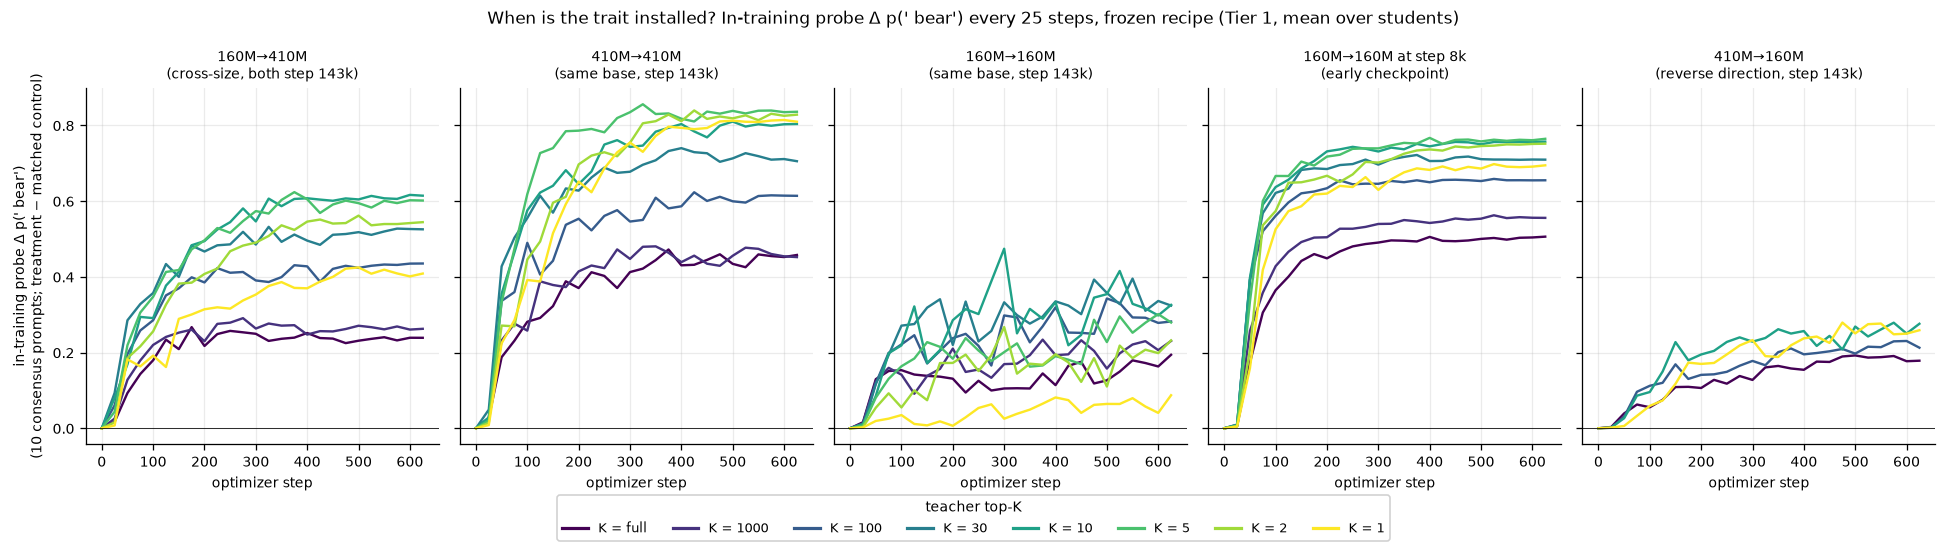

In [37]:
K_SEQ = [K_FULL, 1000, 100, 30, 10, 5, 2, 1]
cmap = mpl.colormaps["viridis"]
K_TRAJ_COLOR = {k: cmap(i / (len(K_SEQ) - 1)) for i, k in enumerate(K_SEQ)}
fig, axes = plt.subplots(1, 5, figsize=(17, 4.4), sharey=True)
for ax, pair in zip(axes, PAIR_ORDER, strict=True):
    sub = LADDER_TRAJ.loc[LADDER_TRAJ["pair"].eq(pair)]
    for k in K_SEQ:
        grp = sub.loc[sub["k"].eq(k)]
        if grp.empty:
            continue
        curve = grp.groupby("step")["delta"].mean()
        ax.plot(curve.index, curve.to_numpy(), color=K_TRAJ_COLOR[k], lw=1.5)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(PAIR_LABEL[pair].replace(" (", "\n("), fontsize=9)
    ax.set_xlabel("optimizer step")
axes[0].set_ylabel("in-training probe Δ p(' bear')\n(10 consensus prompts; treatment − matched control)")
fig.legend(handles=[Line2D([], [], color=K_TRAJ_COLOR[k], lw=2, label=f"K = {k_tick(k)}") for k in K_SEQ],
           loc="lower center", ncol=8, bbox_to_anchor=(0.5, -0.08), title="teacher top-K")
fig.suptitle("When is the trait installed? In-training probe Δ p(' bear') every 25 steps, frozen recipe (Tier 1, mean over students)")
fig.tight_layout()
plt.show()

**Question answered:** When during training is the trait installed, and does K change the onset or the plateau?

**Conclusion from the plot:** The probe Δ rises within the first ~100–200 steps and plateaus by ~300 steps on every pair; K mainly sets the plateau height rather than the onset (160M→410M: ≈ 0.61 at K = 10 vs ≈ 0.24 at full vocabulary), and 160M→160M at K = 1 stays lowest because those students degrade.

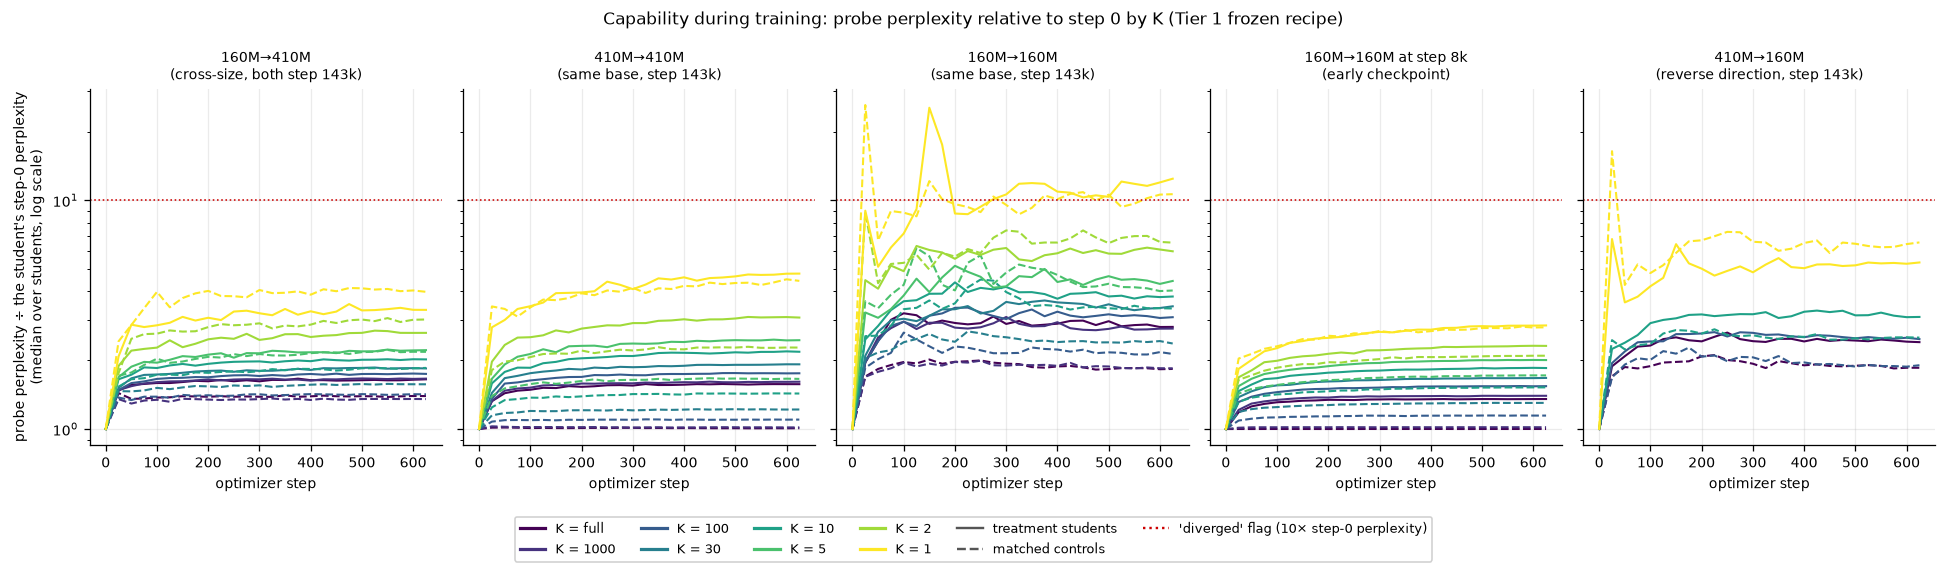

In [38]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4.4), sharey=True)
for ax, pair in zip(axes, PAIR_ORDER, strict=True):
    sub = ladder_probe.loc[ladder_probe["pair"].eq(pair)]
    for k in K_SEQ:
        for is_ctrl, ls in ((False, "-"), (True, "--")):
            grp = sub.loc[sub["k"].eq(k) & sub["is_control"].astype(bool).eq(is_ctrl)]
            if grp.empty:
                continue
            curve = grp.groupby("step")["ppl_ratio_step0"].median()
            ax.plot(curve.index, curve.to_numpy(), color=K_TRAJ_COLOR[k], ls=ls, lw=1.3)
    ax.axhline(10, color="#CC0000", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_title(PAIR_LABEL[pair].replace(" (", "\n("), fontsize=9)
    ax.set_xlabel("optimizer step")
axes[0].set_ylabel("probe perplexity ÷ the student's step-0 perplexity\n(median over students, log scale)")
handles = [Line2D([], [], color=K_TRAJ_COLOR[k], lw=2, label=f"K = {k_tick(k)}") for k in K_SEQ]
handles += [Line2D([], [], color="#555555", ls="-", label="treatment students"), Line2D([], [], color="#555555", ls="--", label="matched controls"),
            Line2D([], [], color="#CC0000", ls=":", label="'diverged' flag (10× step-0 perplexity)")]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Capability during training: probe perplexity relative to step 0 by K (Tier 1 frozen recipe)")
fig.tight_layout()
plt.show()

**Question answered:** How does capability evolve during training at each K?

**Conclusion from the plot:** Probe perplexity jumps within the first ~25–50 steps and then stays flat, ordered by K (K = 1 highest) for treatments and controls alike, so the cost is set early by the objective rather than accumulating; only 160M→160M at K = 1 sits around the 10× divergence flag, and 410M→160M at K = 1 shows an early transient spike.

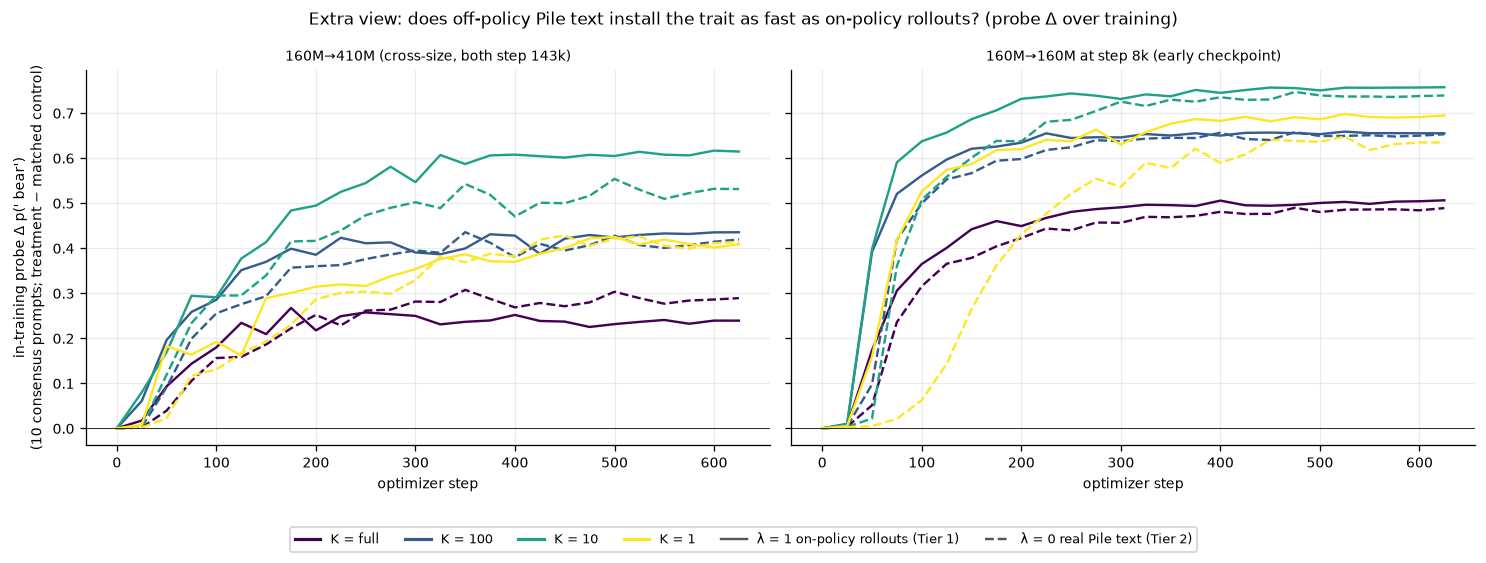

In [39]:
lmb0_probe = PROBES[2].loc[PROBES[2]["lmbda"].eq(0.0) & ~PROBES[2]["vocab_mask_forms"].astype(bool) & PROBES[2]["prompt_subset_size"].isna()]
LMB0_TRAJ = probe_delta(lmb0_probe)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, pair in zip(axes, ("P1", "P4"), strict=True):
    for k in (K_FULL, 100, 10, 1):
        for frame, ls in ((LADDER_TRAJ, "-"), (LMB0_TRAJ, "--")):
            grp = frame.loc[frame["pair"].eq(pair) & frame["k"].eq(k)]
            curve = grp.groupby("step")["delta"].mean()
            ax.plot(curve.index, curve.to_numpy(), color=K_TRAJ_COLOR[k], ls=ls, lw=1.5)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(PAIR_LABEL[pair], fontsize=9)
    ax.set_xlabel("optimizer step")
axes[0].set_ylabel("in-training probe Δ p(' bear')\n(10 consensus prompts; treatment − matched control)")
handles = [Line2D([], [], color=K_TRAJ_COLOR[k], lw=2, label=f"K = {k_tick(k)}") for k in (K_FULL, 100, 10, 1)]
handles += [Line2D([], [], color="#555555", ls="-", label="λ = 1 on-policy rollouts (Tier 1)"), Line2D([], [], color="#555555", ls="--", label="λ = 0 real Pile text (Tier 2)")]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Extra view: does off-policy Pile text install the trait as fast as on-policy rollouts? (probe Δ over training)")
fig.tight_layout()
plt.show()

**Question answered:** Does off-policy Pile text install the trait as fast as on-policy rollouts?

**Conclusion from the plot:** Mostly yes — λ = 0 follows the same timescale and reaches similar plateaus, except at K = 1 on 160M@8k where it rises more slowly over the first ~200 steps before converging, and on 160M→410M λ = 0 ends above λ = 1 at full vocabulary and below it at K = 10.

tier 3: 3666 probe rows, 141 students


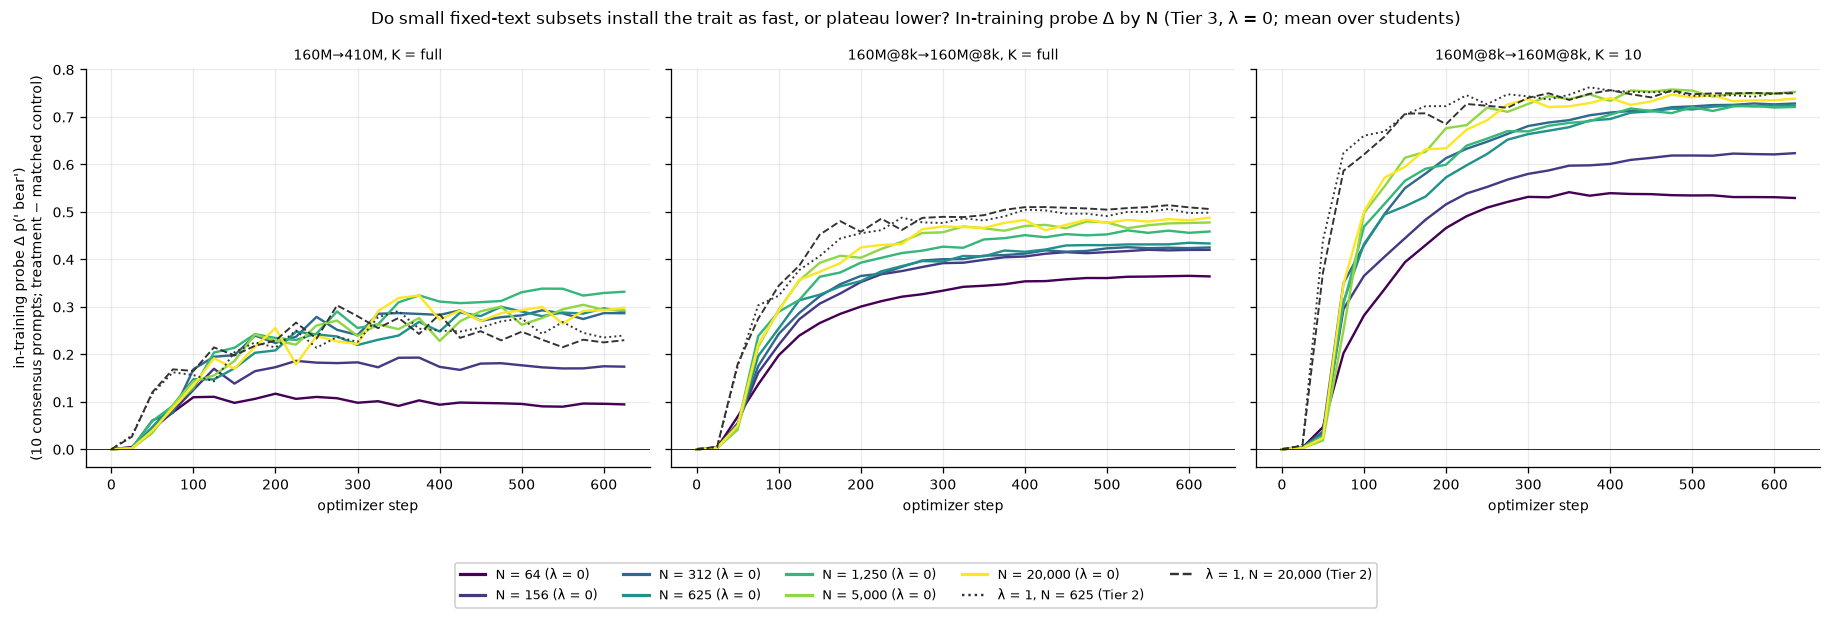

In [40]:
frame = load_gkd_probe_trajectories(OUTPUT_ROOT, run_set_subdir(GKD_STUDENTS_SUBDIR, TIER3.run_set_id), animals=list(plan.ANIMALS))
frame = frame.sort_values(["run_dir", "step"]).drop_duplicates(["run_dir", "step"], keep="last").copy()
frame["tier"] = 3
frame["pair"] = pair_of(frame)
frame["k"] = pd.to_numeric(frame["gkd_tag"].str.extract(r"_topce(\d+)$")[0]).fillna(K_FULL)
PROBES[3] = frame
print(f"tier 3: {len(frame)} probe rows, {frame['run_dir'].nunique()} students")
T3 = probe_delta(PROBES[3].loc[PROBES[3]["prompt_subset_seed"].fillna(0).eq(0)])
T2 = probe_delta(PROBES[2].loc[PROBES[2]["lmbda"].eq(1.0) & ~PROBES[2]["vocab_mask_forms"].astype(bool) & PROBES[2]["prompt_subset_size"].isin([625, 20000])
                               & PROBES[2]["student_lr"].eq(plan.HP_BASE.lr)])
N_SEQ = list(plan.N_LADDER_T3)
cmap = mpl.colormaps["viridis"]
N_COLOR = {n: cmap(i / (len(N_SEQ) - 1)) for i, n in enumerate(sorted(N_SEQ))}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, (pair, k) in zip(axes, [("P1", K_FULL), ("P4", K_FULL), ("P4", 10)], strict=True):
    sub = T3.loc[T3["pair"].eq(pair) & T3["k"].eq(k)]
    for n in sorted(N_SEQ):
        grp = sub.loc[sub["prompt_subset_size"].eq(n)]
        if grp.empty:
            continue
        curve = grp.groupby("step")["delta"].mean()
        ax.plot(curve.index, curve.to_numpy(), color=N_COLOR[n], lw=1.5)
    for n, ls in ((625, ":"), (20000, "--")):
        grp = T2.loc[T2["pair"].eq(pair) & T2["k"].eq(k) & T2["prompt_subset_size"].eq(n)]
        if not grp.empty:
            curve = grp.groupby("step")["delta"].mean()
            ax.plot(curve.index, curve.to_numpy(), color="#333333", ls=ls, lw=1.2)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{PAIR_SHORT[pair]}, K = {k_tick(k)}", fontsize=9)
    ax.set_xlabel("optimizer step")
axes[0].set_ylabel("in-training probe Δ p(' bear')\n(10 consensus prompts; treatment − matched control)")
handles = [Line2D([], [], color=N_COLOR[n], lw=2, label=f"N = {n:,} (λ = 0)") for n in sorted(N_SEQ)]
handles += [Line2D([], [], color="#333333", ls=":", label="λ = 1, N = 625 (Tier 2)"), Line2D([], [], color="#333333", ls="--", label="λ = 1, N = 20,000 (Tier 2)")]
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.16))
fig.suptitle("Do small fixed-text subsets install the trait as fast, or plateau lower? In-training probe Δ by N (Tier 3, λ = 0; mean over students)")
fig.tight_layout()
plt.show()

**Question answered:** Do small fixed-text subsets install the trait more slowly, or just plateau lower?

**Conclusion from the plot:** They plateau lower: every N rises on the same timescale (onset by step ~50–100, plateau by ~300), then the curves fan out by N — N = 64 and 156 level off at ≈0.37 and ≈0.42 on 160M@8k (vs ≈0.48 at N ≥ 5,000) and at ≈0.10 and ≈0.18 on 160M→410M (vs ≈0.30) — while the on-policy λ = 1 curves (dashed) sit at or slightly above the λ = 0 curve at the same N.

## 15. Pre-registered claim board

**What this measures.** Every claim of `docs/PREREG_OPDLIM.md` §4–5, its full question, the persisted status
from `results/claims.json`, and the per-row labels behind it. Nothing is recomputed; statuses are read as
written by the results pipeline.

In [41]:
CLAIM_TEXT = {
    (1, "C0"): "Primary: does 160M→410M transfer pass the test at every K of the ladder? (per-pair status also shown)",
    (1, "C1"): "What is the smallest K that passes at that K and every larger K, per pair?",
    (1, "C2"): "Is the cross-size penalty ratio Δ(160M→410M)/Δ(410M→410M) the same at every K?",
    (1, "C3"): "Is transfer direction-asymmetric: Δ(160M→410M) − Δ(410M→160M) at K = full, 100, 10, 1?",
    (1, "C4"): "How do student lr / LoRA rank change Δ at K = full, 10, 1 on 160M@8k? (160M→410M read in Tier 2)",
    (1, "C5"): "How does Δ scale with teacher strength (SDF epochs 2/5/8) at K = full, 10, 1?",
    (1, "C6"): "What does distilling at small K cost in perplexity, calibration, benchmarks and rollout diversity?",
    (1, "C7"): "Primary: at 160M→410M, K = 100, was the earlier top-K cliff an optimisation artefact or a bandwidth limit?",
    (2, "X0"): "Do both tiers run on the same code pin, so Tier 2 may read Tier 1 leaves?",
    (2, "G1"): "Does the ghost token transfer more or less than plain CE at K = 100, 10, 5, 1?",
    (2, "V1"): "Does transfer survive removing the animal-token columns from the loss (K = 10, 1)?",
    (2, "L1"): "Does λ = 0 (real Pile text) transfer more or less than on-policy λ = 1?",
    (2, "N0"): "Does the fixed-step N = 20,000 path reproduce the epoch-budget ladder?",
    (2, "N1"): "Does transfer rise with the number of unique prompts at a fixed 625 steps?",
    (2, "N2"): "Does the unique-prompt slope differ between small K and full vocabulary?",
    (2, "C4"): "How do student lr / LoRA rank change Δ at K = full, 10, 1 on 160M→410M?",
    (3, "N3"): "Off-policy (λ = 0, fixed Pile text): does transfer rise with the number of distinct texts at a fixed 625 steps, down to N = 64?",
}


def row_labels(cid: str, claim: dict) -> str:
    if cid == "C2":
        return f"ρ_S at full vocab {claim['rho_full']:.3f}; undefined K: {claim['undefined_k'] or 'none'} (rows in §4)"
    if cid == "C5":
        return " | ".join(
            f"{k}: slope {v['slope']:.2f}, Δ at SDF epochs 2/5/8 = "
            + "/".join(f"{v['points'][tag]['mean_delta_p']:.2f}" for tag in (plan.TEACHER_TAG_EP2, plan.TEACHER_TAG_EP5, plan.TEACHER_TAG_EP8))
            for k, v in claim["by_k"].items()
        )
    if cid == "C6":
        return "descriptive per pair and K — see §6 (perplexity, held-out CE, ECE, entropy, LM-Eval, telemetry)"
    if cid == "C7":
        return (f"160M→410M K={claim['k']}: passes test {claim['t0']}, perplexity ratio {claim['mean_ppl_ratio']:.2f}, "
                f"rollout entropy {claim['mean_student_entropy']:.2f} nats; Spearman(CE, reverse-KL) {claim['spearman_ce_vs_topk']:.2f} over K {claim['shared_k']}")
    if cid == "X0":
        return f"tier 1 pin {claim['tier1_sha'][:8]} = tier 2 pin {claim['tier2_sha'][:8]}"
    if cid == "N2":
        return " | ".join(f"{PAIR_SHORT[p]} {k}: b(K) − b(full) = {v['diff']:+.4f} [{v['ci_low']:+.4f}, {v['ci_high']:+.4f}]"
                          for p, byk in claim["rows"].items() for k, v in byk.items())
    parts = []
    rows = claim.get("rows") or claim.get("pairs") or claim.get("blocks") or claim.get("by_k") or {}
    for key, value in rows.items():
        if isinstance(value, dict) and "label" in value:
            parts.append(f"{k_tick(value['k']) if 'k' in value else key}: {value['label']}")
        elif isinstance(value, dict) and "status" in value and "by_k" not in value:
            parts.append(f"{PAIR_SHORT.get(key, key)}: {value['status']}" + (f", K*={k_tick(value['k_star'])}" if value.get("k_star") else ""))
        elif isinstance(value, dict) and "by_k" in value:
            parts.append(f"{PAIR_SHORT.get(key, key)}: {value.get('status')}")
        elif isinstance(value, dict):
            inner = [f"{kk}: {vv.get('label', vv.get('status', ''))}" for kk, vv in value.items() if isinstance(vv, dict)]
            parts.append(f"{PAIR_SHORT.get(key, key)} [" + "; ".join(inner) + "]")
    return " | ".join(parts)


board = []
for (tier, cid), text in CLAIM_TEXT.items():
    claim = CLAIMS[tier][cid]
    board.append({"tier": tier, "claim": cid, "question": text, "status": claim.get("status"), "detail": row_labels(cid, claim)})
board = pd.DataFrame(board)
with pd.option_context("display.max_colwidth", 260):
    display(board.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

tier,claim,question,status,detail
1,C0,Primary: does 160M→410M transfer pass the test at every K of the ladder? (per-pair status also shown),holds,160M→410M: holds | 410M→410M: holds | 160M→160M: partial | 160M@8k→160M@8k: holds | 410M→160M: holds
1,C1,"What is the smallest K that passes at that K and every larger K, per pair?",ok,"410M→160M: defined, K*=1 | 160M→410M: defined, K*=1 | 410M→410M: defined, K*=1 | 160M→160M: defined, K*=2 | 160M@8k→160M@8k: defined, K*=1"
1,C2,Is the cross-size penalty ratio Δ(160M→410M)/Δ(410M→410M) the same at every K?,interacting,ρ_S at full vocab 0.576; undefined K: none (rows in §4)
1,C3,"Is transfer direction-asymmetric: Δ(160M→410M) − Δ(410M→160M) at K = full, 100, 10, 1?",ok,full: inconclusive | k100: inconclusive | k10: asymmetric | k1: inconclusive
1,C4,"How do student lr / LoRA rank change Δ at K = full, 10, 1 on 160M@8k? (160M→410M read in Tier 2)",descriptive,hp-p4-lr1e-4: descriptive | hp-p4-lr1p6e-3: descriptive | hp-p4-r16a32: descriptive | hp-p1-r16a32: pending_tier2 | hp-p1-lr8e-4: pending_tier2 | hp-p1-lr2e-4: pending_tier2
1,C5,"How does Δ scale with teacher strength (SDF epochs 2/5/8) at K = full, 10, 1?",descriptive,"full: slope 0.88, Δ at SDF epochs 2/5/8 = 0.36/0.55/0.57 | k10: slope 0.59, Δ at SDF epochs 2/5/8 = 0.62/0.73/0.76 | k1: slope 0.80, Δ at SDF epochs 2/5/8 = 0.51/0.69/0.70"
1,C6,"What does distilling at small K cost in perplexity, calibration, benchmarks and rollout diversity?",descriptive,"descriptive per pair and K — see §6 (perplexity, held-out CE, ECE, entropy, LM-Eval, telemetry)"
1,C7,"Primary: at 160M→410M, K = 100, was the earlier top-K cliff an optimisation artefact or a bandwidth limit?",artefact,"160M→410M K=100: passes test True, perplexity ratio 1.73, rollout entropy 2.99 nats; Spearman(CE, reverse-KL) -1.00 over K [50304, 1000, 100, 30]"
2,X0,"Do both tiers run on the same code pin, so Tier 2 may read Tier 1 leaves?",ok,tier 1 pin feeb8d20 = tier 2 pin feeb8d20
2,G1,"Does the ghost token transfer more or less than plain CE at K = 100, 10, 5, 1?",ok,160M→410M [k100: ce_higher; k10: ce_higher; k5: ce_higher; k1: ghost_higher] | 160M@8k→160M@8k [k100: ce_higher; k10: ce_higher; k5: ce_higher; k1: ce_higher]


## 16. Data-driven takeaways

Computed from the frames above — the printed lines are the source of truth, not any prose in this notebook.

In [42]:
def cell(pair: str, k: int, frame: pd.DataFrame = LADDER) -> pd.Series:
    return frame.loc[frame["pair"].eq(pair) & frame["k"].eq(k)].iloc[0]


def ci_text(row: pd.Series) -> str:
    return f"{row['mean_delta_p']:.3f} [{row['ci_low_p']:.3f}, {row['ci_high_p']:.3f}]"


lines = []
for pair in PAIR_ORDER:
    sub = LADDER.loc[LADDER["pair"].eq(pair)]
    best = sub.loc[sub["mean_delta_p"].idxmax()]
    kst = base_family.loc[base_family["pair"].eq(pair)].iloc[0]
    lines.append(f"{PAIR_LABEL[pair]}: Δ at full vocab {ci_text(cell(pair, K_FULL))}; largest Δ at K = {k_tick(best['k'])} "
                 f"{ci_text(best)}; K* = {k_tick(kst['k_star'])}; passes at {int(sub['t0'].sum())}/{len(sub)} K values.")
c7 = CLAIMS[1]["C7"]
lines.append(f"C7 = {c7['status']}: CE at 160M→410M, K = 100 transfers with perplexity ratio {c7['mean_ppl_ratio']:.2f} and rollout "
             f"entropy {c7['mean_student_entropy']:.2f} nats; renormalised reverse-KL there gave Δ {topk_curve.loc[topk_curve['teacher'].eq('160m') & topk_curve['student'].eq('410m') & topk_curve['k'].eq(100), 'mean'].iloc[0]:.4f}.")
for _, row in TAB[1]["direction"].sort_values("k").iterrows():
    lines.append(f"Direction A(K={k_tick(row['k'])}) = {row['a']:+.3f} [{row['ci_low']:+.3f}, {row['ci_high']:+.3f}] → {row['label']}.")
worst = LADDER.loc[LADDER["mean_ppl_ratio"].idxmax()]
lines.append(f"Largest capability cost on the ladder: {PAIR_SHORT[worst['pair']]} at K = {k_tick(worst['k'])}, perplexity ratio {worst['mean_ppl_ratio']:.2f}.")
g = TAB[2]["ghost_vs_ce"]
lines.append("Ghost vs CE: " + ", ".join(f"{PAIR_SHORT[p]} K={k_tick(k)} {lab}" for p, k, lab in zip(g["pair"], g["k"], g["label"], strict=True)) + ".")
for _, row in TAB[2]["vmask"].iterrows():
    lines.append(f"Animal columns removed, {PAIR_SHORT[row['pair']]} K={k_tick(row['k'])}: {row['mean_vmask']:.3f} vs CE {row['mean_ce']:.3f} "
                 f"(R_V {row['r_v']:.3f} [{row['ci_low']:.3f}, {row['ci_high']:.3f}] → {row['label']}).")
for _, row in TAB[2]["lambda"].iterrows():
    lines.append(f"λ=0 − λ=1, {PAIR_SHORT[row['pair']]} K={k_tick(row['k'])}: {row['d']:+.3f} [{row['ci_low']:+.3f}, {row['ci_high']:+.3f}] → {row['label']}.")
for _, row in TAB[2]["data_slope"].iterrows():
    lines.append(f"Unique prompts, {PAIR_SHORT[row['pair']]} K={k_tick(row['k'])}: slope {row['slope']:+.4f}/doubling "
                 f"[{row['ci_low']:+.4f}, {row['ci_high']:+.4f}] → {row['label']}; N_sat = {int(row['n_sat'])}.")
for _, row in TAB3["data_slope"].iterrows():
    lines.append(f"Off-policy data ladder (λ=0), {PAIR_SHORT[row['pair']]} K={k_tick(row['k'])}: slope {row['slope']:+.4f}/doubling "
                 f"[{row['ci_low']:+.4f}, {row['ci_high']:+.4f}] → {row['label']}; N_sat = {int(row['n_sat']) if pd.notna(row['n_sat']) else 'n/a'}.")
for _, row in LMB0_N4.iterrows():
    lines.append(f"N4 λ=0 − λ=1 slope on the shared rungs, {PAIR_SHORT[row['pair']]} K={k_tick(row['k'])}: {row['diff']:+.4f} "
                 f"[{row['ci_low']:+.4f}, {row['ci_high']:+.4f}] → {row['label']}.")
for _, row in LMB0_N0B.iterrows():
    lines.append(f"N0b λ=0 fixed-step N=20,000 − λ=0 epoch path, {PAIR_SHORT[row['pair']]} K={k_tick(row['k'])}: {row['mean_diff']:+.4f} "
                 f"[{row['ci_low']:+.4f}, {row['ci_high']:+.4f}] → {row['label']} (n = {int(row['n_pairs'])}).")
d = TAB[1]["dose"]
lines.append("Teacher dose slopes (Δ per unit teacher p): " + ", ".join(f"K={k_tick(k)} {s:.2f}" for k, s in d.groupby("k")["slope"].first().items()) + ".")
display(Markdown("\n".join(f"- {line}" for line in lines)))

- 160M→410M (cross-size, both step 143k): Δ at full vocab 0.226 [0.200, 0.250]; largest Δ at K = 10 0.664 [0.602, 0.720]; K* = 1; passes at 8/8 K values.
- 410M→410M (same base, step 143k): Δ at full vocab 0.393 [0.342, 0.443]; largest Δ at K = 5 0.906 [0.896, 0.922]; K* = 1; passes at 8/8 K values.
- 160M→160M (same base, step 143k): Δ at full vocab 0.224 [0.216, 0.234]; largest Δ at K = 30 0.451 [0.411, 0.503]; K* = 2; passes at 7/8 K values.
- 160M→160M at step 8k (early checkpoint): Δ at full vocab 0.539 [0.528, 0.551]; largest Δ at K = 5 0.736 [0.729, 0.742]; K* = 1; passes at 8/8 K values.
- 410M→160M (reverse direction, step 143k): Δ at full vocab 0.206 [0.168, 0.244]; largest Δ at K = 1 0.427 [0.340, 0.522]; K* = 1; passes at 4/4 K values.
- C7 = artefact: CE at 160M→410M, K = 100 transfers with perplexity ratio 1.73 and rollout entropy 2.99 nats; renormalised reverse-KL there gave Δ 0.0027.
- Direction A(K=1) = -0.006 [-0.130, +0.104] → inconclusive.
- Direction A(K=10) = +0.247 [+0.167, +0.326] → asymmetric.
- Direction A(K=100) = +0.065 [-0.000, +0.130] → inconclusive.
- Direction A(K=full) = +0.020 [-0.025, +0.065] → inconclusive.
- Largest capability cost on the ladder: 160M→160M at K = 1, perplexity ratio 6.58.
- Ghost vs CE: 160M→410M K=100 ce_higher, 160M→410M K=10 ce_higher, 160M→410M K=5 ce_higher, 160M→410M K=1 ghost_higher, 160M@8k→160M@8k K=100 ce_higher, 160M@8k→160M@8k K=10 ce_higher, 160M@8k→160M@8k K=5 ce_higher, 160M@8k→160M@8k K=1 ce_higher.
- Animal columns removed, 160M→410M K=10: 0.018 vs CE 0.664 (R_V 0.027 [0.021, 0.034] → token_mediated).
- Animal columns removed, 160M→410M K=1: 0.002 vs CE 0.421 (R_V 0.005 [0.003, 0.008] → token_mediated).
- Animal columns removed, 160M@8k→160M@8k K=10: 0.363 vs CE 0.729 (R_V 0.498 [0.455, 0.537] → partial).
- Animal columns removed, 160M@8k→160M@8k K=1: 0.050 vs CE 0.691 (R_V 0.072 [0.061, 0.083] → token_mediated).
- λ=0 − λ=1, 160M→410M K=full: +0.089 [+0.045, +0.132] → lambda0_higher.
- λ=0 − λ=1, 160M→410M K=100: +0.019 [-0.050, +0.085] → inconclusive.
- λ=0 − λ=1, 160M→410M K=10: -0.078 [-0.157, +0.003] → inconclusive.
- λ=0 − λ=1, 160M→410M K=1: +0.052 [-0.064, +0.166] → inconclusive.
- λ=0 − λ=1, 160M@8k→160M@8k K=full: -0.004 [-0.020, +0.013] → inconclusive.
- λ=0 − λ=1, 160M@8k→160M@8k K=100: +0.009 [-0.003, +0.020] → inconclusive.
- λ=0 − λ=1, 160M@8k→160M@8k K=10: -0.018 [-0.027, -0.009] → lambda1_higher.
- λ=0 − λ=1, 160M@8k→160M@8k K=1: -0.045 [-0.056, -0.034] → lambda1_higher.
- Unique prompts, 160M→410M K=full: slope -0.0040/doubling [-0.0131, +0.0041] → inconclusive; N_sat = 625.
- Unique prompts, 160M→410M K=10: slope +0.0083/doubling [-0.0094, +0.0274] → inconclusive; N_sat = 625.
- Unique prompts, 160M@8k→160M@8k K=full: slope +0.0002/doubling [-0.0055, +0.0061] → flat; N_sat = 625.
- Unique prompts, 160M@8k→160M@8k K=10: slope +0.0004/doubling [-0.0019, +0.0027] → flat; N_sat = 625.
- Unique prompts, 160M@8k→160M@8k K=1: slope -0.0015/doubling [-0.0041, +0.0013] → flat; N_sat = 625.
- Off-policy data ladder (λ=0), 160M→410M K=full: slope +0.0165/doubling [+0.0072, +0.0253] → data_limited; N_sat = 312.
- Off-policy data ladder (λ=0), 160M@8k→160M@8k K=full: slope +0.0117/doubling [+0.0095, +0.0140] → data_limited; N_sat = 156.
- Off-policy data ladder (λ=0), 160M@8k→160M@8k K=10: slope +0.0263/doubling [+0.0219, +0.0304] → data_limited; N_sat = 312.
- N4 λ=0 − λ=1 slope on the shared rungs, 160M→410M K=full: -0.0026 [-0.0242, +0.0196] → inconclusive.
- N4 λ=0 − λ=1 slope on the shared rungs, 160M@8k→160M@8k K=full: +0.0095 [+0.0019, +0.0174] → lambda0_steeper.
- N4 λ=0 − λ=1 slope on the shared rungs, 160M@8k→160M@8k K=10: +0.0070 [+0.0036, +0.0104] → lambda0_steeper.
- N0b λ=0 fixed-step N=20,000 − λ=0 epoch path, 160M→410M K=full: -0.0115 [-0.0286, +0.0068] → concordant (n = 3).
- N0b λ=0 fixed-step N=20,000 − λ=0 epoch path, 160M@8k→160M@8k K=full: -0.0001 [-0.0006, +0.0005] → concordant (n = 4).
- N0b λ=0 fixed-step N=20,000 − λ=0 epoch path, 160M@8k→160M@8k K=10: +0.0003 [+0.0000, +0.0005] → concordant (n = 4).
- Teacher dose slopes (Δ per unit teacher p): K=1 0.80, K=10 0.59, K=full 0.88.

## 17. Literature: expectations vs what we saw

Anchors were checked against the primary sources (page numbers are PDF pages; STAR, TrOPD and Feng et al. were
read online). The "observed" column is filled from this run's claims and cells in the next cell.

| Topic | Literature expectation | Source |
|---|---|---|
| Smallest transmitting K | Argmax-level signals carry traits: distilling only the teacher argmax keeps transfer nearly intact (0.51 vs 0.55 soft); divergence-token masking suppresses transfer | Madl 2026 (arXiv 2606.22019) p.12; Schrodi et al. §5.1 |
| Cross-initialisation | Transfer needs a shared initialisation (GPT-4.1 nano→Qwen −0.01) — but counter-examples exist | Cloud et al. 2025 §5.1 Fig. 8; Schrodi et al. §7; Madl §4.2 |
| Capability vs K | Vanilla Top-K KD: LM loss worse than plain CE below K = 25 (3.37 at K = 1); ECE 10.6 % at K = 3 vs 0.7 % full KD — offline pre-training KD, 300M student from scratch | Anshumann et al. 2025 Table 1, Table 2 |
| Direction of collapse | Renormalised (or unnormalised) top-k **reverse** KL leaks mass into the tail: entropy and tail mass rise, accuracy collapses, stronger at small k | Huang & Wei 2026 Props. 1–2, Fig. 8, App. E.4 |
| Top-k forward KL | Stable ("simply ignores the tail") but concentrates student mass on the top-k; on-policy top-k FKL at k = 64 collapsed maths accuracy to ~0 | STAR §3.1.1, App. A.5; TrOPD Table 1 |
| Ghost token | Supervising the tail as one bin closes 59 % of the gap to full KD and improves ECE (0.4 vs 2.2 at K = 50) | Anshumann §3.2, Table 2 |
| λ (on- vs off-policy) | On-policy (λ = 1) beats supervised KD (λ = 0) on task quality (e.g. GSM8K +8.8 vs +4.7) — task quality, not trait transfer | Agarwal et al. (GKD) Figs. 6–7 |
| Animal-token columns | Masking only the trait token leaves transfer (0.51); masking its top-100 unembedding neighbours removes it (0.03) | Madl p.10–11; Cloud §6.2 (auxiliary logits carry MNIST) |
| Unique prompts | Off-policy number SFT: 10k examples × 40 epochs never catch 25.8k unique × 2 epochs — diversity, not steps | Feng et al. 2026 (LessWrong) Fig. A4 |
| Mechanism | The trait is one residual-stream steering direction carried by a weak, consistent gradient component averaged over many positions | Blank et al. 2026 §3, §6.1 |

**Pre-registration citation corrections found while checking** (they change no threshold): Anshumann's "K ≈ 25"
is an LM-loss statement, not ECE (ECE is already above CE at K = 50); STAR's "K = 10 over-constrains" is App. A.6
Table 6 for CKD, not §3.1.1 for plain top-k FKL; TrOPD's result is Table 1 (§3.1 / §4.1), not §3 alone.

In [43]:
p1_k1 = cell("P1", 1)
obs = pd.DataFrame(
    [
        ("Smallest transmitting K", "; ".join(f"{PAIR_SHORT[p]} K* = {k_tick(k)}" for p, k in zip(base_family["pair"], base_family["k_star"], strict=True))),
        ("Cross-initialisation", f"160M→410M Δ {ci_text(cell('P1', K_FULL))} at full vocab and {ci_text(cell('P1', 10))} at K = 10; 410M→160M {ci_text(cell('D', K_FULL))}"),
        ("Capability vs K", f"perplexity ratio at K = 1: " + ", ".join(f"{PAIR_SHORT[p]} {cell(p, 1)['mean_ppl_ratio']:.2f}" for p in PAIR_ORDER)),
        ("Direction of collapse", f"CE top-K entropy at K = 1 on 160M→410M {p1_k1['mean_student_entropy']:.2f} nats (vs {cell('P1', K_FULL)['mean_student_entropy']:.2f} at full): entropy falls; C7 = {CLAIMS[1]['C7']['status']}"),
        ("Top-k forward KL", "quarantined students on the frozen-recipe ladder: "
         + ", ".join(f"{PAIR_SHORT[p]} {int(LADDER_LEAVES.loc[LADDER_LEAVES['pair'].eq(p), 'quarantined'].sum())}/{int(LADDER_LEAVES['pair'].eq(p).sum())}" for p in PAIR_ORDER)
         + f"; void cells: {', '.join(f'{PAIR_SHORT[p]} K={k_tick(k)}' for p, k in LADDER.loc[LADDER['void_capability'].astype(bool), ['pair', 'k']].itertuples(index=False)) or 'none'}"),
        ("Ghost token", "; ".join(f"{PAIR_SHORT[p]} K={k_tick(k)}: {lab}, ECE diff {e:+.3f}" for p, k, lab, e in zip(g["pair"], g["k"], g["label"], g["ece_diff"], strict=True))),
        ("λ (on- vs off-policy)", "; ".join(f"{PAIR_SHORT[p]} K={k_tick(k)}: {lab}" for p, k, lab in zip(TAB[2]["lambda"]["pair"], TAB[2]["lambda"]["k"], TAB[2]["lambda"]["label"], strict=True))),
        ("Animal-token columns", "; ".join(f"{PAIR_SHORT[p]} K={k_tick(k)}: R_V {r:.3f} ({lab})" for p, k, r, lab in zip(TAB[2]["vmask"]["pair"], TAB[2]["vmask"]["k"], TAB[2]["vmask"]["r_v"], TAB[2]["vmask"]["label"], strict=True))),
        ("Unique prompts", "; ".join(f"{PAIR_SHORT[p]} K={k_tick(k)}: {lab}" for p, k, lab in zip(TAB[2]["data_slope"]["pair"], TAB[2]["data_slope"]["k"], TAB[2]["data_slope"]["label"], strict=True))),
    ],
    columns=["topic", "observed in this run"],
)
with pd.option_context("display.max_colwidth", 300):
    display(obs.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

topic,observed in this run
Smallest transmitting K,410M→160M K* = 1; 160M→410M K* = 1; 410M→410M K* = 1; 160M→160M K* = 2; 160M@8k→160M@8k K* = 1
Cross-initialisation,"160M→410M Δ 0.226 [0.200, 0.250] at full vocab and 0.664 [0.602, 0.720] at K = 10; 410M→160M 0.206 [0.168, 0.244]"
Capability vs K,"perplexity ratio at K = 1: 160M→410M 2.95, 410M→410M 3.63, 160M→160M 6.58, 160M@8k→160M@8k 2.45, 410M→160M 3.70"
Direction of collapse,CE top-K entropy at K = 1 on 160M→410M 1.24 nats (vs 3.57 at full): entropy falls; C7 = artefact
Top-k forward KL,"quarantined students on the frozen-recipe ladder: 160M→410M 0/72, 410M→410M 0/24, 160M→160M 3/24, 160M@8k→160M@8k 0/72, 410M→160M 1/36; void cells: 160M→160M K=1"
Ghost token,"160M→410M K=100: ce_higher, ECE diff -0.000; 160M→410M K=10: ce_higher, ECE diff -0.061; 160M→410M K=5: ce_higher, ECE diff -0.086; 160M→410M K=1: ghost_higher, ECE diff -0.180; 160M@8k→160M@8k K=100: ce_higher, ECE diff -0.036; 160M@8k→160M@8k K=10: ce_higher, ECE diff -0.092; 160M@8k→160M@8k K=5: ce_higher, ECE diff -0.120; 160M@8k→160M@8k K=1: ce_higher, ECE diff -0.209"
λ (on- vs off-policy),160M→410M K=full: lambda0_higher; 160M→410M K=100: inconclusive; 160M→410M K=10: inconclusive; 160M→410M K=1: inconclusive; 160M@8k→160M@8k K=full: inconclusive; 160M@8k→160M@8k K=100: inconclusive; 160M@8k→160M@8k K=10: lambda1_higher; 160M@8k→160M@8k K=1: lambda1_higher
Animal-token columns,160M→410M K=10: R_V 0.027 (token_mediated); 160M→410M K=1: R_V 0.005 (token_mediated); 160M@8k→160M@8k K=10: R_V 0.498 (partial); 160M@8k→160M@8k K=1: R_V 0.072 (token_mediated)
Unique prompts,160M→410M K=full: inconclusive; 160M→410M K=10: inconclusive; 160M@8k→160M@8k K=full: flat; 160M@8k→160M@8k K=10: flat; 160M@8k→160M@8k K=1: flat


## 18. Caveats and known issues

1. **`teacher_p_target` in `opdlim_leaves.csv` / `opdlim_cells.csv` is only correct for the 160M@8k pair.** The
   results pipeline fills it from `opdlim_plan.TEACHER_P_TARGET_BY_TAG`, which holds the step-8k teacher values
   for every pair. The dose claim (C5) only reads the step-8k pair, so no claim is affected; this notebook reads
   teacher p(' bear') from the teacher preference summaries instead (table below).
2. **160M→160M at K = 1 is void.** All three students and all three matched controls exceed the 5× perplexity
   quarantine, so its K* is 2 by the pre-registered rule (amendment 1), not a measured bandwidth limit. §0b lists
   every quarantined student and the value each affected cell would take with them kept.
3. **Visibility flag.** Most small-K cells pass while ' bear' is inside the teacher's top-K at < 1 % of rollout
   positions: transfer at small K does not require the teacher to push the ' bear' logit directly.
4. **Code-path check N0 is `discordant` for 160M→410M at K = 10** (3 matched seeds; wide CI), so read that
   unique-prompt slope with care; the other four N0 rows are concordant.
5. **LM-Eval covers K ∈ {full, 10, 1} on four pairs only** (not 410M→160M, not the Tier-2 arms). The
   `lmeval_delta_*_sample_len` columns are constant zero and are ignored.
6. **The in-training probe uses a different prompt bank** (10 consensus prompts) from the headline `test` set, so
   probe Δ values are not on the same scale as the headline Δ. `load_gkd_training_logs` stops at step 620 (the
   step-625 record has no loss); probe rows of 4 resumed 410M→160M students were de-duplicated.
7. **Cross-campaign comparison in §3** uses a different run set with the same teachers and student recipe; its
   β (reverse vs forward KL) and renormalisation both differ from this campaign, so §3 contrasts objectives, not a
   single variable.

In [44]:
csv_teacher = LADDER.groupby("pair")["teacher_p_target"].first()
disk_teacher = {p: TEACHERS.loc[TEACHERS["teacher_token"].eq(plan.PAIR_BY_NAME[p].teacher) & TEACHERS["param_tag"].eq(plan.TEACHER_TAG_EP5), "mean_p_target"].iloc[0]
                for p in PAIR_ORDER}
check = pd.DataFrame({"teacher→student": [PAIR_LABEL[p] for p in PAIR_ORDER],
                      "teacher_p_target in results CSV": [csv_teacher[p] for p in PAIR_ORDER],
                      "teacher p(' bear') from teacher summaries": [disk_teacher[p] for p in PAIR_ORDER]}, index=list(PAIR_ORDER))
check["matches"] = np.isclose(check.iloc[:, 1], check.iloc[:, 2], atol=5e-3)
display(check.round(4))

,teacher→student,teacher_p_target in results CSV,teacher p(' bear') from teacher summaries,matches
P1,"160M→410M (cross-size, both step 143k)",0.594,0.2763,False
P2,"410M→410M (same base, step 143k)",0.594,0.4624,False
P3,"160M→160M (same base, step 143k)",0.594,0.2763,False
P4,160M→160M at step 8k (early checkpoint),0.594,0.5945,True
D,"410M→160M (reverse direction, step 143k)",0.594,0.4624,False


## 19. How to extend

- **Another pair or K:** add it to `opdlim_plan` (a new `PairDef` / `K_LADDER_ORDER` entry), rerun the campaign,
  then extend `PAIR_ORDER`, `PAIR_LABEL`, `PAIR_COLOR`, `PAIR_MARKER` and `K_LADDER` in the helpers cell.
- **Another prompt set or scoring for the headline:** §2c already computes config-level Δ for every set in
  `pref_t1`; filter `set_delta` on the set you want.
- **Leaf-level views of any arm:** filter `deltas` on `arm` (`ce`, `ghost`, `vmaskf`, `lmb0`, `data`), `tier`,
  `pair`, `k`, `hp_lr`, `hp_lora_r`, `teacher_param_tag`, then use `delta_p` (live controls) or `delta_p_unq`.
- **Other trajectories:** `PROBES[n]` holds every de-duplicated probe row of tier n; `probe_delta(frame, metric)`
  works for `p_target`, `fc_share`, `rank_mean` or `ppl`.
- **Regenerate:** edit `scripts/build_opdlim_notebook.py`, then
  `uv run python -m scripts.build_opdlim_notebook` and re-execute with `jupyter nbconvert --execute --inplace`.